# Sistema NLP de Apoio à Avaliação de Redações do ENEM

## Objetivo

Desenvolver uma solução baseada em Processamento de Linguagem Natural
para apoiar a avaliação de redações do ENEM considerando individualmente
as cinco competências avaliativas.

A solução combinará:

- NLP linguístico;
- análise semântica;
- Machine Learning tradicional;
- Transformers;
- evidências textuais de apoio ao avaliador.

## Dataset

AES-ENEM Dataset  
Configuração utilizada: JBCS2025

## Arquitetura principal

- spaCy
- Sentence Transformers
- XGBoost
- BERTimbau

# 1 - Preparando o Ambiente

In [ ]:
# ============================================================
# INSTALAÇÃO DAS DEPENDÊNCIAS DO PROJETO
# ============================================================
#
# datasets              -> acesso ao dataset AES-ENEM no Hugging Face
# transformers          -> BERTimbau e tokenizadores
# sentence-transformers -> embeddings e similaridade semântica
# accelerate            -> suporte ao treinamento com GPU
# spacy                 -> processamento linguístico em português
# scikit-learn          -> métricas e ferramentas de ML
# xgboost               -> nosso baseline de Machine Learning
# pandas / numpy        -> manipulação de dados
# matplotlib            -> visualizações
# gradio                -> interface final dentro do Colab
# joblib                -> persistência dos modelos
#
# O -q deixa a instalação menos verbosa.

!pip install -q \
    datasets \
    transformers \
    sentence-transformers \
    accelerate \
    spacy \
    scikit-learn \
    xgboost \
    pandas \
    numpy \
    matplotlib \
    gradio \
    joblib

In [ ]:
# ============================================================
# MODELO DE NLP DO SPACY PARA PORTUGUÊS
# ============================================================
#
# Esse modelo será usado posteriormente para:
#
# - tokenização;
# - identificação de sentenças;
# - lematização;
# - classes gramaticais (POS);
# - análise de dependências;
# - reconhecimento de entidades.
#
# Usaremos inicialmente a versão "small" por ser leve e adequada
# para o Colab.

!python -m spacy download pt_core_news_sm -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.0/13.0 MB 73.4 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('pt_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
# ============================================================
# IMPORTS GERAIS DO PROJETO
# ============================================================

# Bibliotecas padrão do Python
import os
import re
import json
import math
import random
import warnings

# Manipulação de dados
import numpy as np
import pandas as pd

# Visualização
import matplotlib.pyplot as plt

# Deep Learning
import torch

# NLP
import spacy

# Hugging Face
from datasets import load_dataset

# Métricas
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    cohen_kappa_score
)

# XGBoost
from xgboost import XGBRegressor

# Evita excesso de warnings no notebook
warnings.filterwarnings("ignore")

print("Imports realizados com sucesso.")

Imports realizados com sucesso.


In [ ]:
# ============================================================
# REPRODUTIBILIDADE
# ============================================================
#
# Utilizamos uma seed fixa para reduzir variações entre execuções.
# Isso influencia:
#
# - NumPy;
# - Python random;
# - PyTorch;
# - treinamento dos modelos posteriormente.

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Se houver GPU, configuramos a seed nela também.
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Seed definida:", SEED)

Seed definida: 42


In [ ]:
# ============================================================
# VERIFICAÇÃO DO AMBIENTE DE EXECUÇÃO
# ============================================================
#
# O início do projeto pode ser executado apenas com CPU.
#
# Para o treinamento do BERTimbau, entretanto, uma GPU será
# bastante importante.

print("Versão do PyTorch:", torch.__version__)
print("CUDA disponível:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Nenhuma GPU detectada.")
    print("Quando chegarmos ao BERTimbau, ative GPU no Colab.")

Versão do PyTorch: 2.11.0+cu130
CUDA disponível: True
GPU: Tesla T4


In [ ]:
# ============================================================
# ESTRUTURA DE DIRETÓRIOS
# ============================================================
#
# Mesmo trabalhando no Colab, vamos organizar nossos artefatos.
#
# data    -> dados processados
# models  -> modelos treinados
# reports -> tabelas e resultados
# outputs -> resultados das análises

PROJECT_ROOT = "/content/enem_nlp"

PATHS = {
    "data": os.path.join(PROJECT_ROOT, "data"),
    "models": os.path.join(PROJECT_ROOT, "models"),
    "reports": os.path.join(PROJECT_ROOT, "reports"),
    "outputs": os.path.join(PROJECT_ROOT, "outputs"),
}

# Cria os diretórios caso ainda não existam.
for path in PATHS.values():
    os.makedirs(path, exist_ok=True)

print("Estrutura criada:")
for name, path in PATHS.items():
    print(f"{name:10s} -> {path}")

Estrutura criada:
data       -> /content/enem_nlp/data
models     -> /content/enem_nlp/models
reports    -> /content/enem_nlp/reports
outputs    -> /content/enem_nlp/outputs


In [ ]:
# ============================================================
# TESTE DO SPACY
# ============================================================

# Carrega o modelo de português.
nlp = spacy.load("pt_core_news_sm")

# Frase simples apenas para validar o funcionamento.
texto_teste = (
    "O Ministério da Educação deve promover políticas públicas "
    "para melhorar a educação brasileira."
)

doc = nlp(texto_teste)

# Exibe token e classe gramatical.
for token in doc:
    print(
        f"{token.text:15s}",
        token.pos_
    )

O               DET
Ministério      PROPN
da              ADP
Educação        PROPN
deve            VERB
promover        VERB
políticas       NOUN
públicas        ADJ
para            SCONJ
melhorar        VERB
a               DET
educação        NOUN
brasileira      ADJ
.               PUNCT


# 2 - Carga e Compreensão do Dataset AES-ENEM

**Objetivo**

Neste bloco iremos:

- carregar o dataset diretamente do Hugging Face;
- utilizar a configuração JBCS2025;
- preservar os splits oficiais de treino, validação e teste;
- inspecionar o schema;
- visualizar uma redação real;
- transformar os dados em DataFrames;
- expandir as notas das cinco competências;
- validar a consistência das notas.

In [ ]:
# ============================================================
# CONFIGURAÇÃO DO DATASET
# ============================================================
#
# O dataset está disponível no Hugging Face.
#
# DATASET_NAME   -> identificador do dataset
# DATASET_CONFIG -> subconjunto/configuração que utilizaremos
#
# Neste projeto usaremos o JBCS2025.

DATASET_NAME = "kamel-usp/aes_enem_dataset"
DATASET_CONFIG = "JBCS2025"

print("Dataset:", DATASET_NAME)
print("Configuração:", DATASET_CONFIG)

Dataset: kamel-usp/aes_enem_dataset
Configuração: JBCS2025


In [ ]:
# ============================================================
# DOWNLOAD DO DATASET
# ============================================================
#
# load_dataset() fará automaticamente:
#
# 1. download dos arquivos;
# 2. armazenamento em cache no ambiente do Colab;
# 3. carregamento dos splits disponíveis.
#
# IMPORTANTE:
# não precisamos baixar CSV manualmente.

dataset = load_dataset(
    DATASET_NAME,
    DATASET_CONFIG
)

print("Dataset carregado com sucesso.")

README.md:   0%|          | 0.00/7.27k [00:00<?, ?B/s]

JBCS2025/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  348kB            

JBCS2025/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

JBCS2025/validation-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B /  105kB            

JBCS2025/validation-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

...

JBCS2025/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/500 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/132 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/138 [00:00<?, ? examples/s]

Dataset carregado com sucesso.


In [ ]:
# ============================================================
# ESTRUTURA GERAL DO DATASET
# ============================================================
#
# Queremos verificar quais splits foram disponibilizados
# oficialmente pelo próprio dataset.

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['id', 'id_prompt', 'essay_text', 'grades', 'essay_year', 'supporting_text', 'prompt', 'reference'],
        num_rows: 500
    })
    validation: Dataset({
        features: ['id', 'id_prompt', 'essay_text', 'grades', 'essay_year', 'supporting_text', 'prompt', 'reference'],
        num_rows: 132
    })
    test: Dataset({
        features: ['id', 'id_prompt', 'essay_text', 'grades', 'essay_year', 'supporting_text', 'prompt', 'reference'],
        num_rows: 138
    })
})


In [ ]:
# ============================================================
# TAMANHO DOS SPLITS
# ============================================================
#
# Esta informação é importante porque NÃO criaremos
# novos splits aleatórios.
#
# Vamos utilizar exatamente:
#
# train      -> treinamento
# validation -> ajuste e seleção do modelo
# test       -> avaliação final

for split_name in dataset.keys():
    print(
        f"{split_name:12s}: "
        f"{len(dataset[split_name]):4d} registros"
    )

train       :  500 registros
validation  :  132 registros
test        :  138 registros


In [ ]:
# ============================================================
# SCHEMA DO DATASET
# ============================================================
#
# Aqui verificamos quais campos estão disponíveis
# em cada registro.

dataset["train"].features

{'id': Value('string'),
 'id_prompt': Value('string'),
 'essay_text': Value('string'),
 'grades': List(Value('int16')),
 'essay_year': Value('int16'),
 'supporting_text': Value('string'),
 'prompt': Value('string'),
 'reference': Value('string')}

In [ ]:
# ============================================================
# PRIMEIRO REGISTRO
# ============================================================
#
# Antes de criar qualquer transformação, queremos entender
# exatamente como uma redação é representada no dataset.

example = dataset["train"][0]

example

{'id': '8.html',
 'id_prompt': 'posse-de-armas-mais-seguranca-ou-mais-perigo',
 'essay_text': 'O Brasil vive uma epidemia de homicídios nas últimas décadas. A violência é comum a países com alto grau de desigualdade social - como o Brasil.\nO decreto que flexibiliza a posse de arma, bem como, os anseios de uma parcela da população que concorda com este, põe em cheque a fragilidade do estado em garantir a segurança aos cidadãos pagadores de impostos. \nA violência escancarada nos jornais não é resultado da falta de armas e sim do excesso delas, principalmente por estarem “nas mãos erradas”. Outro fator que corrobora com o aumento da violência é a falta de investimentos em educação e emprego. Uma população sem expectativas, sem oportunidades, se torna muito mais vulnerável e atraída para o tráfico de drogas, armas, etc.\nPortanto, para conter a escalada do número de homicídios, é preciso ir além de decretos e leis que “joguem” ainda mais armas diante de uma população que carece do básico

In [ ]:
# ============================================================
# VISUALIZAÇÃO DE UMA REDAÇÃO
# ============================================================

example = dataset["train"][0]

print("=" * 80)
print("TEMA / PROPOSTA")
print("=" * 80)
print(example["prompt"])

print()

print("=" * 80)
print("REDAÇÃO")
print("=" * 80)
print(example["essay_text"])

print()

print("=" * 80)
print("NOTAS")
print("=" * 80)
print(example["grades"])

TEMA / PROPOSTA
No dia 15 do mês de janeiro passado, o presidente Jair Bolsonaro assinou o decreto que facilita a posse de armas no Brasil, em meio a críticas a governos anteriores. A medida foi publicada em edição extra do “Diário Oficial da União” e teve efeito imediato. Já está em vigor. Facilitar o acesso às armas de fogo foi uma das bandeiras de campanha de Bolsonaro, quando candidato, em nome do direito à legítima defesa. No entanto, a posse de armas é uma questão muito polêmica. Com a ajuda dos argumentos apresentados na coletânea e com suas próprias ideias sobre o assunto, redija uma dissertação argumentativa, posicionando-se em relação ao decreto presidencial: você acha que ele aumentará a segurança dos cidadãos ou vai aumentar o nível de violência no campo e nas cidades brasileiras?

REDAÇÃO
O Brasil vive uma epidemia de homicídios nas últimas décadas. A violência é comum a países com alto grau de desigualdade social - como o Brasil.
O decreto que flexibiliza a posse de arma,

In [ ]:
# ============================================================
# INTERPRETAÇÃO DAS NOTAS
# ============================================================
#
# A expectativa é que grades contenha:
#
# posição 0 -> C1
# posição 1 -> C2
# posição 2 -> C3
# posição 3 -> C4
# posição 4 -> C5
# posição 5 -> nota total

grades = example["grades"]

print("C1:", grades[0])
print("C2:", grades[1])
print("C3:", grades[2])
print("C4:", grades[3])
print("C5:", grades[4])
print("Total:", grades[5])

C1: 160
C2: 120
C3: 120
C4: 120
C5: 80
Total: 600


In [ ]:
# ============================================================
# CONVERSÃO PARA DATAFRAMES
# ============================================================
#
# O Hugging Face Dataset é ótimo para treinamento.
#
# Para análise exploratória e feature engineering,
# Pandas será mais confortável.

df_train = dataset["train"].to_pandas()
df_val = dataset["validation"].to_pandas()
df_test = dataset["test"].to_pandas()

print("Train      :", df_train.shape)
print("Validation :", df_val.shape)
print("Test       :", df_test.shape)

Train      : (500, 8)
Validation : (132, 8)
Test       : (138, 8)


In [ ]:
# ============================================================
# COLUNAS DISPONÍVEIS
# ============================================================

print("Colunas disponíveis:")

for column in df_train.columns:
    print("-", column)

Colunas disponíveis:
- id
- id_prompt
- essay_text
- grades
- essay_year
- supporting_text
- prompt
- reference


In [ ]:
# ============================================================
# EXPANSÃO DAS COMPETÊNCIAS
# ============================================================
#
# Em vez de trabalhar com:
#
# grades = [160, 120, 160, 120, 160, 720]
#
# queremos:
#
# C1    C2    C3    C4    C5    total
# 160   120   160   120   160   720

def expand_grades(df):
    """
    Cria colunas individuais para as cinco competências
    e para a nota total.
    """

    df = df.copy()

    df["C1"] = df["grades"].apply(lambda x: x[0])
    df["C2"] = df["grades"].apply(lambda x: x[1])
    df["C3"] = df["grades"].apply(lambda x: x[2])
    df["C4"] = df["grades"].apply(lambda x: x[3])
    df["C5"] = df["grades"].apply(lambda x: x[4])

    df["total"] = df["grades"].apply(lambda x: x[5])

    return df

In [ ]:
df_train = expand_grades(df_train)
df_val = expand_grades(df_val)
df_test = expand_grades(df_test)

print("Competências expandidas com sucesso.")

Competências expandidas com sucesso.


In [ ]:
# ============================================================
# VALIDAÇÃO DAS NOVAS COLUNAS
# ============================================================

columns_to_show = [
    "id",
    "id_prompt",
    "essay_year",
    "C1",
    "C2",
    "C3",
    "C4",
    "C5",
    "total"
]

df_train[columns_to_show].head()

,id,id_prompt,essay_year,C1,C2,C3,C4,C5,total
0,8.html,posse-de-armas-mais-seguranca-ou-mais-perigo,2019,160,120,120,120,80,600
1,0.html,a-ciencia-na-era-da-pos-verdade,2019,80,120,80,120,120,520
2,14.html,preservacao-da-amazonia-desafio-brasileiro-ou-...,2019,120,120,120,120,120,600
3,2.html,a-ciencia-na-era-da-pos-verdade,2019,120,120,160,160,120,680
4,1.html,universidade-em-crise-quem-paga-a-conta,2019,160,120,160,160,80,680


In [ ]:
# ============================================================
# COMPETÊNCIAS DO ENEM
# ============================================================

COMPETENCIAS = [
    "C1",
    "C2",
    "C3",
    "C4",
    "C5"
]

COMPETENCIAS

['C1', 'C2', 'C3', 'C4', 'C5']

In [ ]:
# ============================================================
# VALORES POSSÍVEIS DAS COMPETÊNCIAS
# ============================================================
#
# Não vamos assumir previamente os níveis.
# Vamos conferir diretamente nos dados.

for competencia in COMPETENCIAS:

    valores = sorted(
        df_train[competencia]
        .dropna()
        .unique()
    )

    print(
        competencia,
        "->",
        valores
    )

C1 -> [np.int16(0), np.int16(40), np.int16(80), np.int16(120), np.int16(160), np.int16(200)]
C2 -> [np.int16(0), np.int16(40), np.int16(80), np.int16(120), np.int16(160), np.int16(200)]
C3 -> [np.int16(0), np.int16(40), np.int16(80), np.int16(120), np.int16(160), np.int16(200)]
C4 -> [np.int16(0), np.int16(40), np.int16(80), np.int16(120), np.int16(160), np.int16(200)]
C5 -> [np.int16(0), np.int16(40), np.int16(80), np.int16(120), np.int16(160), np.int16(200)]


In [ ]:
# ============================================================
# VALIDAÇÃO DA NOTA TOTAL
# ============================================================

def validate_total(df):
    """
    Verifica se a nota total armazenada no dataset
    corresponde à soma das cinco competências.
    """

    df = df.copy()

    df["total_calculado"] = (
        df["C1"]
        + df["C2"]
        + df["C3"]
        + df["C4"]
        + df["C5"]
    )

    inconsistencias = df[
        df["total"] != df["total_calculado"]
    ]

    return inconsistencias

In [ ]:
train_inconsistencias = validate_total(df_train)
val_inconsistencias = validate_total(df_val)
test_inconsistencias = validate_total(df_test)

print(
    "Inconsistências TRAIN:",
    len(train_inconsistencias)
)

print(
    "Inconsistências VALIDATION:",
    len(val_inconsistencias)
)

print(
    "Inconsistências TEST:",
    len(test_inconsistencias)
)

Inconsistências TRAIN: 0
Inconsistências VALIDATION: 0
Inconsistências TEST: 0


In [ ]:
# ============================================================
# VERIFICAÇÃO DE VALORES AUSENTES
# ============================================================
#
# Campos essenciais para nosso projeto.

important_columns = [
    "essay_text",
    "prompt",
    "id_prompt",
    "C1",
    "C2",
    "C3",
    "C4",
    "C5",
    "total"
]

print("TRAIN")
display(
    df_train[
        important_columns
    ].isna().sum()
)

print("\nVALIDATION")
display(
    df_val[
        important_columns
    ].isna().sum()
)

print("\nTEST")
display(
    df_test[
        important_columns
    ].isna().sum()
)

TRAIN


,0
essay_text,0
prompt,0
id_prompt,0
C1,0
C2,0
C3,0
C4,0
C5,0
total,0



VALIDATION


,0
essay_text,0
prompt,0
id_prompt,0
C1,0
C2,0
C3,0
C4,0
C5,0
total,0



TEST


,0
essay_text,0
prompt,0
id_prompt,0
C1,0
C2,0
C3,0
C4,0
C5,0
total,0


In [ ]:
# ============================================================
# VERIFICAÇÃO DE TEXTOS VAZIOS
# ============================================================

def count_empty_texts(df, column):

    return (
        df[column]
        .fillna("")
        .astype(str)
        .str.strip()
        .eq("")
        .sum()
    )


for split_name, df in [
    ("train", df_train),
    ("validation", df_val),
    ("test", df_test)
]:

    print("\n", split_name.upper())

    print(
        "Redações vazias:",
        count_empty_texts(
            df,
            "essay_text"
        )
    )

    print(
        "Prompts vazios:",
        count_empty_texts(
            df,
            "prompt"
        )
    )


 TRAIN
Redações vazias: 0
Prompts vazios: 0

 VALIDATION
Redações vazias: 0
Prompts vazios: 0

 TEST
Redações vazias: 0
Prompts vazios: 0


In [ ]:
# ============================================================
# QUANTIDADE DE TEMAS
# ============================================================

print(
    "Temas distintos no TRAIN:",
    df_train["id_prompt"].nunique()
)

print(
    "Temas distintos no VALIDATION:",
    df_val["id_prompt"].nunique()
)

print(
    "Temas distintos no TEST:",
    df_test["id_prompt"].nunique()
)

Temas distintos no TRAIN: 25
Temas distintos no VALIDATION: 6
Temas distintos no TEST: 7


In [ ]:
# Mostra a distribuição de redações por tema no treino.

df_train[
    "id_prompt"
].value_counts()

,count
id_prompt,
posse-de-armas-mais-seguranca-ou-mais-perigo,40
a-ciencia-na-era-da-pos-verdade,40
preservacao-da-amazonia-desafio-brasileiro-ou-internacional,40
universidade-em-crise-quem-paga-a-conta,40
carnaval-e-apropriacao-cultural,40
um-reu-deve-ou-nao-ser-preso-apos-a-condenacao-em-2-instancia,40
cantar-ou-nao-cantar-o-hino-nacional-eis-a-questao,40
a-fe-e-decisiva-para-uma-vida-melhor,40
epidemia-alimentar-sobrepeso-e-obesidade,40


In [ ]:
# ============================================================
# TEMAS / PROMPTS DISPONÍVEIS
# ============================================================

prompts = (
    df_train[
        ["id_prompt", "prompt"]
    ]
    .drop_duplicates()
    .sort_values("id_prompt")
)

display(prompts)

,id_prompt,prompt
1,a-ciencia-na-era-da-pos-verdade,"Os governos, os grandes veículos de comunicaçã..."
11,a-fe-e-decisiva-para-uma-vida-melhor,Reportagem publicada pelo UOL Economia no mês ...
18,a-onda-conservadora-e-o-brasil-nos-proximos-anos,"Em meados desta década, que se aproxima do fim..."
130,artes-e-educacao-fisica-opcionais-ou-obrigatorias,"No mês de setembro passado, o governo federal ..."
10,cantar-ou-nao-cantar-o-hino-nacional-eis-a-que...,"No final de fevereiro, o Ministro da Educação ..."
5,carnaval-e-apropriacao-cultural,"No Carnaval de 2020, veio novamente à tona uma..."
8,criptomoeda-tecnologia-e-revolucao-economica,"Com a criação do bitcoin, em 2009, surgiu um n..."
162,direitos-em-conflito-liberdade-de-expressao-e-...,"Em abril do ano passado, um hacker clonou o te..."
14,direitos-humanos-em-defesa-de-quem,Seis em cada dez brasileiros acreditam que os ...
100,disciplina-ordem-e-autoridade-favorecem-a-educ...,Os colégios militares de vários Estados do Bra...


In [ ]:
# ============================================================
# DUPLICIDADE DE IDs
# ============================================================
#
# Queremos descobrir se o mesmo identificador aparece
# mais de uma vez dentro do split.

print(
    "Linhas TRAIN:",
    len(df_train)
)

print(
    "IDs únicos TRAIN:",
    df_train["id"].nunique()
)

print(
    "IDs duplicados:",
    df_train["id"].duplicated().sum()
)

Linhas TRAIN: 500
IDs únicos TRAIN: 20
IDs duplicados: 480


In [ ]:
# ============================================================
# REDAÇÕES DUPLICADAS
# ============================================================
#
# Uma mesma redação pode eventualmente aparecer
# associada a mais de uma avaliação humana.
#
# Por isso também verificaremos duplicidade pelo texto.

duplicated_essays = (
    df_train[
        df_train["essay_text"].duplicated(
            keep=False
        )
    ]
    .sort_values("essay_text")
)

print(
    "Linhas com redações duplicadas:",
    len(duplicated_essays)
)

print(
    "Quantidade de textos únicos:",
    df_train["essay_text"].nunique()
)

Linhas com redações duplicadas: 500
Quantidade de textos únicos: 250


In [ ]:
display(
    duplicated_essays[
        [
            "id",
            "id_prompt",
            "reference",
            "C1",
            "C2",
            "C3",
            "C4",
            "C5"
        ]
    ].head(20)
)

,id,id_prompt,reference,C1,C2,C3,C4,C5
257,15.html,a-fe-e-decisiva-para-uma-vida-melhor,grader_a,200,200,160,120,0
198,15.html,a-fe-e-decisiva-para-uma-vida-melhor,grader_b,160,160,160,160,0
438,19.html,preservacao-da-amazonia-desafio-brasileiro-ou-...,grader_a,120,120,80,80,80
119,19.html,preservacao-da-amazonia-desafio-brasileiro-ou-...,grader_b,120,80,80,120,40
387,15.html,preservacao-da-amazonia-desafio-brasileiro-ou-...,grader_b,120,120,120,120,40
296,15.html,preservacao-da-amazonia-desafio-brasileiro-ou-...,grader_a,120,120,120,80,80
194,8.html,um-reu-deve-ou-nao-ser-preso-apos-a-condenacao...,grader_a,200,120,160,200,160
309,8.html,um-reu-deve-ou-nao-ser-preso-apos-a-condenacao...,grader_b,200,160,200,200,120
228,9.html,cantar-ou-nao-cantar-o-hino-nacional-eis-a-que...,grader_b,120,120,120,120,160
361,9.html,cantar-ou-nao-cantar-o-hino-nacional-eis-a-que...,grader_a,120,40,40,120,40


In [ ]:
# ============================================================
# LEAKAGE ENTRE SPLITS
# ============================================================
#
# Verificaremos se exatamente o mesmo texto aparece
# em mais de um split.

train_texts = set(
    df_train["essay_text"]
    .fillna("")
    .astype(str)
)

val_texts = set(
    df_val["essay_text"]
    .fillna("")
    .astype(str)
)

test_texts = set(
    df_test["essay_text"]
    .fillna("")
    .astype(str)
)

train_val_overlap = (
    train_texts & val_texts
)

train_test_overlap = (
    train_texts & test_texts
)

val_test_overlap = (
    val_texts & test_texts
)

print(
    "TRAIN × VALIDATION:",
    len(train_val_overlap)
)

print(
    "TRAIN × TEST:",
    len(train_test_overlap)
)

print(
    "VALIDATION × TEST:",
    len(val_test_overlap)
)

TRAIN × VALIDATION: 0
TRAIN × TEST: 0
VALIDATION × TEST: 0


In [ ]:
# ============================================================
# RESUMO DO DATASET
# ============================================================

dataset_summary = pd.DataFrame({

    "Split": [
        "Train",
        "Validation",
        "Test"
    ],

    "Registros": [
        len(df_train),
        len(df_val),
        len(df_test)
    ],

    "Redações únicas": [
        df_train["essay_text"].nunique(),
        df_val["essay_text"].nunique(),
        df_test["essay_text"].nunique()
    ],

    "Temas": [
        df_train["id_prompt"].nunique(),
        df_val["id_prompt"].nunique(),
        df_test["id_prompt"].nunique()
    ]
})

display(dataset_summary)

,Split,Registros,Redações únicas,Temas
0,Train,500,250,25
1,Validation,132,66,6
2,Test,138,69,7


# 3 - Análise Exploratória das Redações e Competências

**Objetivo**

Neste bloco iremos analisar:

- distribuição das notas de C1 a C5;
- distribuição da nota total;
- balanceamento das competências;
- tamanho das redações em caracteres e palavras;
- quantidade de parágrafos;
- distribuição das redações por tema;
- correlação entre as competências;
- tamanho das redações em tokens do BERTimbau;
- quantidade de textos que ultrapassam o limite de 512 tokens.

Essas análises servirão para orientar as decisões de preprocessing,
modelagem e treinamento.

In [ ]:
# ============================================================
# MÉTRICAS BÁSICAS DAS REDAÇÕES
# ============================================================
#
# Vamos adicionar algumas informações úteis aos DataFrames:
#
# - número de caracteres;
# - número de palavras;
# - número aproximado de parágrafos.
#
# IMPORTANTE:
# ainda não estamos limpando nem alterando os textos originais.

def add_text_statistics(df):
    """
    Adiciona estatísticas simples do texto sem modificar
    a redação original.
    """

    df = df.copy()

    # Garante que não teremos erro caso algum texto seja nulo.
    text = df["essay_text"].fillna("").astype(str)

    # Quantidade de caracteres.
    df["n_chars"] = text.apply(len)

    # Número aproximado de palavras.
    df["n_words"] = text.apply(
        lambda x: len(x.split())
    )

    # Conta blocos separados por quebra de linha.
    #
    # Consideramos apenas parágrafos não vazios.
    df["n_paragraphs"] = text.apply(
        lambda x: len([
            p
            for p in re.split(r"\n+", x)
            if p.strip()
        ])
    )

    return df


df_train = add_text_statistics(df_train)
df_val = add_text_statistics(df_val)
df_test = add_text_statistics(df_test)

print("Estatísticas textuais adicionadas.")

Estatísticas textuais adicionadas.


In [ ]:
# ============================================================
# ESTATÍSTICAS DESCRITIVAS
# ============================================================

display(
    df_train[
        [
            "n_chars",
            "n_words",
            "n_paragraphs"
        ]
    ].describe(
        percentiles=[
            .25,
            .50,
            .75,
            .90,
            .95,
            .99
        ]
    )
)

,n_chars,n_words,n_paragraphs
count,500.000000,500.000000,500.00000
mean,1635.252000,260.376000,4.13600
std,547.114863,84.523957,0.88943
min,675.000000,117.000000,1.00000
25%,1228.000000,198.000000,4.00000
50%,1536.500000,246.500000,4.00000
75%,2010.000000,319.000000,4.00000
90%,2375.500000,378.300000,5.00000
95%,2559.000000,412.000000,5.00000
99%,3164.000000,502.000000,6.00000


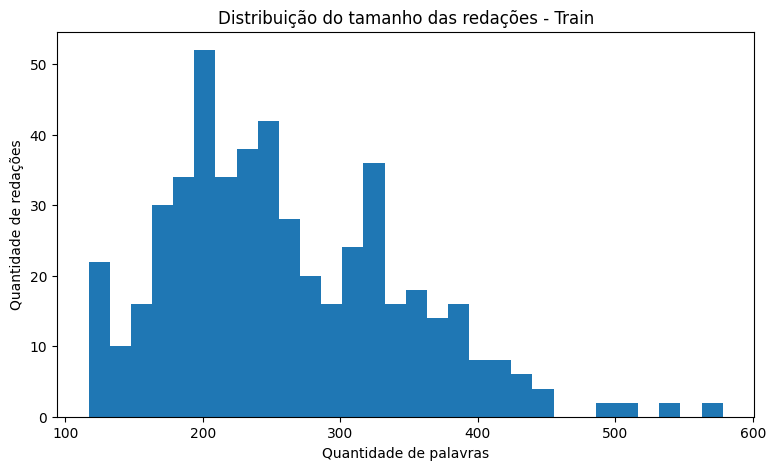

In [ ]:
# ============================================================
# DISTRIBUIÇÃO DO TAMANHO DAS REDAÇÕES
# ============================================================

plt.figure(figsize=(9, 5))

plt.hist(
    df_train["n_words"],
    bins=30
)

plt.title(
    "Distribuição do tamanho das redações - Train"
)

plt.xlabel(
    "Quantidade de palavras"
)

plt.ylabel(
    "Quantidade de redações"
)

plt.show()

In [ ]:
# ============================================================
# QUANTIDADE DE PARÁGRAFOS
# ============================================================

paragraph_distribution = (
    df_train["n_paragraphs"]
    .value_counts()
    .sort_index()
)

display(paragraph_distribution)

,count
n_paragraphs,
1,10
2,6
3,46
4,314
5,100
6,20
8,4


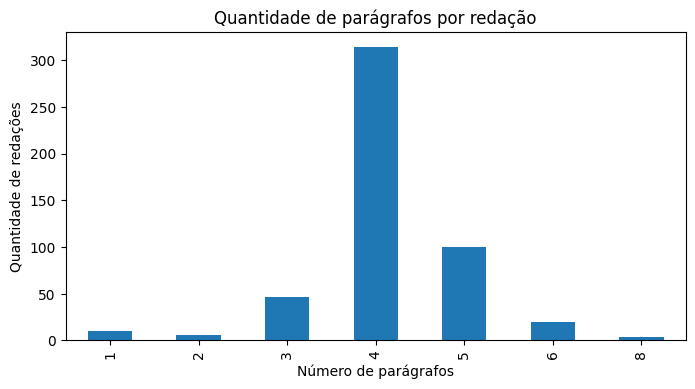

In [ ]:
plt.figure(figsize=(8, 4))

paragraph_distribution.plot(
    kind="bar"
)

plt.title(
    "Quantidade de parágrafos por redação"
)

plt.xlabel(
    "Número de parágrafos"
)

plt.ylabel(
    "Quantidade de redações"
)

plt.show()

In [ ]:
# ============================================================
# DISTRIBUIÇÃO DAS COMPETÊNCIAS
# ============================================================

for competencia in COMPETENCIAS:

    distribution = (
        df_train[competencia]
        .value_counts()
        .sort_index()
    )

    print(
        "\n",
        "=" * 50
    )

    print(
        competencia
    )

    print(
        "=" * 50
    )

    display(distribution)


C1


,count
C1,
0,3
40,2
80,39
120,199
160,210
200,47



C2


,count
C2,
0,3
40,79
80,29
120,226
160,83
200,80



C3


,count
C3,
0,3
40,81
80,53
120,181
160,141
200,41



C4


,count
C4,
0,3
40,7
80,30
120,260
160,167
200,33



C5


,count
C5,
0,122
40,111
80,92
120,91
160,61
200,23


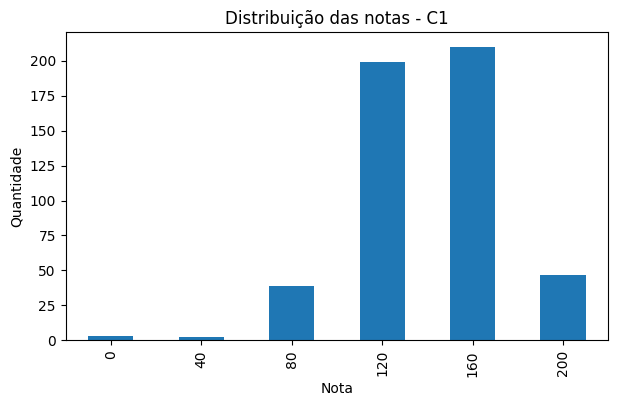

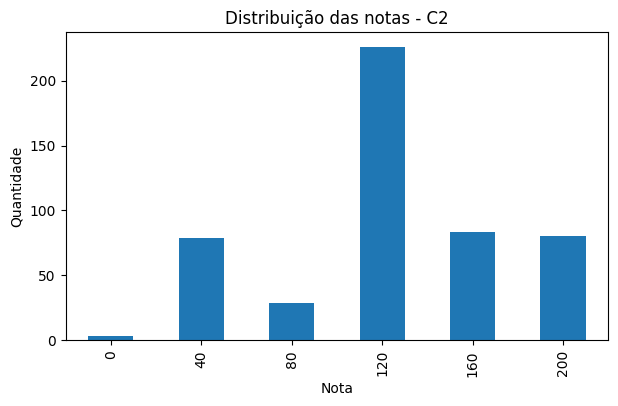

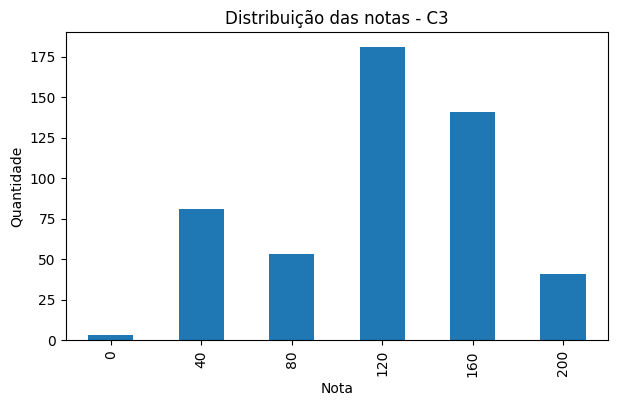

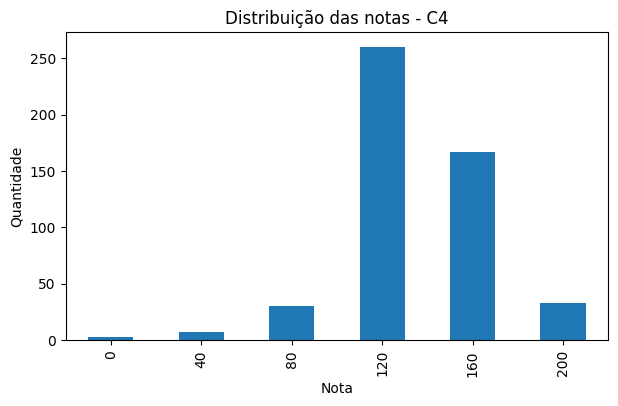

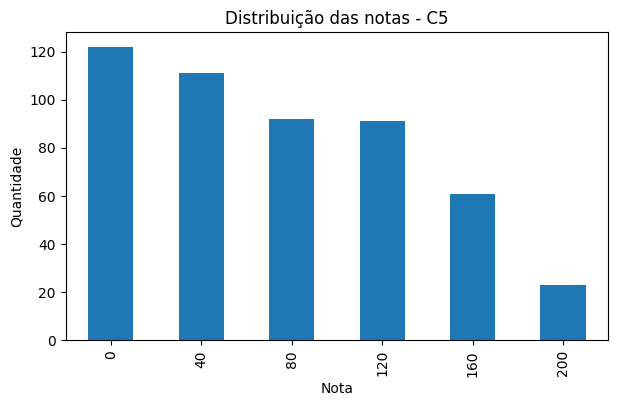

In [ ]:
# ============================================================
# DISTRIBUIÇÃO VISUAL DAS NOTAS
# ============================================================

for competencia in COMPETENCIAS:

    distribution = (
        df_train[competencia]
        .value_counts()
        .sort_index()
    )

    plt.figure(
        figsize=(7, 4)
    )

    distribution.plot(
        kind="bar"
    )

    plt.title(
        f"Distribuição das notas - {competencia}"
    )

    plt.xlabel(
        "Nota"
    )

    plt.ylabel(
        "Quantidade"
    )

    plt.show()

In [ ]:
# ============================================================
# DISTRIBUIÇÃO PERCENTUAL
# ============================================================

for competencia in COMPETENCIAS:

    distribution = (
        df_train[competencia]
        .value_counts(
            normalize=True
        )
        .sort_index()
        * 100
    )

    print(
        f"\n{competencia}"
    )

    display(
        distribution.round(2)
    )


C1


,proportion
C1,
0,0.6
40,0.4
80,7.8
120,39.8
160,42.0
200,9.4



C2


,proportion
C2,
0,0.6
40,15.8
80,5.8
120,45.2
160,16.6
200,16.0



C3


,proportion
C3,
0,0.6
40,16.2
80,10.6
120,36.2
160,28.2
200,8.2



C4


,proportion
C4,
0,0.6
40,1.4
80,6.0
120,52.0
160,33.4
200,6.6



C5


,proportion
C5,
0,24.4
40,22.2
80,18.4
120,18.2
160,12.2
200,4.6


In [ ]:
# ============================================================
# DISTRIBUIÇÃO DA NOTA TOTAL
# ============================================================

display(
    df_train["total"]
    .describe()
)

,total
count,500.000000
mean,592.400000
std,160.469751
min,0.000000
25%,480.000000
50%,600.000000
75%,720.000000
max,1000.000000


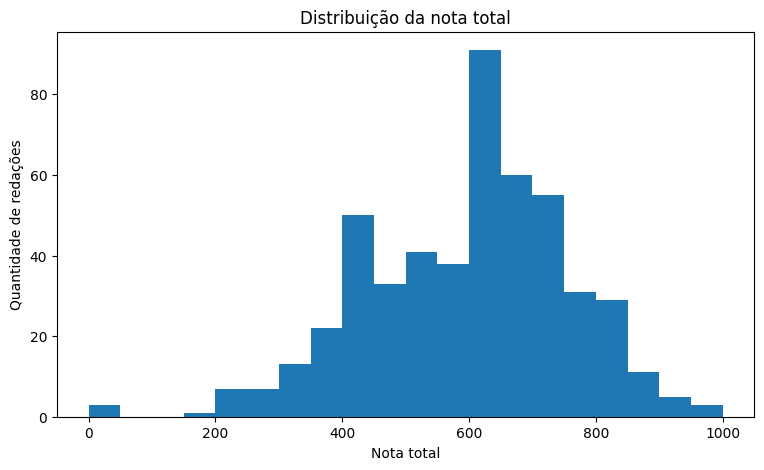

In [ ]:
plt.figure(
    figsize=(9, 5)
)

plt.hist(
    df_train["total"],
    bins=20
)

plt.title(
    "Distribuição da nota total"
)

plt.xlabel(
    "Nota total"
)

plt.ylabel(
    "Quantidade de redações"
)

plt.show()

In [ ]:
# ============================================================
# MÉDIA DAS COMPETÊNCIAS
# ============================================================

competence_stats = (
    df_train[COMPETENCIAS]
    .agg([
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .T
)

display(
    competence_stats.round(2)
)

,mean,median,std,min,max
C1,140.16,160.0,33.26,0.0,200.0
C2,123.76,120.0,49.71,0.0,200.0
C3,119.92,120.0,47.68,0.0,200.0
C4,134.40,120.0,31.99,0.0,200.0
C5,74.16,80.0,60.20,0.0,200.0


In [ ]:
# ============================================================
# CORRELAÇÃO ENTRE AS COMPETÊNCIAS
# ============================================================

correlation_matrix = (
    df_train[
        COMPETENCIAS
        + ["total"]
    ]
    .corr()
)

display(
    correlation_matrix.round(3)
)

,C1,C2,C3,C4,C5,total
C1,1.000,0.305,0.428,0.564,0.150,0.598
C2,0.305,1.000,0.756,0.323,0.362,0.798
C3,0.428,0.756,1.000,0.467,0.333,0.838
C4,0.564,0.323,0.467,1.000,0.252,0.650
C5,0.150,0.362,0.333,0.252,1.000,0.668
total,0.598,0.798,0.838,0.650,0.668,1.000


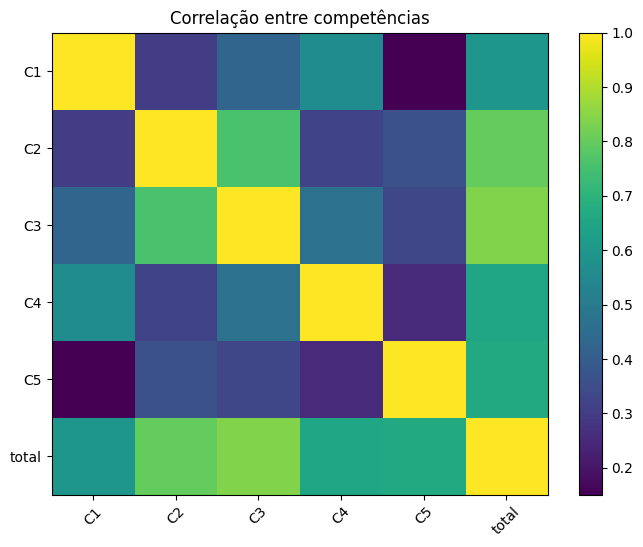

In [ ]:
plt.figure(
    figsize=(8, 6)
)

plt.imshow(
    correlation_matrix,
    aspect="auto"
)

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation_matrix.index)),
    correlation_matrix.index
)

plt.colorbar()

plt.title(
    "Correlação entre competências"
)

plt.show()

In [ ]:
# ============================================================
# REDAÇÕES POR TEMA
# ============================================================

essays_per_prompt = (
    df_train[
        "id_prompt"
    ]
    .value_counts()
    .sort_values(
        ascending=False
    )
)

display(
    essays_per_prompt
)

,count
id_prompt,
posse-de-armas-mais-seguranca-ou-mais-perigo,40
a-ciencia-na-era-da-pos-verdade,40
preservacao-da-amazonia-desafio-brasileiro-ou-internacional,40
universidade-em-crise-quem-paga-a-conta,40
carnaval-e-apropriacao-cultural,40
um-reu-deve-ou-nao-ser-preso-apos-a-condenacao-em-2-instancia,40
cantar-ou-nao-cantar-o-hino-nacional-eis-a-questao,40
a-fe-e-decisiva-para-uma-vida-melhor,40
epidemia-alimentar-sobrepeso-e-obesidade,40


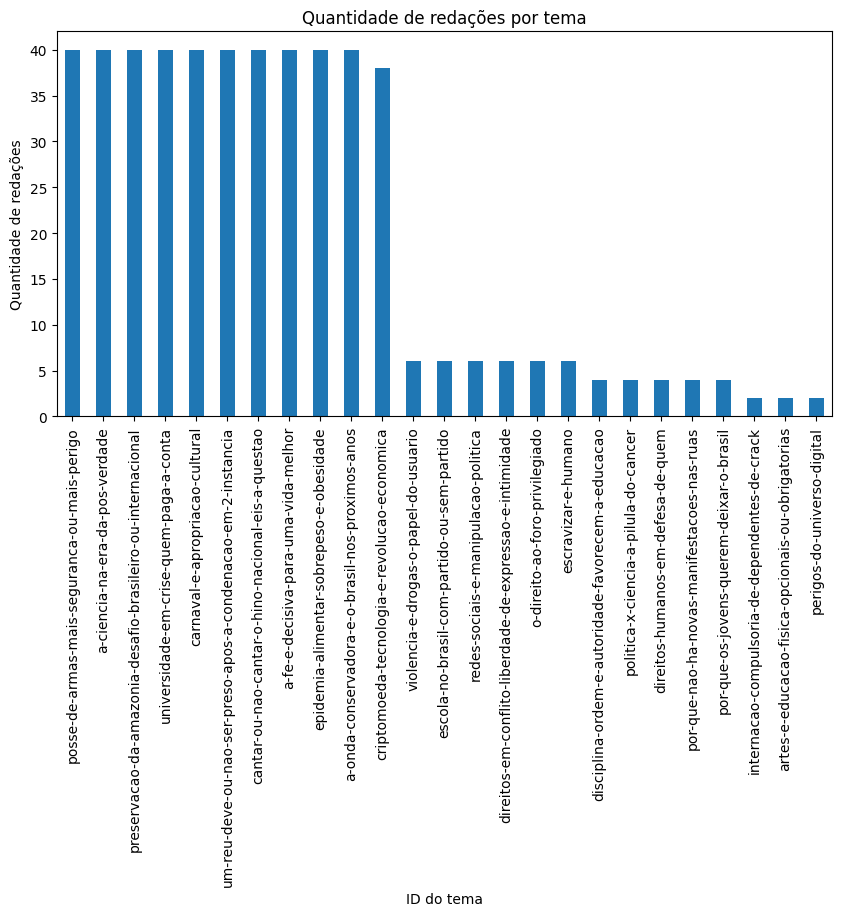

In [ ]:
plt.figure(
    figsize=(10, 5)
)

essays_per_prompt.plot(
    kind="bar"
)

plt.title(
    "Quantidade de redações por tema"
)

plt.xlabel(
    "ID do tema"
)

plt.ylabel(
    "Quantidade de redações"
)

plt.show()

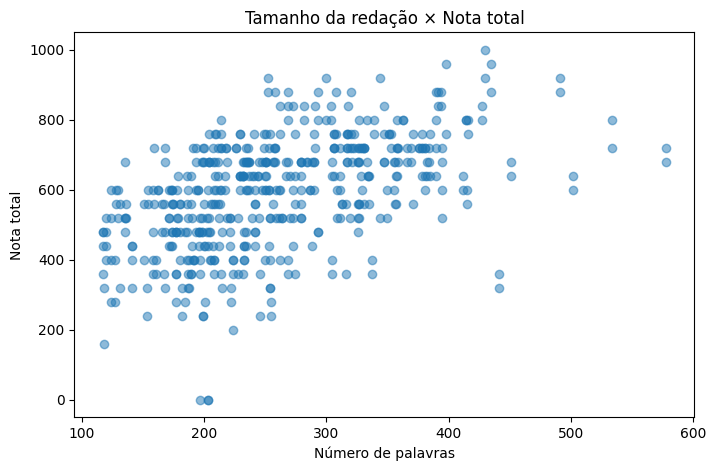

In [ ]:
# ============================================================
# TAMANHO DA REDAÇÃO × NOTA TOTAL
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.scatter(
    df_train["n_words"],
    df_train["total"],
    alpha=0.5
)

plt.xlabel(
    "Número de palavras"
)

plt.ylabel(
    "Nota total"
)

plt.title(
    "Tamanho da redação × Nota total"
)

plt.show()

In [ ]:
size_score_corr = (
    df_train[
        ["n_words", "total"]
    ]
    .corr()
    .iloc[0, 1]
)

print(
    "Correlação entre tamanho "
    "da redação e nota:",
    round(
        size_score_corr,
        3
    )
)

Correlação entre tamanho da redação e nota: 0.513


In [ ]:
# ============================================================
# TOKENIZER DO BERTIMBAU
# ============================================================
#
# Antes de treinar qualquer Transformer,
# precisamos descobrir o tamanho real das redações
# na tokenização utilizada pelo BERTimbau.

from transformers import AutoTokenizer


BERTIMBAU_MODEL = (
    "neuralmind/"
    "bert-base-portuguese-cased"
)


bert_tokenizer = (
    AutoTokenizer
    .from_pretrained(
        BERTIMBAU_MODEL
    )
)


print(
    "Tokenizer carregado:",
    BERTIMBAU_MODEL
)

config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Tokenizer carregado: neuralmind/bert-base-portuguese-cased


In [ ]:
# ============================================================
# CONTAGEM DE TOKENS DO BERTIMBAU
# ============================================================

def count_bert_tokens(text):
    """
    Retorna quantos tokens o BERTimbau gera para o texto.

    IMPORTANTE:
    não usamos truncation=True aqui,
    pois justamente queremos descobrir
    o comprimento real do texto.
    """

    encoded = bert_tokenizer(
        str(text),

        # Inclui tokens especiais,
        # por exemplo [CLS] e [SEP].
        add_special_tokens=True,

        # Não queremos truncar neste momento.
        truncation=False
    )

    return len(
        encoded["input_ids"]
    )

In [ ]:
# ============================================================
# CONTAGEM DE TOKENS
# ============================================================

df_train[
    "bert_tokens"
] = (
    df_train[
        "essay_text"
    ]
    .apply(
        count_bert_tokens
    )
)


display(
    df_train[
        "bert_tokens"
    ]
    .describe(
        percentiles=[
            .50,
            .75,
            .90,
            .95,
            .99
        ]
    )
)

,bert_tokens
count,500.000000
mean,336.848000
std,113.365711
min,144.000000
50%,313.500000
75%,413.000000
90%,489.400000
95%,531.000000
99%,677.000000
max,820.000000


In [ ]:
# ============================================================
# REDAÇÕES ACIMA DE 512 TOKENS
# ============================================================

BERT_MAX_TOKENS = 512


n_over_limit = (
    df_train[
        "bert_tokens"
    ]
    > BERT_MAX_TOKENS
).sum()


percentage_over_limit = (
    n_over_limit
    / len(df_train)
    * 100
)


print(
    "Total de redações:",
    len(df_train)
)

print(
    "Redações com > 512 tokens:",
    n_over_limit
)

print(
    "Percentual:",
    f"{percentage_over_limit:.2f}%"
)

Total de redações: 500
Redações com > 512 tokens: 34
Percentual: 6.80%


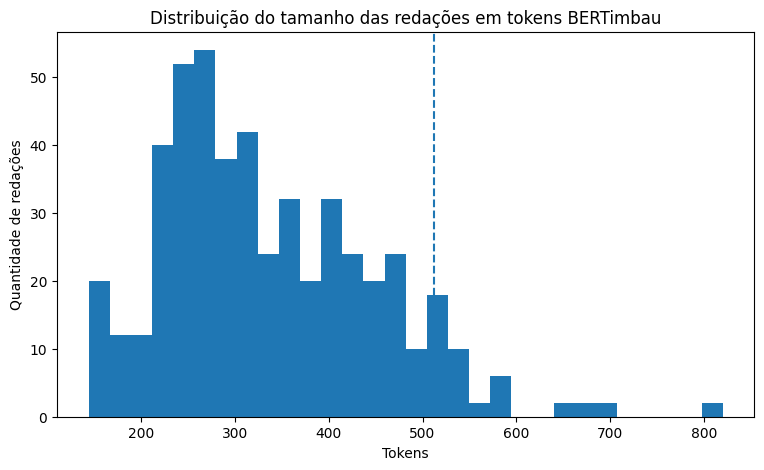

In [ ]:
# ============================================================
# DISTRIBUIÇÃO DE TOKENS DO BERTIMBAU
# ============================================================

plt.figure(
    figsize=(9, 5)
)

plt.hist(
    df_train[
        "bert_tokens"
    ],
    bins=30
)

# Marca visualmente o limite de 512.
plt.axvline(
    512,
    linestyle="--"
)

plt.title(
    "Distribuição do tamanho das redações "
    "em tokens BERTimbau"
)

plt.xlabel(
    "Tokens"
)

plt.ylabel(
    "Quantidade de redações"
)

plt.show()

In [ ]:
# ============================================================
# REDAÇÕES POTENCIALMENTE TRUNCADAS
# ============================================================

long_essays = (
    df_train[
        df_train[
            "bert_tokens"
        ] > 512
    ]
    [
        [
            "id",
            "id_prompt",
            "n_words",
            "bert_tokens",
            "C1",
            "C2",
            "C3",
            "C4",
            "C5",
            "total"
        ]
    ]
    .sort_values(
        "bert_tokens",
        ascending=False
    )
)


display(
    long_essays.head(20)
)

,id,id_prompt,n_words,bert_tokens,C1,C2,C3,C4,C5,total
19,14.html,internacao-compulsoria-de-dependentes-de-crack,578,820,160,200,200,120,0,680
114,14.html,internacao-compulsoria-de-dependentes-de-crack,578,820,200,160,200,160,0,720
279,1.html,epidemia-alimentar-sobrepeso-e-obesidade,502,685,160,200,120,120,40,640
89,1.html,epidemia-alimentar-sobrepeso-e-obesidade,502,685,160,160,160,120,0,600
495,11.html,posse-de-armas-mais-seguranca-ou-mais-perigo,534,677,160,200,160,120,80,720
211,11.html,posse-de-armas-mais-seguranca-ou-mais-perigo,534,677,160,200,200,160,80,800
134,19.html,cantar-ou-nao-cantar-o-hino-nacional-eis-a-que...,491,653,160,200,160,160,200,880
42,19.html,cantar-ou-nao-cantar-o-hino-nacional-eis-a-que...,491,653,160,200,200,160,200,920
322,12.html,posse-de-armas-mais-seguranca-ou-mais-perigo,451,584,160,160,160,160,40,680
418,12.html,posse-de-armas-mais-seguranca-ou-mais-perigo,451,584,120,120,160,160,80,640


In [ ]:
# ============================================================
# EXEMPLO DE REDAÇÃO LONGA
# ============================================================
#
# Se houver redações acima de 512 tokens,
# visualizamos a maior delas para entender
# o tipo de conteúdo que pode ser perdido
# pelo truncamento.

if len(long_essays) > 0:

    longest_id = (
        long_essays.iloc[0]["id"]
    )

    longest_essay = (
        df_train[
            df_train["id"]
            == longest_id
        ]
        .iloc[0]
    )

    print(
        "Tokens:",
        longest_essay[
            "bert_tokens"
        ]
    )

    print()

    print(
        longest_essay[
            "essay_text"
        ]
    )

else:

    print(
        "Nenhuma redação ultrapassa "
        "512 tokens."
    )

Tokens: 357

A floresta amazônica é maior floresta equatorial do mundo e sua maior parte está no território brasileiro. Após a promoção do povoamento da região norte foi implantado varias politicas de atração de investimento que subsidiaria expansão da região. Portanto, observa-se diante da intensa atividade antrópica na região tem ocasionado problemas ambientais sérios, as queimadas e desmatamento e entre outros; colocando em risco a fauna, flora, e posterior o aquecimento do planeta.
Por conseguinte, há uma necessidade de interferir em frente aos desastres ambientais causados pela ação antrópica que tem deteriorado grande parte da floresta amazônica. Os estudos apontam que há uma urgência de controlar e sanar os danos que a floresta vem sofrendo, e assim preservar fauna e flora daquela região; são necessário medidas tente assegurar à preservação e impedirem de ataques a floresta.
Todavia, as queimadas no norte do Brasil têm preocupado todos, por ser uma floresta de grande valia no eq

In [ ]:
# ============================================================
# RESUMO DA ANÁLISE EXPLORATÓRIA
# ============================================================

eda_summary = {
    "train_samples":
        len(df_train),

    "unique_essays":
        df_train[
            "essay_text"
        ].nunique(),

    "prompts":
        df_train[
            "id_prompt"
        ].nunique(),

    "avg_words":
        round(
            df_train[
                "n_words"
            ].mean(),
            2
        ),

    "median_words":
        round(
            df_train[
                "n_words"
            ].median(),
            2
        ),

    "avg_bert_tokens":
        round(
            df_train[
                "bert_tokens"
            ].mean(),
            2
        ),

    "essays_over_512":
        int(
            n_over_limit
        ),

    "percentage_over_512":
        round(
            percentage_over_limit,
            2
        )
}


for key, value in (
    eda_summary.items()
):
    print(
        f"{key:22s}: {value}"
    )

train_samples         : 500
unique_essays         : 250
prompts               : 25
avg_words             : 260.38
median_words          : 246.5
avg_bert_tokens       : 336.85
essays_over_512       : 34
percentage_over_512   : 6.8


# 4 - Preprocessing e Pipeline NLP Base

**Objetivo**

Construir o pipeline básico de Processamento de Linguagem Natural
que será utilizado pelos módulos das cinco competências.

Neste bloco iremos:

- definir uma estratégia de preprocessing conservadora;
- preservar parágrafos e pontuação;
- normalizar apenas problemas textuais necessários;
- segmentar a redação em parágrafos;
- processar o texto com spaCy;
- identificar sentenças;
- identificar tokens e palavras;
- obter lemas e classes gramaticais;
- identificar entidades nomeadas;
- criar uma representação estruturada da redação;
- validar o pipeline utilizando uma redação real do dataset.

**Princípio metodológico**

O preprocessing não deve remover características linguísticas
relevantes para a avaliação da redação.

Portanto, não removeremos indiscriminadamente:

- pontuação;
- acentuação;
- maiúsculas/minúsculas;
- quebras de parágrafo;
- stopwords;
- palavras repetidas.

In [ ]:
# ============================================================
# MODELO SPACY PARA PORTUGUÊS
# ============================================================
#
# O modelo foi instalado no BLOCO 1.
#
# Vamos carregá-lo novamente nesta seção para deixar
# explícita a dependência do nosso pipeline NLP.

import spacy

nlp = spacy.load(
    "pt_core_news_sm"
)

print(
    "Pipeline spaCy:"
)

print(
    nlp.pipe_names
)

Pipeline spaCy:
['tok2vec', 'morphologizer', 'parser', 'lemmatizer', 'attribute_ruler', 'ner']


**Estratégia de preprocessing**

Diferentemente de pipelines tradicionais de classificação textual,
não será aplicada uma limpeza textual agressiva.

A redação contém características importantes para as competências
avaliadas pelo ENEM.

Por exemplo:

- pontuação pode fornecer evidências para C1;
- estrutura dos parágrafos pode fornecer evidências para C3;
- conectivos são importantes para C4;
- a conclusão é especialmente importante para C5;
- palavras funcionais podem participar de mecanismos de coesão.

Assim, o preprocessing adotado será conservador.

Serão corrigidos apenas aspectos técnicos do texto, como:

- normalização Unicode;
- espaços excessivos;
- quebras de linha inconsistentes.

O texto original será sempre preservado.

In [ ]:
# ============================================================
# NORMALIZAÇÃO UNICODE
# ============================================================
#
# Textos podem conter diferentes representações Unicode
# para caracteres visualmente iguais.
#
# NFC é uma normalização conservadora e adequada para
# português, preservando os caracteres acentuados.

import unicodedata


def normalize_unicode(text):
    """
    Normaliza a representação Unicode sem remover
    acentos ou alterar o conteúdo linguístico.
    """

    if text is None:
        return ""

    text = str(text)

    return unicodedata.normalize(
        "NFC",
        text
    )

In [ ]:
# ============================================================
# NORMALIZAÇÃO DE QUEBRAS DE LINHA
# ============================================================
#
# Diferentes sistemas podem representar quebra de linha como:
#
# \n
# \r\n
# \r
#
# Vamos padronizar tudo para \n.
#
# IMPORTANTE:
# as quebras de linha NÃO serão removidas porque serão
# utilizadas posteriormente na análise dos parágrafos.

def normalize_line_breaks(text):
    """
    Padroniza quebras de linha mantendo a estrutura
    dos parágrafos.
    """

    text = str(text)

    text = text.replace(
        "\r\n",
        "\n"
    )

    text = text.replace(
        "\r",
        "\n"
    )

    return text

In [ ]:
# ============================================================
# NORMALIZAÇÃO DE ESPAÇOS
# ============================================================
#
# Removemos espaços repetidos dentro de uma mesma linha,
# mas preservamos as quebras de parágrafo.

def normalize_spaces(text):
    """
    Normaliza espaços horizontais sem destruir
    as quebras de linha.
    """

    lines = text.split("\n")

    normalized_lines = []

    for line in lines:

        # Substitui sequências de espaços/tabs
        # por um único espaço.
        line = re.sub(
            r"[ \t]+",
            " ",
            line
        )

        normalized_lines.append(
            line.strip()
        )

    return "\n".join(
        normalized_lines
    )

In [ ]:
# ============================================================
# NORMALIZAÇÃO DE LINHAS VAZIAS
# ============================================================
#
# Duas, três ou dez linhas vazias consecutivas não precisam
# representar parágrafos diferentes.
#
# Vamos reduzir sequências excessivas sem eliminar a
# estrutura textual.

def normalize_empty_lines(text):
    """
    Reduz múltiplas linhas vazias consecutivas.
    """

    text = re.sub(
        r"\n{3,}",
        "\n\n",
        text
    )

    return text.strip()

In [ ]:
# ============================================================
# NORMALIZAÇÃO CONSERVADORA
# ============================================================

def normalize_text(text):
    """
    Realiza normalização textual conservadora.

    Preserva:
    - acentuação;
    - pontuação;
    - caixa;
    - parágrafos;
    - conteúdo linguístico.
    """

    text = normalize_unicode(
        text
    )

    text = normalize_line_breaks(
        text
    )

    text = normalize_spaces(
        text
    )

    text = normalize_empty_lines(
        text
    )

    return text

In [ ]:
# ============================================================
# TESTE DA NORMALIZAÇÃO
# ============================================================

texto_teste = """No Brasil,   diversos problemas persistem.


Entretanto,  políticas públicas podem contribuir.

Portanto, é necessário agir."""

texto_normalizado = normalize_text(
    texto_teste
)

print(
    "ORIGINAL:"
)

print(
    repr(texto_teste)
)

print()

print(
    "NORMALIZADO:"
)

print(
    repr(texto_normalizado)
)

ORIGINAL:
'No Brasil,   diversos problemas persistem.\n\n\nEntretanto,  políticas públicas podem contribuir.\n\nPortanto, é necessário agir.'

NORMALIZADO:
'No Brasil, diversos problemas persistem.\n\nEntretanto, políticas públicas podem contribuir.\n\nPortanto, é necessário agir.'


In [ ]:
# ============================================================
# NORMALIZAÇÃO DE ENTRADA MANUAL
# ============================================================
#
# Textos digitados em textarea, Colab ou interfaces podem
# conter quebras simples apenas por formatação.
#
# Convenção adotada para entrada manual:
#
# \n   -> continuação do mesmo parágrafo
# \n\n -> novo parágrafo
#
# Ao final, convertemos para o FORMATO INTERNO do projeto:
#
# um único \n entre os parágrafos.
# ============================================================

def normalize_manual_essay(text):
    """
    Converte uma redação digitada manualmente para o formato
    interno utilizado pelo pipeline.

    Entrada manual:
        quebra simples -> mesma unidade de parágrafo
        linha vazia    -> novo parágrafo

    Saída interna:
        cada parágrafo separado por um único '\\n'
    """

    if text is None:
        return ""

    text = normalize_unicode(
        str(text)
    )

    text = normalize_line_breaks(
        text
    )

    # --------------------------------------------------------
    # Linhas que contêm apenas espaços são tratadas
    # como linhas vazias.
    # --------------------------------------------------------

    text = re.sub(
        r"\n[ \t]*\n+",
        "\n\n",
        text
    )

    # --------------------------------------------------------
    # Primeiro identificamos os parágrafos REAIS,
    # delimitados por linhas vazias.
    # --------------------------------------------------------

    raw_paragraphs = re.split(
        r"\n\s*\n",
        text.strip()
    )

    paragraphs = []

    for paragraph in raw_paragraphs:

        # ----------------------------------------------------
        # Dentro de um mesmo parágrafo, quebras simples
        # são apenas formatação e viram espaço.
        # ----------------------------------------------------

        paragraph = re.sub(
            r"\s*\n\s*",
            " ",
            paragraph
        )

        paragraph = re.sub(
            r"[ \t]+",
            " ",
            paragraph
        )

        paragraph = (
            paragraph.strip()
        )

        if paragraph:
            paragraphs.append(
                paragraph
            )

    # --------------------------------------------------------
    # CONVERSÃO PARA O FORMATO INTERNO:
    #
    # um único \n entre parágrafos.
    #
    # A partir daqui, split_paragraphs() pode trabalhar
    # exatamente como trabalha com o AES-ENEM.
    # --------------------------------------------------------

    return "\n".join(
        paragraphs
    )

In [ ]:
# ============================================================
# SEGMENTAÇÃO EM PARÁGRAFOS — VERSÃO CORRIGIDA
# ============================================================
#
# IMPORTANTE:
#
# Uma quebra de linha simples pode existir apenas por
# formatação do texto.
#
# Exemplo:
#
# "O Ministério deve promover campanhas
# educativas nas escolas."
#
# Isso NÃO significa necessariamente dois parágrafos.
#
# Consideraremos como separação explícita de parágrafo
# principalmente uma ou mais linhas vazias.
#
# Dentro de cada parágrafo, quebras de linha simples são
# transformadas em espaços.


# def split_paragraphs(text):
#     """
#     Divide o texto em parágrafos preservando a estrutura
#     sem confundir quebra visual de linha com novo parágrafo.

#     Estratégia:
#     1. normaliza o texto;
#     2. divide por linhas vazias;
#     3. transforma quebras simples dentro do mesmo
#        parágrafo em espaços.
#     """

#     text = normalize_text(
#         text
#     )

#     # --------------------------------------------------------
#     # Separa blocos quando existe uma linha vazia.
#     #
#     # \n\s*\n significa:
#     # quebra de linha
#     # + possíveis espaços
#     # + outra quebra de linha.
#     # --------------------------------------------------------

#     raw_paragraphs = re.split(
#         r"\n\s*\n+",
#         text
#     )

#     paragraphs = []

#     for paragraph in raw_paragraphs:

#         # ----------------------------------------------------
#         # Quebras simples dentro do mesmo bloco são tratadas
#         # como continuação da mesma frase/parágrafo.
#         # ----------------------------------------------------

#         paragraph = re.sub(
#             r"\s*\n\s*",
#             " ",
#             paragraph
#         )

#         # Normaliza eventuais espaços extras.
#         paragraph = re.sub(
#             r"[ \t]+",
#             " ",
#             paragraph
#         )

#         paragraph = (
#             paragraph.strip()
#         )

#         if paragraph:

#             paragraphs.append(
#                 paragraph
#             )

#     return paragraphs

# ============================================================
# SEGMENTAÇÃO EM PARÁGRAFOS — VERSÃO DEFINITIVA
# ============================================================
#
# O dataset AES-ENEM utiliza uma quebra de linha simples (\n)
# para representar a separação entre parágrafos.
#
# Portanto:
#
# texto...\ntexto...
#
# representa dois parágrafos.
#
# Linhas vazias adicionais também são aceitas.
# ============================================================

def split_paragraphs(text):
    """
    Divide o texto em parágrafos utilizando uma ou mais
    quebras de linha como separador.

    Essa implementação é compatível com a estrutura
    observada no dataset AES-ENEM JBCS2025.
    """

    text = normalize_text(
        text
    )

    paragraphs = re.split(
        r"\n+",
        text
    )

    paragraphs = [
        paragraph.strip()
        for paragraph in paragraphs
        if paragraph.strip()
    ]

    return paragraphs


# #####################################################################

# # ============================================================
# # SEPARAÇÃO DE PARÁGRAFOS — VERSÃO CORRIGIDA
# # ============================================================

# def split_paragraphs(text):
#     """
#     Separa parágrafos preservando a diferença entre:

#     - quebra visual de linha;
#     - separação real entre parágrafos.

#     Regra:

#     1 quebra:
#         continuação do mesmo parágrafo

#     2 ou mais quebras:
#         novo parágrafo
#     """

#     if text is None:
#         return []

#     text = str(text)

#     # --------------------------------------------------------
#     # Normalização Unicode e de quebra de linha.
#     #
#     # IMPORTANTE:
#     # não chamamos normalize_text() aqui porque precisamos
#     # preservar temporariamente a diferença entre \n e \n\n.
#     # --------------------------------------------------------

#     text = normalize_unicode(
#         text
#     )

#     text = normalize_line_breaks(
#         text
#     )

#     # --------------------------------------------------------
#     # Remove espaços existentes em linhas vazias.
#     #
#     # Exemplo:
#     #
#     # "texto\n   \noutro"
#     #
#     # passa a:
#     #
#     # "texto\n\noutro"
#     # --------------------------------------------------------

#     text = re.sub(
#         r"\n[ \t]+\n",
#         "\n\n",
#         text
#     )

#     # --------------------------------------------------------
#     # Duas ou mais quebras representam parágrafo.
#     # --------------------------------------------------------

#     raw_paragraphs = re.split(
#         r"\n\s*\n+",
#         text.strip()
#     )

#     paragraphs = []

#     for paragraph in raw_paragraphs:

#         # ----------------------------------------------------
#         # Dentro do mesmo parágrafo, uma quebra visual
#         # torna-se apenas um espaço.
#         # ----------------------------------------------------

#         paragraph = re.sub(
#             r"\s*\n\s*",
#             " ",
#             paragraph
#         )

#         # ----------------------------------------------------
#         # Normaliza espaços horizontais.
#         # ----------------------------------------------------

#         paragraph = re.sub(
#             r"[ \t]+",
#             " ",
#             paragraph
#         )

#         paragraph = (
#             paragraph.strip()
#         )

#         if paragraph:

#             paragraphs.append(
#                 paragraph
#             )

#     return paragraphs

In [ ]:
# ============================================================
# TESTE DA SEGMENTAÇÃO
# ============================================================

paragraphs = split_paragraphs(
    texto_teste
)

print(
    "Quantidade de parágrafos:",
    len(paragraphs)
)

print()

for index, paragraph in enumerate(
    paragraphs,
    start=1
):

    print(
        f"PARÁGRAFO {index}"
    )

    print(
        paragraph
    )

    print(
        "-" * 60
    )

Quantidade de parágrafos: 3

PARÁGRAFO 1
No Brasil, diversos problemas persistem.
------------------------------------------------------------
PARÁGRAFO 2
Entretanto, políticas públicas podem contribuir.
------------------------------------------------------------
PARÁGRAFO 3
Portanto, é necessário agir.
------------------------------------------------------------


In [ ]:
# ============================================================
# SEGMENTAÇÃO EM SENTENÇAS
# ============================================================

def get_sentences(doc):
    """
    Extrai as sentenças identificadas pelo parser
    do spaCy.
    """

    return [
        sentence.text.strip()
        for sentence in doc.sents
        if sentence.text.strip()
    ]

In [ ]:
# ============================================================
# EXTRAÇÃO DE TOKENS LINGUÍSTICOS
# ============================================================

def get_word_tokens(doc):
    """
    Retorna apenas tokens considerados palavras.

    Pontuação e espaços são ignorados.
    """

    return [
        token
        for token in doc
        if not token.is_space
        and not token.is_punct
    ]

In [ ]:
# ============================================================
# EXTRAÇÃO DE LEMAS
# ============================================================
#
# Exemplo conceitual:
#
# políticas -> política
# estudantes -> estudante
# promoveram -> promover

def get_lemmas(doc):
    """
    Retorna os lemas das palavras identificadas pelo spaCy.
    """

    return [
        token.lemma_.lower()
        for token in get_word_tokens(doc)
        if token.lemma_
    ]

In [ ]:
# ============================================================
# CLASSES GRAMATICAIS
# ============================================================
#
# POS = Part-of-Speech
#
# Exemplos:
#
# NOUN  -> substantivo
# VERB  -> verbo
# ADJ   -> adjetivo
# ADV   -> advérbio
# PROPN -> nome próprio

from collections import Counter


def get_pos_distribution(doc):
    """
    Retorna a quantidade de tokens de cada
    classe gramatical.
    """

    words = get_word_tokens(
        doc
    )

    return dict(
        Counter(
            token.pos_
            for token in words
        )
    )

In [ ]:
# ============================================================
# ENTIDADES NOMEADAS
# ============================================================
#
# Exemplos possíveis:
#
# Ministério da Educação
# Governo Federal
# Brasil
# ONU
#
# Essas entidades podem auxiliar na identificação
# de agentes da proposta de intervenção.

def get_named_entities(doc):
    """
    Retorna entidades identificadas pelo modelo NER do spaCy.
    """

    return [
        {
            "texto": entity.text,
            "tipo": entity.label_
        }

        for entity in doc.ents
    ]

In [ ]:
# ============================================================
# ANÁLISE DE UM PARÁGRAFO
# ============================================================

def analyze_paragraph(
    paragraph,
    index
):
    """
    Processa individualmente um parágrafo
    utilizando spaCy.
    """

    doc = nlp(
        paragraph
    )

    sentences = get_sentences(
        doc
    )

    words = get_word_tokens(
        doc
    )

    return {

        "indice":
            index,

        "texto":
            paragraph,

        "n_sentencas":
            len(sentences),

        "n_palavras":
            len(words),

        "sentencas":
            sentences,

        "lemas":
            get_lemmas(doc),

        "pos":
            get_pos_distribution(
                doc
            ),

        "entidades":
            get_named_entities(
                doc
            )
    }

In [ ]:
# ============================================================
# PIPELINE NLP BASE
# ============================================================

def process_essay(
    text,
    prompt=None
):
    """
    Processa uma redação completa e produz uma
    representação estruturada.

    Essa estrutura será reutilizada posteriormente
    pelos módulos C1, C2, C3, C4 e C5.

    Parameters
    ----------
    text : str
        Texto da redação.

    prompt : str, optional
        Tema/proposta da redação.

    Returns
    -------
    dict
        Representação estruturada da redação.
    """

    # --------------------------------------------------------
    # Preserva o texto exatamente como foi recebido.
    # --------------------------------------------------------

    original_text = (
        ""
        if text is None
        else str(text)
    )

    # --------------------------------------------------------
    # Normalização conservadora.
    # --------------------------------------------------------

    normalized_text = (
        normalize_text(
            original_text
        )
    )

    # --------------------------------------------------------
    # Segmentação dos parágrafos.
    # --------------------------------------------------------

    paragraphs = (
        split_paragraphs(
            normalized_text
        )
    )

    # --------------------------------------------------------
    # Processamento da redação completa com spaCy.
    # --------------------------------------------------------

    doc = nlp(
        normalized_text
    )

    # --------------------------------------------------------
    # Sentenças.
    # --------------------------------------------------------

    sentences = (
        get_sentences(
            doc
        )
    )

    # --------------------------------------------------------
    # Tokens que representam palavras.
    # --------------------------------------------------------

    words = (
        get_word_tokens(
            doc
        )
    )

    # --------------------------------------------------------
    # Processamento individual dos parágrafos.
    # --------------------------------------------------------

    paragraph_analysis = [

        analyze_paragraph(
            paragraph,
            index
        )

        for index, paragraph
        in enumerate(
            paragraphs,
            start=1
        )
    ]

    # --------------------------------------------------------
    # Estrutura final.
    # --------------------------------------------------------

    return {

        "tema":
            prompt,

        "texto_original":
            original_text,

        "texto_normalizado":
            normalized_text,

        "n_caracteres":
            len(normalized_text),

        "n_palavras":
            len(words),

        "n_sentencas":
            len(sentences),

        "n_paragrafos":
            len(paragraphs),

        "sentencas":
            sentences,

        "paragrafos":
            paragraph_analysis,

        "lemas":
            get_lemmas(
                doc
            ),

        "pos":
            get_pos_distribution(
                doc
            ),

        "entidades":
            get_named_entities(
                doc
            )
    }

In [ ]:
# ============================================================
# TESTE COM UMA REDAÇÃO REAL DO AES-ENEM
# ============================================================

sample = df_train.iloc[0]

sample_text = (
    sample[
        "essay_text"
    ]
)

sample_prompt = (
    sample[
        "prompt"
    ]
)


essay_analysis = (
    process_essay(
        text=sample_text,
        prompt=sample_prompt
    )
)


print(
    "Redação processada com sucesso."
)

Redação processada com sucesso.


In [ ]:
# ============================================================
# RESUMO DA REDAÇÃO
# ============================================================

print(
    "Caracteres:",
    essay_analysis[
        "n_caracteres"
    ]
)

print(
    "Palavras:",
    essay_analysis[
        "n_palavras"
    ]
)

print(
    "Sentenças:",
    essay_analysis[
        "n_sentencas"
    ]
)

print(
    "Parágrafos:",
    essay_analysis[
        "n_paragrafos"
    ]
)

print()

print(
    "Entidades:",
    essay_analysis[
        "entidades"
    ]
)

Caracteres: 953
Palavras: 161
Sentenças: 8
Parágrafos: 4

Entidades: [{'texto': 'Brasil', 'tipo': 'LOC'}, {'texto': 'Brasil', 'tipo': 'LOC'}, {'texto': '“', 'tipo': 'PER'}]


In [ ]:
# ============================================================
# VISUALIZAÇÃO DOS PARÁGRAFOS
# ============================================================

for paragraph in (
    essay_analysis[
        "paragrafos"
    ]
):

    print(
        "=" * 80
    )

    print(
        "PARÁGRAFO",
        paragraph[
            "indice"
        ]
    )

    print(
        "=" * 80
    )

    print(
        paragraph[
            "texto"
        ]
    )

    print()

    print(
        "Palavras:",
        paragraph[
            "n_palavras"
        ]
    )

    print(
        "Sentenças:",
        paragraph[
            "n_sentencas"
        ]
    )

    print()

PARÁGRAFO 1
O Brasil vive uma epidemia de homicídios nas últimas décadas. A violência é comum a países com alto grau de desigualdade social - como o Brasil.

Palavras: 25
Sentenças: 2

PARÁGRAFO 2
O decreto que flexibiliza a posse de arma, bem como, os anseios de uma parcela da população que concorda com este, põe em cheque a fragilidade do estado em garantir a segurança aos cidadãos pagadores de impostos.

Palavras: 37
Sentenças: 1

PARÁGRAFO 3
A violência escancarada nos jornais não é resultado da falta de armas e sim do excesso delas, principalmente por estarem “nas mãos erradas”. Outro fator que corrobora com o aumento da violência é a falta de investimentos em educação e emprego. Uma população sem expectativas, sem oportunidades, se torna muito mais vulnerável e atraída para o tráfico de drogas, armas, etc.

Palavras: 61
Sentenças: 3

PARÁGRAFO 4
Portanto, para conter a escalada do número de homicídios, é preciso ir além de decretos e leis que “joguem” ainda mais armas diante de u

In [ ]:
# ============================================================
# SENTENÇAS IDENTIFICADAS
# ============================================================

for index, sentence in enumerate(
    essay_analysis[
        "sentencas"
    ],
    start=1
):

    print(
        f"{index:02d}.",
        sentence
    )

    print()

01. O Brasil vive uma epidemia de homicídios nas últimas décadas.

02. A violência é comum a países com alto grau de desigualdade social - como o Brasil.

03. O decreto que flexibiliza a posse de arma, bem como, os anseios de uma parcela da população que concorda com este, põe em cheque a fragilidade do estado em garantir a segurança aos cidadãos pagadores de impostos.

04. A violência escancarada nos jornais não é resultado da falta de armas e sim do excesso delas, principalmente por estarem “nas mãos erradas”.

05. Outro fator que corrobora com o aumento da violência é a falta de investimentos em educação e emprego.

06. Uma população sem expectativas, sem oportunidades, se torna muito mais vulnerável e atraída para o tráfico de drogas, armas, etc.

07. Portanto, para conter a escalada do número de homicídios, é preciso ir além de decretos e leis que “joguem” ainda mais armas diante de uma população que carece do básico.

08. Carece de educação, de emprego, saúde e dignidade.



In [ ]:
# ============================================================
# DISTRIBUIÇÃO DAS CLASSES GRAMATICAIS
# ============================================================

pos_distribution = (
    essay_analysis[
        "pos"
    ]
)

pos_df = (
    pd.DataFrame(
        list(
            pos_distribution.items()
        ),
        columns=[
            "Classe",
            "Quantidade"
        ]
    )
    .sort_values(
        "Quantidade",
        ascending=False
    )
)


display(
    pos_df
)

,Classe,Quantidade
3,NOUN,51
4,ADP,35
0,DET,19
2,VERB,14
8,ADV,11
7,PRON,8
5,ADJ,7
10,CCONJ,5
6,AUX,5
1,PROPN,3


In [ ]:
# ============================================================
# ENTIDADES IDENTIFICADAS
# ============================================================

entities = (
    essay_analysis[
        "entidades"
    ]
)


if entities:

    display(
        pd.DataFrame(
            entities
        )
    )

else:

    print(
        "Nenhuma entidade identificada."
    )

,texto,tipo
0,Brasil,LOC
1,Brasil,LOC
2,“,PER


In [ ]:
# ============================================================
# INSPEÇÃO LINGUÍSTICA
# ============================================================

sample_doc = nlp(
    essay_analysis[
        "texto_normalizado"
    ]
)


token_data = []

for token in sample_doc:

    # Ignora espaços para facilitar a visualização.
    if token.is_space:
        continue

    token_data.append({

        "token":
            token.text,

        "lema":
            token.lemma_,

        "pos":
            token.pos_,

        "dependencia":
            token.dep_,

        "stopword":
            token.is_stop,

        "pontuacao":
            token.is_punct
    })


token_df = pd.DataFrame(
    token_data
)


display(
    token_df.head(50)
)

,token,lema,pos,dependencia,stopword,pontuacao
0,O,o,DET,det,True,False
1,Brasil,Brasil,PROPN,nsubj,False,False
2,vive,viver,VERB,ROOT,False,False
3,uma,um,DET,det,True,False
4,epidemia,epidemia,NOUN,obj,False,False
5,de,de,ADP,case,True,False
6,homicídios,homicídio,NOUN,nmod,False,False
7,nas,em o,ADP,case,True,False
8,últimas,último,ADJ,amod,False,False
9,décadas,década,NOUN,obl,False,False


In [ ]:
# ============================================================
# SANITY CHECKS
# ============================================================
#
# Pequenos testes ajudam a garantir que mudanças futuras
# não destruam silenciosamente nosso pipeline.

assert (
    essay_analysis[
        "texto_original"
    ]
    == sample_text
), "O texto original foi alterado."


assert (
    essay_analysis[
        "n_palavras"
    ] > 0
), "Nenhuma palavra foi identificada."


assert (
    essay_analysis[
        "n_sentencas"
    ] > 0
), "Nenhuma sentença foi identificada."


assert (
    essay_analysis[
        "n_paragrafos"
    ] > 0
), "Nenhum parágrafo foi identificado."


print(
    "Todos os sanity checks passaram."
)

Todos os sanity checks passaram.


In [ ]:
# # ============================================================
# # TESTES DE PRESERVAÇÃO DE PARÁGRAFOS
# # ============================================================
# #
# # Queremos validar dois comportamentos:
# #
# # 1. Linhas vazias devem representar separação de parágrafos.
# # 2. Quebras de linha simples dentro de um mesmo bloco
# #    não devem ser interpretadas como novos parágrafos.
# # ============================================================


# # ------------------------------------------------------------
# # TESTE 1 — PARÁGRAFOS REAIS
# # ------------------------------------------------------------

# test_paragraph_text = """Primeiro parágrafo da redação.

# Segundo parágrafo da redação.

# Terceiro parágrafo da redação.

# Quarto parágrafo da redação."""


# test_result = process_essay(
#     test_paragraph_text
# )


# assert (
#     test_result["n_paragrafos"] == 4
# ), (
#     "ERRO: a estrutura dos "
#     "parágrafos foi perdida."
# )


# print(
#     "✓ Teste 1 passou: "
#     "parágrafos separados por linha vazia foram preservados."
# )


# # ------------------------------------------------------------
# # TESTE 2 — QUEBRA VISUAL DE LINHA
# # ------------------------------------------------------------
# #
# # Neste exemplo existem quebras de linha no código,
# # mas semanticamente temos apenas um parágrafo.

# wrapped_text = """O Ministério da Educação deve promover campanhas
# educativas por meio das escolas, com apoio de
# professores e da comunidade."""


# wrapped_result = process_essay(
#     wrapped_text
# )


# assert (
#     wrapped_result["n_paragrafos"] == 1
# ), (
#     "ERRO: quebras visuais de linha estão sendo "
#     "interpretadas como novos parágrafos."
# )


# print(
#     "✓ Teste 2 passou: "
#     "quebras visuais não criaram novos parágrafos."
# )


# print()
# print(
#     "Todos os testes de segmentação de parágrafos passaram."
# )

# ============================================================
# TESTES DE PRESERVAÇÃO DE PARÁGRAFOS
# ============================================================


# ------------------------------------------------------------
# TESTE 1 — TEXTO CONTROLADO
# ------------------------------------------------------------

test_paragraph_text = """Primeiro parágrafo da redação.
Segundo parágrafo da redação.
Terceiro parágrafo da redação.
Quarto parágrafo da redação."""


test_result = process_essay(
    test_paragraph_text
)


assert (
    test_result["n_paragrafos"] == 4
), (
    "ERRO: a estrutura dos "
    "parágrafos foi perdida."
)


print(
    "✓ Teste controlado passou: "
    "4 parágrafos identificados."
)


# ------------------------------------------------------------
# TESTE 2 — REDAÇÃO REAL DO AES-ENEM
# ------------------------------------------------------------

dataset_paragraphs = split_paragraphs(
    df_train.iloc[0]["essay_text"]
)


assert (
    len(dataset_paragraphs) > 1
), (
    "ERRO: os parágrafos do AES-ENEM "
    "não estão sendo identificados."
)


print(
    "✓ Teste AES-ENEM passou:",
    len(dataset_paragraphs),
    "parágrafos identificados."
)

✓ Teste controlado passou: 4 parágrafos identificados.
✓ Teste AES-ENEM passou: 4 parágrafos identificados.


               REDAÇÃO
                  │
                  ▼
        normalização conservadora
                  │
        ┌─────────┼─────────┐
        ▼         ▼         ▼
    parágrafos sentenças  tokens
        │                   │
        ▼                   ▼
      spaCy             lemas / POS
        │
        ▼
     entidades
        │
        ▼
  representação estruturada

# 5 - Análise NLP das Cinco Competências do ENEM

**Objetivo**

Construir módulos de análise linguística e semântica capazes de
produzir evidências relacionadas às cinco competências avaliadas
na redação do ENEM.

Os módulos não substituirão o avaliador e não atribuirão diretamente
a nota oficial da competência.

A arquitetura adotada separa:

**Predição**
   - realizada posteriormente pelos modelos supervisionados;

**Evidências**
   - produzidas pelos módulos NLP deste bloco.

**Competências**

C1 — Domínio da modalidade escrita formal
Indicadores lexicais, morfossintáticos e estruturais.

C2 — Compreensão da proposta e desenvolvimento do tema
Similaridade semântica entre tema e redação.

C3 — Seleção e organização de argumentos
Estrutura textual, marcadores argumentativos e continuidade semântica.

C4 — Mecanismos linguísticos de coesão
Conectivos, diversidade e distribuição dos mecanismos coesivos.

C5 — Proposta de intervenção
Identificação de evidências relacionadas a agente, ação, meio,
finalidade e detalhamento.

In [ ]:
''''
  C1: Domínio da Modalidade Escrita Formal

  Para apoiar a análise da Competência 1 serão extraídos indicadores
  linguísticos relacionados a:

  - extensão textual;
  - estrutura das sentenças;
  - diversidade lexical;
  - repetição lexical;
  - distribuição de classes gramaticais;
  - uso de pontuação;
  - características morfossintáticas.

  Esses indicadores serão utilizados como evidências auxiliares e
  posteriormente também poderão compor as features do baseline
  de Machine Learning.
'''

"'\n  C1: Domínio da Modalidade Escrita Formal\n\n  Para apoiar a análise da Competência 1 serão extraídos indicadores\n  linguísticos relacionados a:\n\n  - extensão textual;\n  - estrutura das sentenças;\n  - diversidade lexical;\n  - repetição lexical;\n  - distribuição de classes gramaticais;\n  - uso de pontuação;\n  - características morfossintáticas.\n\n  Esses indicadores serão utilizados como evidências auxiliares e\n  posteriormente também poderão compor as features do baseline\n  de Machine Learning.\n"

In [ ]:
# ============================================================
# DIVERSIDADE LEXICAL
# ============================================================
#
# Type-Token Ratio (TTR):
#
# número de palavras distintas
# ----------------------------
# número total de palavras
#
# IMPORTANTE:
# TTR possui dependência do tamanho do texto.
# Portanto será tratado como indicador e não como
# medida absoluta de qualidade textual.

def lexical_diversity(doc):
    """
    Calcula diversidade lexical simples utilizando
    os lemas das palavras.
    """

    words = [
        token.lemma_.lower()
        for token in get_word_tokens(doc)
        if token.is_alpha
        and token.lemma_
    ]

    if not words:
        return 0.0

    unique_words = set(
        words
    )

    return (
        len(unique_words)
        / len(words)
    )

In [ ]:
# ============================================================
# REPETIÇÃO LEXICAL
# ============================================================

def lexical_repetitions(
    doc,
    min_occurrences=3
):
    """
    Identifica lemas de palavras de conteúdo que aparecem
    repetidamente na redação.

    Stopwords, pontuação e tokens não alfabéticos
    são ignorados.
    """

    words = [

        token.lemma_.lower()

        for token in doc

        if token.is_alpha
        and not token.is_stop
        and len(token.text) > 2
    ]

    frequencies = Counter(
        words
    )

    repetitions = {
        word: count

        for word, count
        in frequencies.items()

        if count >= min_occurrences
    }

    return dict(
        sorted(
            repetitions.items(),
            key=lambda item: item[1],
            reverse=True
        )
    )

In [ ]:
# ============================================================
# PONTUAÇÃO
# ============================================================

def punctuation_statistics(doc):
    """
    Conta os principais sinais de pontuação encontrados
    na redação.
    """

    punctuation = [
        token.text
        for token in doc
        if token.is_punct
    ]

    return dict(
        Counter(
            punctuation
        )
    )

In [ ]:
# ============================================================
# TAMANHO MÉDIO DAS SENTENÇAS
# ============================================================

def sentence_length_statistics(doc):
    """
    Calcula estatísticas sobre o comprimento
    das sentenças em palavras.
    """

    lengths = []

    for sentence in doc.sents:

        words = [
            token
            for token in sentence
            if not token.is_space
            and not token.is_punct
        ]

        if words:
            lengths.append(
                len(words)
            )

    if not lengths:

        return {
            "media": 0,
            "min": 0,
            "max": 0
        }

    return {

        "media":
            round(
                float(
                    np.mean(lengths)
                ),
                2
            ),

        "min":
            int(
                np.min(lengths)
            ),

        "max":
            int(
                np.max(lengths)
            )
    }

In [ ]:
# ============================================================
# PROPORÇÃO DAS CLASSES GRAMATICAIS
# ============================================================

def pos_ratios(doc):
    """
    Calcula a proporção das classes gramaticais
    identificadas pelo spaCy.
    """

    words = get_word_tokens(
        doc
    )

    if not words:
        return {}

    counts = Counter(
        token.pos_
        for token in words
    )

    total = len(words)

    return {
        pos: round(
            count / total,
            4
        )

        for pos, count
        in counts.items()
    }

In [ ]:
# ============================================================
# ANALISADOR DA COMPETÊNCIA 1
# ============================================================

def analyze_c1(text):
    """
    Produz indicadores linguísticos relacionados
    à Competência 1.

    IMPORTANTE:
    esta função NÃO atribui nota à C1.
    """

    normalized_text = (
        normalize_text(
            text
        )
    )

    doc = nlp(
        normalized_text
    )

    words = get_word_tokens(
        doc
    )

    sentences = get_sentences(
        doc
    )

    paragraphs = split_paragraphs(
        normalized_text
    )

    return {

        "n_palavras":
            len(words),

        "n_sentencas":
            len(sentences),

        "n_paragrafos":
            len(paragraphs),

        "diversidade_lexical":
            round(
                lexical_diversity(
                    doc
                ),
                4
            ),

        "tamanho_sentencas":
            sentence_length_statistics(
                doc
            ),

        "repeticoes_lexicais":
            lexical_repetitions(
                doc
            ),

        "classes_gramaticais":
            pos_ratios(
                doc
            ),

        "pontuacao":
            punctuation_statistics(
                doc
            )
    }

In [ ]:
# ============================================================
# TESTE DO MÓDULO C1
# ============================================================

c1_result = analyze_c1(
    sample_text
)

c1_result

{'n_palavras': 161,
 'n_sentencas': 8,
 'n_paragrafos': 4,
 'diversidade_lexical': 0.575,
 'tamanho_sentencas': {'media': 20.12, 'min': 8, 'max': 37},
 'repeticoes_lexicais': {'arma': 4, 'violência': 3, 'população': 3},
 'classes_gramaticais': {'DET': 0.118,
  'PROPN': 0.0186,
  'VERB': 0.087,
  'NOUN': 0.3168,
  'ADP': 0.2174,
  'ADJ': 0.0435,
  'AUX': 0.0311,
  'PRON': 0.0497,
  'ADV': 0.0683,
  'SCONJ': 0.0186,
  'CCONJ': 0.0311},
 'pontuacao': {'.': 7, '-': 1, ',': 12, '“': 2, '”': 2}}

In [ ]:
'''
  C2: Compreensão da Proposta e Desenvolvimento do Tema

  A análise da Competência 2 utilizará representações semânticas
  vetoriais para investigar a relação entre o tema proposto e
  o conteúdo desenvolvido na redação.

  Serão calculadas:

  - similaridade entre tema e redação completa;
  - similaridade entre tema e cada parágrafo;
  - parágrafo semanticamente mais próximo do tema;
  - parágrafo semanticamente mais distante do tema.

  A similaridade semântica será utilizada como indicador de apoio,
  e não como equivalência direta da nota C2.
'''

'\n  C2: Compreensão da Proposta e Desenvolvimento do Tema\n\n  A análise da Competência 2 utilizará representações semânticas\n  vetoriais para investigar a relação entre o tema proposto e\n  o conteúdo desenvolvido na redação.\n\n  Serão calculadas:\n\n  - similaridade entre tema e redação completa;\n  - similaridade entre tema e cada parágrafo;\n  - parágrafo semanticamente mais próximo do tema;\n  - parágrafo semanticamente mais distante do tema.\n\n  A similaridade semântica será utilizada como indicador de apoio,\n  e não como equivalência direta da nota C2.\n'

In [ ]:
# ============================================================
# SENTENCE TRANSFORMER
# ============================================================
#
# Utilizaremos um modelo multilíngue para gerar embeddings
# semânticos de sentenças e parágrafos.
#
# Ele será utilizado principalmente em C2 e C3.

from sentence_transformers import (
    SentenceTransformer
)

SEMANTIC_MODEL_NAME = (
    "sentence-transformers/"
    "paraphrase-multilingual-MiniLM-L12-v2"
)


semantic_model = (
    SentenceTransformer(
        SEMANTIC_MODEL_NAME
    )
)


print(
    "Modelo semântico carregado:",
    SEMANTIC_MODEL_NAME
)

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 9.08MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Modelo semântico carregado: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2


In [ ]:
# ============================================================
# SIMILARIDADE COSSENO
# ============================================================

def cosine_similarity_vectors(
    vector_a,
    vector_b
):
    """
    Calcula similaridade cosseno entre dois vetores.
    """

    vector_a = np.asarray(
        vector_a
    )

    vector_b = np.asarray(
        vector_b
    )

    denominator = (
        np.linalg.norm(vector_a)
        * np.linalg.norm(vector_b)
    )

    if denominator == 0:
        return 0.0

    return float(
        np.dot(
            vector_a,
            vector_b
        )
        / denominator
    )

In [ ]:
# ============================================================
# EMBEDDINGS SEMÂNTICOS
# ============================================================

def generate_embedding(text):
    """
    Gera representação vetorial semântica
    para um texto.
    """

    return semantic_model.encode(
        str(text),
        convert_to_numpy=True,
        normalize_embeddings=True
    )

In [ ]:
# ============================================================
# ANALISADOR DA COMPETÊNCIA 2
# ============================================================

def analyze_c2(
    prompt,
    text
):
    """
    Analisa semanticamente a relação entre
    tema e redação.

    NÃO atribui nota à C2.
    """

    prompt = normalize_text(
        prompt
    )

    text = normalize_text(
        text
    )

    paragraphs = split_paragraphs(
        text
    )

    # Embedding do tema.
    prompt_embedding = (
        generate_embedding(
            prompt
        )
    )

    # Embedding da redação completa.
    essay_embedding = (
        generate_embedding(
            text
        )
    )

    # Similaridade global.
    global_similarity = (
        cosine_similarity_vectors(
            prompt_embedding,
            essay_embedding
        )
    )

    paragraph_results = []

    # --------------------------------------------------------
    # Calculamos a similaridade entre o tema e
    # cada parágrafo individualmente.
    # --------------------------------------------------------

    for index, paragraph in enumerate(
        paragraphs,
        start=1
    ):

        paragraph_embedding = (
            generate_embedding(
                paragraph
            )
        )

        similarity = (
            cosine_similarity_vectors(
                prompt_embedding,
                paragraph_embedding
            )
        )

        paragraph_results.append({

            "paragrafo":
                index,

            "similaridade":
                round(
                    similarity,
                    4
                ),

            "texto":
                paragraph
        })

    # --------------------------------------------------------
    # Localizamos maior e menor similaridade.
    # --------------------------------------------------------

    if paragraph_results:

        most_related = max(
            paragraph_results,
            key=lambda x:
                x["similaridade"]
        )

        least_related = min(
            paragraph_results,
            key=lambda x:
                x["similaridade"]
        )

    else:

        most_related = None
        least_related = None

    return {

        "similaridade_tema_redacao":
            round(
                global_similarity,
                4
            ),

        "similaridade_por_paragrafo":
            paragraph_results,

        "paragrafo_mais_relacionado":
            most_related,

        "paragrafo_menos_relacionado":
            least_related
    }

In [ ]:
# ============================================================
# TESTE DO MÓDULO C2
# ============================================================

c2_result = analyze_c2(
    prompt=sample_prompt,
    text=sample_text
)

print(
    "Similaridade Tema × Redação:",
    c2_result[
        "similaridade_tema_redacao"
    ]
)

print()

for item in (
    c2_result[
        "similaridade_por_paragrafo"
    ]
):

    print(
        "Parágrafo",
        item["paragrafo"],
        "->",
        item["similaridade"]
    )

Similaridade Tema × Redação: 0.7058

Parágrafo 1 -> 0.5392
Parágrafo 2 -> 0.5651
Parágrafo 3 -> 0.5009
Parágrafo 4 -> 0.4606


In [ ]:
'''
  C3: Seleção e Organização de Argumentos

  A Competência 3 envolve aspectos complexos de organização,
  seleção e interpretação de informações e argumentos.

  Neste projeto não será implementado um sistema completo de
  Argument Mining.

  Como evidências auxiliares serão analisados:

  - quantidade e estrutura dos parágrafos;
  - marcadores argumentativos;
  - continuidade semântica entre parágrafos consecutivos;
  - possíveis mudanças semânticas mais acentuadas.

  Esses indicadores não representam diretamente a qualidade
  do argumento, mas auxiliam na análise de sua organização.
'''

'\n  C3: Seleção e Organização de Argumentos\n\n  A Competência 3 envolve aspectos complexos de organização,\n  seleção e interpretação de informações e argumentos.\n\n  Neste projeto não será implementado um sistema completo de\n  Argument Mining.\n\n  Como evidências auxiliares serão analisados:\n\n  - quantidade e estrutura dos parágrafos;\n  - marcadores argumentativos;\n  - continuidade semântica entre parágrafos consecutivos;\n  - possíveis mudanças semânticas mais acentuadas.\n\n  Esses indicadores não representam diretamente a qualidade\n  do argumento, mas auxiliam na análise de sua organização.\n'

In [ ]:
# ============================================================
# MARCADORES ARGUMENTATIVOS
# ============================================================

ARGUMENTATIVE_MARKERS = [
    "por exemplo",
    "nesse sentido",
    "sob essa perspectiva",
    "dessa forma",
    "desse modo",
    "assim",
    "portanto",
    "logo",
    "contudo",
    "entretanto",
    "todavia",
    "além disso",
    "ademais",
    "uma vez que",
    "visto que",
    "já que",
    "porque",
    "por conseguinte",
    "em primeiro lugar",
    "em segundo lugar"
]

In [ ]:
# ============================================================
# DETECÇÃO SEGURA DE EXPRESSÕES
# ============================================================

def find_expressions(
    text,
    expressions
):
    """
    Localiza expressões utilizando limites linguísticos
    simples para evitar correspondências dentro de
    outras palavras.
    """

    text_lower = (
        text.lower()
    )

    found = []

    for expression in expressions:

        pattern = (
            r"(?<!\w)"
            + re.escape(
                expression.lower()
            )
            + r"(?!\w)"
        )

        matches = list(
            re.finditer(
                pattern,
                text_lower
            )
        )

        if matches:

            found.append({

                "expressao":
                    expression,

                "ocorrencias":
                    len(matches)
            })

    return found

In [ ]:
# ============================================================
# CONTINUIDADE SEMÂNTICA
# ============================================================

def paragraph_semantic_continuity(
    paragraphs
):
    """
    Calcula similaridade semântica entre
    parágrafos consecutivos.

    Exemplo:

    P1 -> P2
    P2 -> P3
    P3 -> P4
    """

    if len(paragraphs) < 2:
        return []

    embeddings = (
        semantic_model.encode(
            paragraphs,
            convert_to_numpy=True,
            normalize_embeddings=True
        )
    )

    results = []

    for index in range(
        len(paragraphs) - 1
    ):

        similarity = (
            cosine_similarity_vectors(
                embeddings[index],
                embeddings[index + 1]
            )
        )

        results.append({

            "de":
                index + 1,

            "para":
                index + 2,

            "similaridade":
                round(
                    similarity,
                    4
                )
        })

    return results

In [ ]:
# ============================================================
# ANALISADOR DA COMPETÊNCIA 3
# ============================================================

def analyze_c3(text):
    """
    Produz evidências estruturais e semânticas
    relacionadas à organização argumentativa.
    """

    text = normalize_text(
        text
    )

    paragraphs = split_paragraphs(
        text
    )

    markers = find_expressions(
        text,
        ARGUMENTATIVE_MARKERS
    )

    continuity = (
        paragraph_semantic_continuity(
            paragraphs
        )
    )

    similarities = [
        item["similaridade"]
        for item in continuity
    ]

    if similarities:

        average_continuity = (
            float(
                np.mean(
                    similarities
                )
            )
        )

    else:
        average_continuity = 0.0

    return {

        "n_paragrafos":
            len(paragraphs),

        "marcadores_argumentativos":
            markers,

        "n_tipos_marcadores":
            len(markers),

        "continuidade_semantica":
            continuity,

        "continuidade_media":
            round(
                average_continuity,
                4
            )
    }

In [ ]:
# ============================================================
# TESTE C3
# ============================================================

c3_result = analyze_c3(
    sample_text
)

c3_result

{'n_paragrafos': 4,
 'marcadores_argumentativos': [{'expressao': 'portanto', 'ocorrencias': 1}],
 'n_tipos_marcadores': 1,
 'continuidade_semantica': [{'de': 1, 'para': 2, 'similaridade': 0.3341},
  {'de': 2, 'para': 3, 'similaridade': 0.3957},
  {'de': 3, 'para': 4, 'similaridade': 0.7843}],
 'continuidade_media': 0.5047}

In [ ]:
'''
  C4: Mecanismos Linguísticos de Coesão

  A análise da Competência 4 utilizará um léxico de conectivos
  e operadores discursivos.

  Serão observados:

  - frequência de mecanismos coesivos;
  - diversidade dos conectivos;
  - categorias funcionais;
  - distribuição das ocorrências ao longo do texto.

  A simples presença de conectivos não implica boa coesão.
  Os indicadores são apresentados como evidências para apoio
  à interpretação do texto.
'''

'\n  C4: Mecanismos Linguísticos de Coesão\n\n  A análise da Competência 4 utilizará um léxico de conectivos\n  e operadores discursivos.\n\n  Serão observados:\n\n  - frequência de mecanismos coesivos;\n  - diversidade dos conectivos;\n  - categorias funcionais;\n  - distribuição das ocorrências ao longo do texto.\n\n  A simples presença de conectivos não implica boa coesão.\n  Os indicadores são apresentados como evidências para apoio\n  à interpretação do texto.\n'

In [ ]:
# ============================================================
# LÉXICO DE CONECTIVOS
# ============================================================

CONNECTIVES = {

    "adicao": [
        "além disso",
        "ademais",
        "também",
        "bem como",
        "ainda"
    ],

    "oposicao": [
        "porém",
        "contudo",
        "todavia",
        "entretanto",
        "no entanto"
    ],

    "causa": [
        "porque",
        "pois",
        "já que",
        "visto que",
        "uma vez que"
    ],

    "conclusao": [
        "portanto",
        "logo",
        "assim",
        "dessa forma",
        "desse modo",
        "por conseguinte"
    ],

    "exemplificacao": [
        "por exemplo",
        "como exemplo",
        "a exemplo de"
    ],

    "finalidade": [
        "para que",
        "a fim de",
        "com o objetivo de",
        "com a finalidade de"
    ],

    "temporalidade": [
        "atualmente",
        "posteriormente",
        "anteriormente",
        "enquanto",
        "quando"
    ]
}

In [ ]:
# ============================================================
# DETECÇÃO DE CONECTIVOS
# ============================================================

def detect_connectives(text):
    """
    Detecta conectivos por categoria utilizando
    correspondência segura de expressões.
    """

    results = {}

    total_occurrences = 0
    unique_connectives = set()

    for category, expressions in (
        CONNECTIVES.items()
    ):

        found = find_expressions(
            text,
            expressions
        )

        category_count = sum(
            item["ocorrencias"]
            for item in found
        )

        results[category] = {

            "total":
                category_count,

            "conectivos":
                found
        }

        total_occurrences += (
            category_count
        )

        for item in found:

            unique_connectives.add(
                item["expressao"]
            )

    return {

        "total_ocorrencias":
            total_occurrences,

        "diversidade":
            len(
                unique_connectives
            ),

        "categorias":
            results
    }

In [ ]:
# ============================================================
# CONECTIVOS POR PARÁGRAFO
# ============================================================

def connectives_by_paragraph(
    text
):
    """
    Analisa a distribuição dos conectivos
    em cada parágrafo.
    """

    paragraphs = split_paragraphs(
        text
    )

    results = []

    for index, paragraph in enumerate(
        paragraphs,
        start=1
    ):

        analysis = (
            detect_connectives(
                paragraph
            )
        )

        results.append({

            "paragrafo":
                index,

            "total":
                analysis[
                    "total_ocorrencias"
                ],

            "diversidade":
                analysis[
                    "diversidade"
                ]
        })

    return results

In [ ]:
# ============================================================
# ANALISADOR DA COMPETÊNCIA 4
# ============================================================

def analyze_c4(text):
    """
    Produz evidências relacionadas aos mecanismos
    linguísticos de coesão.
    """

    text = normalize_text(
        text
    )

    global_analysis = (
        detect_connectives(
            text
        )
    )

    paragraph_analysis = (
        connectives_by_paragraph(
            text
        )
    )

    return {

        "total_conectivos":
            global_analysis[
                "total_ocorrencias"
            ],

        "diversidade_conectivos":
            global_analysis[
                "diversidade"
            ],

        "categorias":
            global_analysis[
                "categorias"
            ],

        "por_paragrafo":
            paragraph_analysis
    }

In [ ]:
# ============================================================
# TESTE C4
# ============================================================

c4_result = analyze_c4(
    sample_text
)

print(
    "Total:",
    c4_result[
        "total_conectivos"
    ]
)

print(
    "Diversidade:",
    c4_result[
        "diversidade_conectivos"
    ]
)

print()

for category, data in (
    c4_result[
        "categorias"
    ].items()
):

    if data["total"] > 0:

        print(
            category,
            "->",
            data
        )

Total: 3
Diversidade: 3

adicao -> {'total': 2, 'conectivos': [{'expressao': 'bem como', 'ocorrencias': 1}, {'expressao': 'ainda', 'ocorrencias': 1}]}
conclusao -> {'total': 1, 'conectivos': [{'expressao': 'portanto', 'ocorrencias': 1}]}


In [ ]:
'''
  C5: Proposta de Intervenção

  A Competência 5 considera a elaboração de uma proposta de
  intervenção relacionada ao problema discutido.

  Neste projeto serão buscadas evidências linguísticas relacionadas a:

  - agente;
  - ação;
  - meio ou modo;
  - finalidade;
  - detalhamento.

  A abordagem utiliza regras linguísticas e o processamento do spaCy.

  Os elementos identificados são candidatos e não constituem,
  isoladamente, comprovação da presença completa de uma proposta
  de intervenção.
'''

'\n  C5: Proposta de Intervenção\n\n  A Competência 5 considera a elaboração de uma proposta de\n  intervenção relacionada ao problema discutido.\n\n  Neste projeto serão buscadas evidências linguísticas relacionadas a:\n\n  - agente;\n  - ação;\n  - meio ou modo;\n  - finalidade;\n  - detalhamento.\n\n  A abordagem utiliza regras linguísticas e o processamento do spaCy.\n\n  Os elementos identificados são candidatos e não constituem,\n  isoladamente, comprovação da presença completa de uma proposta\n  de intervenção.\n'

In [ ]:
# ============================================================
# PADRÕES DA PROPOSTA DE INTERVENÇÃO
# ============================================================

PURPOSE_MARKERS = [
    "a fim de",
    "para que",
    "com o objetivo de",
    "com a finalidade de",
    "visando",
    "de modo a"
]


MEANS_MARKERS = [
    "por meio de",
    "por meio do",
    "por meio da",
    "por meio dos",
    "por meio das",
    "através de",
    "através do",
    "através da",
    "através dos",
    "através das",
    "mediante",
    "com o uso de",
    "com o uso do",
    "com o uso da",
    "por intermédio de",
    "por intermédio do",
    "por intermédio da"
]


INTERVENTION_VERBS = [
    "promover",
    "criar",
    "implementar",
    "desenvolver",
    "realizar",
    "garantir",
    "fiscalizar",
    "investir",
    "ampliar",
    "oferecer",
    "estabelecer",
    "incentivar",
    "conscientizar",
    "combater"
]

In [ ]:
# ============================================================
# MARCADORES DA INTERVENÇÃO
# ============================================================

def detect_intervention_markers(
    text
):
    """
    Detecta expressões relacionadas ao meio,
    finalidade e ações de intervenção.
    """

    return {

        "finalidade":
            find_expressions(
                text,
                PURPOSE_MARKERS
            ),

        "meio":
            find_expressions(
                text,
                MEANS_MARKERS
            ),

        "acoes":
            find_expressions(
                text,
                INTERVENTION_VERBS
            )
    }

In [ ]:
# ============================================================
# CANDIDATOS A AGENTE
# ============================================================

def detect_agent_candidates(
    text
):
    """
    Busca possíveis agentes utilizando:

    - entidades nomeadas;
    - sujeitos sintáticos.

    O resultado contém candidatos, não uma
    classificação definitiva.
    """

    doc = nlp(
        text
    )

    candidates = []

    # --------------------------------------------------------
    # Entidades nomeadas.
    # --------------------------------------------------------

    for entity in doc.ents:

        candidates.append({

            "texto":
                entity.text,

            "origem":
                "entidade",

            "tipo":
                entity.label_
        })

    # --------------------------------------------------------
    # Sujeitos sintáticos.
    # --------------------------------------------------------

    for token in doc:

        if token.dep_ in (
            "nsubj",
            "nsubj:pass"
        ):

            subtree = list(
                token.subtree
            )

            candidate_text = (
                " ".join(
                    word.text
                    for word in subtree
                )
            )

            candidates.append({

                "texto":
                    candidate_text,

                "origem":
                    "sujeito_sintatico",

                "tipo":
                    token.dep_
            })

    # --------------------------------------------------------
    # Remove candidatos repetidos.
    # --------------------------------------------------------

    unique = []
    seen = set()

    for candidate in candidates:

        key = (
            candidate[
                "texto"
            ]
            .strip()
            .lower()
        )

        if key and key not in seen:

            seen.add(
                key
            )

            unique.append(
                candidate
            )

    return unique

In [ ]:
# ============================================================
# EXTRAÇÃO DO ÚLTIMO PARÁGRAFO
# ============================================================

def get_conclusion_candidate(
    text
):
    """
    Retorna o último parágrafo como candidato
    principal à conclusão.

    Isso é uma heurística e não uma afirmação de
    que todo último parágrafo é necessariamente
    uma conclusão.
    """

    paragraphs = split_paragraphs(
        text
    )

    if not paragraphs:
        return ""

    return paragraphs[-1]

In [ ]:
# ============================================================
# ANALISADOR DA COMPETÊNCIA 5
# ============================================================

def analyze_c5(text):
    """
    Busca evidências relacionadas à proposta
    de intervenção.

    NÃO atribui nota à C5.
    """

    text = normalize_text(
        text
    )

    conclusion = (
        get_conclusion_candidate(
            text
        )
    )

    # Analisamos prioritariamente o último parágrafo.
    markers = (
        detect_intervention_markers(
            conclusion
        )
    )

    agents = (
        detect_agent_candidates(
            conclusion
        )
    )

    return {

        "trecho_analisado":
            conclusion,

        "agentes_candidatos":
            agents,

        "acoes_candidatas":
            markers[
                "acoes"
            ],

        "meios_candidatos":
            markers[
                "meio"
            ],

        "finalidades_candidatas":
            markers[
                "finalidade"
            ],

        "possui_agente_candidato":
            len(agents) > 0,

        "possui_acao_candidata":
            len(
                markers["acoes"]
            ) > 0,

        "possui_meio_candidato":
            len(
                markers["meio"]
            ) > 0,

        "possui_finalidade_candidata":
            len(
                markers["finalidade"]
            ) > 0
    }

In [ ]:
# ============================================================
# TESTE C5
# ============================================================

c5_result = analyze_c5(
    sample_text
)

print(
    "TRECHO ANALISADO:"
)

print(
    c5_result[
        "trecho_analisado"
    ]
)

print()

print(
    "AGENTES:"
)

display(
    c5_result[
        "agentes_candidatos"
    ]
)

print(
    "AÇÕES:",
    c5_result[
        "acoes_candidatas"
    ]
)

print(
    "MEIOS:",
    c5_result[
        "meios_candidatos"
    ]
)

print(
    "FINALIDADES:",
    c5_result[
        "finalidades_candidatas"
    ]
)

TRECHO ANALISADO:
Portanto, para conter a escalada do número de homicídios, é preciso ir além de decretos e leis que “joguem” ainda mais armas diante de uma população que carece do básico. Carece de educação, de emprego, saúde e dignidade.

AGENTES:


[{'texto': '“', 'origem': 'entidade', 'tipo': 'PER'},
 {'texto': '“ joguem ”', 'origem': 'sujeito_sintatico', 'tipo': 'nsubj'},
 {'texto': 'que', 'origem': 'sujeito_sintatico', 'tipo': 'nsubj'}]

AÇÕES: []
MEIOS: []
FINALIDADES: []


In [ ]:
'''
  Consolidação das Evidências NLP

  Os cinco módulos serão integrados em uma única função.

  Entrada:

  - tema;
  - redação.

  Saída:

  - indicadores C1;
  - indicadores C2;
  - indicadores C3;
  - indicadores C4;
  - indicadores C5.

  Essa função representará o componente interpretável da solução.
'''

'\n  Consolidação das Evidências NLP\n\n  Os cinco módulos serão integrados em uma única função.\n\n  Entrada:\n\n  - tema;\n  - redação.\n\n  Saída:\n\n  - indicadores C1;\n  - indicadores C2;\n  - indicadores C3;\n  - indicadores C4;\n  - indicadores C5.\n\n  Essa função representará o componente interpretável da solução.\n'

In [ ]:
# ============================================================
# ANALISADOR NLP COMPLETO
# ============================================================

def analisar_redacao_nlp(
    tema,
    texto
):
    """
    Executa todos os módulos de análise NLP
    relacionados às cinco competências.

    IMPORTANTE:
    nenhuma nota é atribuída nesta etapa.
    """

    return {

        "C1":
            analyze_c1(
                texto
            ),

        "C2":
            analyze_c2(
                prompt=tema,
                text=texto
            ),

        "C3":
            analyze_c3(
                texto
            ),

        "C4":
            analyze_c4(
                texto
            ),

        "C5":
            analyze_c5(
                texto
            )
    }

In [ ]:
# ============================================================
# TESTE COMPLETO C1-C5
# ============================================================

nlp_analysis = (
    analisar_redacao_nlp(
        tema=sample_prompt,
        texto=sample_text
    )
)


print(
    "Análise NLP concluída."
)

Análise NLP concluída.


In [ ]:
# ============================================================
# RESUMO DAS EVIDÊNCIAS
# ============================================================

print(
    "=" * 70
)

print(
    "C1 — INDICADORES LINGUÍSTICOS"
)

print(
    "=" * 70
)

print(
    "Palavras:",
    nlp_analysis[
        "C1"
    ][
        "n_palavras"
    ]
)

print(
    "Sentenças:",
    nlp_analysis[
        "C1"
    ][
        "n_sentencas"
    ]
)

print(
    "Diversidade lexical:",
    nlp_analysis[
        "C1"
    ][
        "diversidade_lexical"
    ]
)


print(
    "\n",
    "=" * 70
)

print(
    "C2 — RELAÇÃO COM O TEMA"
)

print(
    "=" * 70
)

print(
    "Similaridade:",
    nlp_analysis[
        "C2"
    ][
        "similaridade_tema_redacao"
    ]
)


print(
    "\n",
    "=" * 70
)

print(
    "C3 — ORGANIZAÇÃO"
)

print(
    "=" * 70
)

print(
    "Parágrafos:",
    nlp_analysis[
        "C3"
    ][
        "n_paragrafos"
    ]
)

print(
    "Continuidade média:",
    nlp_analysis[
        "C3"
    ][
        "continuidade_media"
    ]
)


print(
    "\n",
    "=" * 70
)

print(
    "C4 — COESÃO"
)

print(
    "=" * 70
)

print(
    "Conectivos:",
    nlp_analysis[
        "C4"
    ][
        "total_conectivos"
    ]
)

print(
    "Diversidade:",
    nlp_analysis[
        "C4"
    ][
        "diversidade_conectivos"
    ]
)


print(
    "\n",
    "=" * 70
)

print(
    "C5 — INTERVENÇÃO"
)

print(
    "=" * 70
)

print(
    "Agente candidato:",
    nlp_analysis[
        "C5"
    ][
        "possui_agente_candidato"
    ]
)

print(
    "Ação candidata:",
    nlp_analysis[
        "C5"
    ][
        "possui_acao_candidata"
    ]
)

print(
    "Meio candidato:",
    nlp_analysis[
        "C5"
    ][
        "possui_meio_candidato"
    ]
)

print(
    "Finalidade candidata:",
    nlp_analysis[
        "C5"
    ][
        "possui_finalidade_candidata"
    ]
)

C1 — INDICADORES LINGUÍSTICOS
Palavras: 161
Sentenças: 8
Diversidade lexical: 0.575

C2 — RELAÇÃO COM O TEMA
Similaridade: 0.7058

C3 — ORGANIZAÇÃO
Parágrafos: 4
Continuidade média: 0.5047

C4 — COESÃO
Conectivos: 3
Diversidade: 3

C5 — INTERVENÇÃO
Agente candidato: True
Ação candidata: False
Meio candidato: False
Finalidade candidata: False


In [ ]:
# ============================================================
# TESTE CONTROLADO DA C5
# ============================================================

intervention_test = (
    "Portanto, o Ministério da Educação deve promover campanhas "
    "educativas por meio das escolas, a fim de conscientizar "
    "os estudantes sobre o problema."
)


controlled_c5 = analyze_c5(
    intervention_test
)


controlled_c5

{'trecho_analisado': 'Portanto, o Ministério da Educação deve promover campanhas educativas por meio das escolas, a fim de conscientizar os estudantes sobre o problema.',
 'agentes_candidatos': [{'texto': 'Ministério da Educação',
   'origem': 'entidade',
   'tipo': 'LOC'},
  {'texto': 'o Ministério da Educação',
   'origem': 'sujeito_sintatico',
   'tipo': 'nsubj'}],
 'acoes_candidatas': [{'expressao': 'promover', 'ocorrencias': 1},
  {'expressao': 'conscientizar', 'ocorrencias': 1}],
 'meios_candidatos': [{'expressao': 'por meio das', 'ocorrencias': 1}],
 'finalidades_candidatas': [{'expressao': 'a fim de', 'ocorrencias': 1}],
 'possui_agente_candidato': True,
 'possui_acao_candidata': True,
 'possui_meio_candidato': True,
 'possui_finalidade_candidata': True}

Testes Adicionais (Ajustes)

In [ ]:
# ============================================================
# TESTE DA NOVA SEGMENTAÇÃO
# ============================================================

intervention_test = """
Portanto, o Ministério da Educação deve promover campanhas
educativas por meio das escolas, a fim de conscientizar
os estudantes sobre o problema.
"""

paragraphs_test = split_paragraphs(
    intervention_test
)

print(
    "Quantidade de parágrafos:",
    len(paragraphs_test)
)

print()

for index, paragraph in enumerate(
    paragraphs_test,
    start=1
):

    print(
        f"Parágrafo {index}:"
    )

    print(
        paragraph
    )

Quantidade de parágrafos: 3

Parágrafo 1:
Portanto, o Ministério da Educação deve promover campanhas
Parágrafo 2:
educativas por meio das escolas, a fim de conscientizar
Parágrafo 3:
os estudantes sobre o problema.


In [ ]:
# ============================================================
# TESTE COM PARÁGRAFOS REAIS
# ============================================================

paragraph_test = """
Este é o primeiro parágrafo da redação. Ele apresenta o tema.

Este é o segundo parágrafo. Aqui aparece o primeiro argumento.

Este é o terceiro parágrafo. Aqui aparece outro argumento.

Portanto, este é o último parágrafo, contendo a conclusão.
"""

paragraphs_test = split_paragraphs(
    paragraph_test
)

print(
    "Quantidade de parágrafos:",
    len(paragraphs_test)
)

print()

for index, paragraph in enumerate(
    paragraphs_test,
    start=1
):

    print(
        f"PARÁGRAFO {index}"
    )

    print(
        paragraph
    )

    print(
        "-" * 60
    )

Quantidade de parágrafos: 4

PARÁGRAFO 1
Este é o primeiro parágrafo da redação. Ele apresenta o tema.
------------------------------------------------------------
PARÁGRAFO 2
Este é o segundo parágrafo. Aqui aparece o primeiro argumento.
------------------------------------------------------------
PARÁGRAFO 3
Este é o terceiro parágrafo. Aqui aparece outro argumento.
------------------------------------------------------------
PARÁGRAFO 4
Portanto, este é o último parágrafo, contendo a conclusão.
------------------------------------------------------------


In [ ]:
# ============================================================
# DIAGNÓSTICO SINTÁTICO DA INTERVENÇÃO
# ============================================================

doc_test = nlp(
    normalize_text(
        intervention_test
    )
)


diagnostic = []

for token in doc_test:

    if token.is_space:
        continue

    diagnostic.append({

        "token":
            token.text,

        "lema":
            token.lemma_,

        "pos":
            token.pos_,

        "dependencia":
            token.dep_,

        "cabeca":
            token.head.text
    })


display(
    pd.DataFrame(
        diagnostic
    )
)

,token,lema,pos,dependencia,cabeca
0,Portanto,portanto,ADV,advmod,promover
1,",",",",PUNCT,punct,Portanto
2,o,o,DET,det,Ministério
3,Ministério,Ministério,PROPN,nsubj,deve
4,da,de o,ADP,case,Educação
5,Educação,Educação,PROPN,nmod,Ministério
6,deve,dever,VERB,ROOT,deve
7,promover,promover,VERB,xcomp,deve
8,campanhas,campanha,NOUN,obj,promover
9,educativas,educativo,ADJ,amod,campanhas


# 6 - Consolidação das Features NLP

**Objetivo**

Transformar as evidências linguísticas e semânticas produzidas
pelos módulos NLP em um conjunto tabular de features numéricas.

Essas features serão utilizadas posteriormente pelo baseline
de Machine Learning com XGBoost.

A mesma função de extração será utilizada para:

- treino;
- validação;
- teste;
- redações inéditas.

Isso garante consistência entre treinamento e inferência e reduz
o risco de diferenças na ordem ou no significado das features.

**Princípio metodológico**

As features representam indicadores linguísticos e semânticos.

Elas não devem ser interpretadas isoladamente como notas
das competências do ENEM.

In [ ]:
# ============================================================
# CLASSES GRAMATICAIS UTILIZADAS COMO FEATURES
# ============================================================
#
# Definimos explicitamente as categorias que serão utilizadas.
#
# Isso garante que:
#
# - todas as redações tenham as mesmas colunas;
# - a ordem das features seja previsível;
# - uma categoria ausente seja representada por zero.
# ============================================================

POS_FEATURES = [
    "NOUN",
    "VERB",
    "ADJ",
    "ADV",
    "PRON",
    "PROPN",
    "ADP",
    "CCONJ",
    "SCONJ"
]

In [ ]:
# ============================================================
# EXTRAÇÃO DAS FEATURES DA C1
# ============================================================

def extract_c1_features(c1):
    """
    Transforma as evidências da Competência 1
    em features numéricas.

    Parâmetro
    ---------
    c1 : dict
        Resultado produzido por analyze_c1().

    Retorno
    -------
    dict
        Features numéricas relacionadas à C1.
    """

    repetitions = (
        c1.get(
            "repeticoes_lexicais",
            {}
        )
    )

    punctuation = (
        c1.get(
            "pontuacao",
            {}
        )
    )

    sentence_stats = (
        c1.get(
            "tamanho_sentencas",
            {}
        )
    )

    pos = (
        c1.get(
            "classes_gramaticais",
            {}
        )
    )

    # --------------------------------------------------------
    # Número total de ocorrências de palavras repetidas.
    # --------------------------------------------------------

    total_repetitions = sum(
        repetitions.values()
    )

    features = {

        "c1_n_palavras":
            c1.get(
                "n_palavras",
                0
            ),

        "c1_n_sentencas":
            c1.get(
                "n_sentencas",
                0
            ),

        "c1_n_paragrafos":
            c1.get(
                "n_paragrafos",
                0
            ),

        "c1_diversidade_lexical":
            c1.get(
                "diversidade_lexical",
                0.0
            ),

        "c1_tamanho_sentenca_medio":
            sentence_stats.get(
                "media",
                0.0
            ),

        "c1_tamanho_sentenca_min":
            sentence_stats.get(
                "min",
                0
            ),

        "c1_tamanho_sentenca_max":
            sentence_stats.get(
                "max",
                0
            ),

        "c1_n_termos_repetidos":
            len(
                repetitions
            ),

        "c1_total_repeticoes":
            total_repetitions,

        "c1_virgulas":
            punctuation.get(
                ",",
                0
            ),

        "c1_pontos":
            punctuation.get(
                ".",
                0
            ),

        "c1_ponto_virgula":
            punctuation.get(
                ";",
                0
            ),

        "c1_dois_pontos":
            punctuation.get(
                ":",
                0
            ),

        "c1_interrogacoes":
            punctuation.get(
                "?",
                0
            ),

        "c1_exclamacoes":
            punctuation.get(
                "!",
                0
            )
    }

    # --------------------------------------------------------
    # Adicionamos as proporções das classes gramaticais.
    #
    # Exemplo:
    #
    # c1_pos_NOUN
    # c1_pos_VERB
    # c1_pos_ADJ
    # ...
    # --------------------------------------------------------

    for pos_name in POS_FEATURES:

        features[
            f"c1_pos_{pos_name}"
        ] = pos.get(
            pos_name,
            0.0
        )

    return features

In [ ]:
# ============================================================
# EXTRAÇÃO DAS FEATURES DA C2
# ============================================================

def extract_c2_features(c2):
    """
    Transforma as evidências semânticas da C2
    em features numéricas de tamanho fixo.
    """

    paragraph_data = (
        c2.get(
            "similaridade_por_paragrafo",
            []
        )
    )

    similarities = [
        item.get(
            "similaridade",
            0.0
        )
        for item in paragraph_data
    ]

    if similarities:

        sim_mean = float(
            np.mean(
                similarities
            )
        )

        sim_min = float(
            np.min(
                similarities
            )
        )

        sim_max = float(
            np.max(
                similarities
            )
        )

        sim_std = float(
            np.std(
                similarities
            )
        )

    else:

        sim_mean = 0.0
        sim_min = 0.0
        sim_max = 0.0
        sim_std = 0.0

    return {

        "c2_similaridade_global":
            c2.get(
                "similaridade_tema_redacao",
                0.0
            ),

        "c2_similaridade_paragrafos_media":
            round(
                sim_mean,
                4
            ),

        "c2_similaridade_paragrafos_min":
            round(
                sim_min,
                4
            ),

        "c2_similaridade_paragrafos_max":
            round(
                sim_max,
                4
            ),

        "c2_similaridade_paragrafos_std":
            round(
                sim_std,
                4
            )
    }

In [ ]:
# ============================================================
# EXTRAÇÃO DAS FEATURES DA C3
# ============================================================

def extract_c3_features(c3):
    """
    Transforma evidências relacionadas à organização
    argumentativa em features numéricas.
    """

    markers = (
        c3.get(
            "marcadores_argumentativos",
            []
        )
    )

    continuity = (
        c3.get(
            "continuidade_semantica",
            []
        )
    )

    # --------------------------------------------------------
    # Total de ocorrências de marcadores argumentativos.
    # --------------------------------------------------------

    total_markers = sum(
        item.get(
            "ocorrencias",
            0
        )
        for item in markers
    )

    # --------------------------------------------------------
    # Similaridades entre parágrafos consecutivos.
    # --------------------------------------------------------

    similarities = [
        item.get(
            "similaridade",
            0.0
        )
        for item in continuity
    ]

    if similarities:

        continuity_min = float(
            np.min(
                similarities
            )
        )

        continuity_max = float(
            np.max(
                similarities
            )
        )

        continuity_std = float(
            np.std(
                similarities
            )
        )

    else:

        continuity_min = 0.0
        continuity_max = 0.0
        continuity_std = 0.0

    return {

        "c3_n_paragrafos":
            c3.get(
                "n_paragrafos",
                0
            ),

        "c3_n_tipos_marcadores":
            c3.get(
                "n_tipos_marcadores",
                0
            ),

        "c3_total_marcadores":
            total_markers,

        "c3_continuidade_media":
            c3.get(
                "continuidade_media",
                0.0
            ),

        "c3_continuidade_min":
            round(
                continuity_min,
                4
            ),

        "c3_continuidade_max":
            round(
                continuity_max,
                4
            ),

        "c3_continuidade_std":
            round(
                continuity_std,
                4
            )
    }

In [ ]:
# ============================================================
# EXTRAÇÃO DAS FEATURES DA C4
# ============================================================

def extract_c4_features(c4):
    """
    Transforma evidências de coesão em features numéricas.
    """

    categories = (
        c4.get(
            "categorias",
            {}
        )
    )

    paragraph_data = (
        c4.get(
            "por_paragrafo",
            []
        )
    )

    paragraph_counts = [
        item.get(
            "total",
            0
        )
        for item in paragraph_data
    ]

    # --------------------------------------------------------
    # Média de conectivos por parágrafo.
    # --------------------------------------------------------

    if paragraph_counts:

        connectives_mean = float(
            np.mean(
                paragraph_counts
            )
        )

        paragraphs_with_connectives = sum(
            1
            for value in paragraph_counts
            if value > 0
        )

    else:

        connectives_mean = 0.0
        paragraphs_with_connectives = 0

    features = {

        "c4_total_conectivos":
            c4.get(
                "total_conectivos",
                0
            ),

        "c4_diversidade_conectivos":
            c4.get(
                "diversidade_conectivos",
                0
            ),

        "c4_conectivos_media_paragrafo":
            round(
                connectives_mean,
                4
            ),

        "c4_paragrafos_com_conectivos":
            paragraphs_with_connectives
    }

    # --------------------------------------------------------
    # Uma feature para cada categoria do nosso léxico.
    # --------------------------------------------------------

    for category in CONNECTIVES.keys():

        category_data = (
            categories.get(
                category,
                {}
            )
        )

        features[
            f"c4_{category}"
        ] = category_data.get(
            "total",
            0
        )

    return features

In [ ]:
# ============================================================
# EXTRAÇÃO DAS FEATURES DA C5
# ============================================================

def extract_c5_features(c5):
    """
    Transforma as evidências da proposta de intervenção
    em features numéricas.
    """

    agents = (
        c5.get(
            "agentes_candidatos",
            []
        )
    )

    actions = (
        c5.get(
            "acoes_candidatas",
            []
        )
    )

    means = (
        c5.get(
            "meios_candidatos",
            []
        )
    )

    purposes = (
        c5.get(
            "finalidades_candidatas",
            []
        )
    )

    # --------------------------------------------------------
    # Algumas expressões podem ocorrer mais de uma vez.
    # Portanto calculamos também o total de ocorrências.
    # --------------------------------------------------------

    total_actions = sum(
        item.get(
            "ocorrencias",
            0
        )
        for item in actions
    )

    total_means = sum(
        item.get(
            "ocorrencias",
            0
        )
        for item in means
    )

    total_purposes = sum(
        item.get(
            "ocorrencias",
            0
        )
        for item in purposes
    )

    return {

        "c5_possui_agente":
            int(
                c5.get(
                    "possui_agente_candidato",
                    False
                )
            ),

        "c5_possui_acao":
            int(
                c5.get(
                    "possui_acao_candidata",
                    False
                )
            ),

        "c5_possui_meio":
            int(
                c5.get(
                    "possui_meio_candidato",
                    False
                )
            ),

        "c5_possui_finalidade":
            int(
                c5.get(
                    "possui_finalidade_candidata",
                    False
                )
            ),

        "c5_n_agentes":
            len(
                agents
            ),

        "c5_n_tipos_acoes":
            len(
                actions
            ),

        "c5_total_acoes":
            total_actions,

        "c5_n_tipos_meios":
            len(
                means
            ),

        "c5_total_meios":
            total_means,

        "c5_n_tipos_finalidades":
            len(
                purposes
            ),

        "c5_total_finalidades":
            total_purposes
    }

In [ ]:
# ============================================================
# FUNÇÃO CENTRAL DE EXTRAÇÃO DE FEATURES
# ============================================================

def extract_nlp_features(
    prompt,
    text
):
    """
    Executa a análise NLP completa e transforma
    os resultados em um único vetor de features.

    Esta função deverá ser utilizada tanto no treinamento
    quanto na inferência.
    """

    analysis = (
        analisar_redacao_nlp(
            tema=prompt,
            texto=text
        )
    )

    features = {}

    # --------------------------------------------------------
    # C1
    # --------------------------------------------------------

    features.update(
        extract_c1_features(
            analysis["C1"]
        )
    )

    # --------------------------------------------------------
    # C2
    # --------------------------------------------------------

    features.update(
        extract_c2_features(
            analysis["C2"]
        )
    )

    # --------------------------------------------------------
    # C3
    # --------------------------------------------------------

    features.update(
        extract_c3_features(
            analysis["C3"]
        )
    )

    # --------------------------------------------------------
    # C4
    # --------------------------------------------------------

    features.update(
        extract_c4_features(
            analysis["C4"]
        )
    )

    # --------------------------------------------------------
    # C5
    # --------------------------------------------------------

    features.update(
        extract_c5_features(
            analysis["C5"]
        )
    )

    return features

In [ ]:
# ============================================================
# TESTE DA EXTRAÇÃO COMPLETA DE FEATURES
# ============================================================

sample_features = (
    extract_nlp_features(
        prompt=sample_prompt,
        text=sample_text
    )
)


print(
    "Quantidade de features:",
    len(sample_features)
)


display(
    pd.DataFrame(
        [sample_features]
    ).T.rename(
        columns={
            0: "valor"
        }
    )
)

Quantidade de features: 58


,valor
c1_n_palavras,161.0000
c1_n_sentencas,8.0000
c1_n_paragrafos,4.0000
c1_diversidade_lexical,0.5750
c1_tamanho_sentenca_medio,20.1200
c1_tamanho_sentenca_min,8.0000
c1_tamanho_sentenca_max,37.0000
c1_n_termos_repetidos,3.0000
c1_total_repeticoes,10.0000
c1_virgulas,12.0000


In [ ]:
# ============================================================
# VALIDAÇÃO DOS TIPOS DAS FEATURES
# ============================================================

valid_numeric_types = (
    int,
    float,
    np.integer,
    np.floating
)


invalid_features = {

    key: type(value).__name__

    for key, value
    in sample_features.items()

    if not isinstance(
        value,
        valid_numeric_types
    )
}


assert (
    len(
        invalid_features
    ) == 0
), (
    "Existem features não numéricas: "
    f"{invalid_features}"
)


print(
    "✓ Todas as features são numéricas."
)

✓ Todas as features são numéricas.


In [ ]:
# ============================================================
# SCHEMA DAS FEATURES
# ============================================================
#
# A ordem das colunas será fixada a partir da função
# oficial de extração.
#
# Posteriormente esse schema também será salvo junto
# aos modelos.
# ============================================================

FEATURE_COLUMNS = list(
    sample_features.keys()
)


print(
    "Número de features:",
    len(
        FEATURE_COLUMNS
    )
)


for index, feature in enumerate(
    FEATURE_COLUMNS,
    start=1
):

    print(
        f"{index:02d}. {feature}"
    )

Número de features: 58
01. c1_n_palavras
02. c1_n_sentencas
03. c1_n_paragrafos
04. c1_diversidade_lexical
05. c1_tamanho_sentenca_medio
06. c1_tamanho_sentenca_min
07. c1_tamanho_sentenca_max
08. c1_n_termos_repetidos
09. c1_total_repeticoes
10. c1_virgulas
11. c1_pontos
12. c1_ponto_virgula
13. c1_dois_pontos
14. c1_interrogacoes
15. c1_exclamacoes
16. c1_pos_NOUN
17. c1_pos_VERB
18. c1_pos_ADJ
19. c1_pos_ADV
20. c1_pos_PRON
21. c1_pos_PROPN
22. c1_pos_ADP
23. c1_pos_CCONJ
24. c1_pos_SCONJ
25. c2_similaridade_global
26. c2_similaridade_paragrafos_media
27. c2_similaridade_paragrafos_min
28. c2_similaridade_paragrafos_max
29. c2_similaridade_paragrafos_std
30. c3_n_paragrafos
31. c3_n_tipos_marcadores
32. c3_total_marcadores
33. c3_continuidade_media
34. c3_continuidade_min
35. c3_continuidade_max
36. c3_continuidade_std
37. c4_total_conectivos
38. c4_diversidade_conectivos
39. c4_conectivos_media_paragrafo
40. c4_paragrafos_com_conectivos
41. c4_adicao
42. c4_oposicao
43. c4_causa
44

In [ ]:
# ============================================================
# TESTE DE CONSISTÊNCIA DO SCHEMA
# ============================================================

second_sample_prompt = (
    df_train.iloc[1][
        "prompt"
    ]
)

second_sample_text = (
    df_train.iloc[1][
        "essay_text"
    ]
)


second_sample_features = (
    extract_nlp_features(
        prompt=second_sample_prompt,
        text=second_sample_text
    )
)


assert (
    list(
        second_sample_features.keys()
    )
    == FEATURE_COLUMNS
), (
    "ERRO: a estrutura das features "
    "mudou entre as redações."
)


print(
    "✓ Schema consistente entre redações."
)

✓ Schema consistente entre redações.


In [ ]:
# ============================================================
# EXTRAÇÃO DE FEATURES DE UM DATAFRAME
# ============================================================

def build_feature_dataframe(
    df,
    split_name="dataset"
):
    """
    Extrai as features NLP de todas as redações
    de um DataFrame.

    Mantém:
    - id;
    - targets C1-C5;
    - total;
    - features NLP.

    O processamento é realizado na mesma ordem
    das linhas do DataFrame original.
    """

    rows = []

    total_rows = len(
        df
    )

    for position, (_, row) in enumerate(
        df.iterrows(),
        start=1
    ):

        features = (
            extract_nlp_features(
                prompt=row["prompt"],
                text=row["essay_text"]
            )
        )

        # ----------------------------------------------------
        # Garantimos explicitamente a ordem do schema.
        # ----------------------------------------------------

        features = {
            column:
                features[column]

            for column
            in FEATURE_COLUMNS
        }

        output_row = {

            "id":
                row["id"],

            **features,

            "C1":
                row["C1"],

            "C2":
                row["C2"],

            "C3":
                row["C3"],

            "C4":
                row["C4"],

            "C5":
                row["C5"],

            "total":
                row["total"]
        }

        rows.append(
            output_row
        )

        # ----------------------------------------------------
        # Feedback simples de progresso.
        # ----------------------------------------------------

        if (
            position % 25 == 0
            or position == total_rows
        ):

            print(
                f"[{split_name}] "
                f"{position}/{total_rows} "
                "redações processadas"
            )

    return pd.DataFrame(
        rows
    )

In [ ]:
# ============================================================
# SMOKE TEST — 5 REDAÇÕES
# ============================================================
#
# Antes de processar todo o dataset, validamos o pipeline
# em uma pequena amostra.
# ============================================================

df_smoke = (
    df_train
    .head(5)
    .copy()
)


features_smoke = (
    build_feature_dataframe(
        df_smoke,
        split_name="smoke"
    )
)


print()
print(
    "Shape:",
    features_smoke.shape
)


display(
    features_smoke.head()
)

[smoke] 5/5 redações processadas

Shape: (5, 65)


,id,c1_n_palavras,c1_n_sentencas,c1_n_paragrafos,c1_diversidade_lexical,c1_tamanho_sentenca_medio,c1_tamanho_sentenca_min,c1_tamanho_sentenca_max,c1_n_termos_repetidos,c1_total_repeticoes,...,c5_n_tipos_meios,c5_total_meios,c5_n_tipos_finalidades,c5_total_finalidades,C1,C2,C3,C4,C5,total
0,8.html,161,8,4,0.5750,20.12,8,37,3,10,...,0,0,0,0,160,120,120,120,80,600
1,0.html,270,10,4,0.5038,27.00,10,43,6,22,...,0,0,0,0,80,120,80,120,120,520
2,14.html,279,11,4,0.4819,25.36,15,39,9,37,...,0,0,0,0,120,120,120,120,120,600
3,2.html,347,9,4,0.4692,38.56,22,58,6,25,...,0,0,0,0,120,120,160,160,120,680
4,1.html,369,10,5,0.4905,36.90,27,49,9,34,...,0,0,0,0,160,120,160,160,80,680


In [ ]:
# ============================================================
# DIAGNÓSTICO DA ESTRUTURA DE PARÁGRAFOS NO DATASET
# ============================================================

for i in range(5):

    text = df_train.iloc[i]["essay_text"]

    print("=" * 80)
    print(f"REDAÇÃO {i}")
    print("=" * 80)

    print("Quantidade de \\n:", text.count("\n"))
    print("Quantidade de \\n\\n:", text.count("\n\n"))

    print()
    print("REPRESENTAÇÃO BRUTA:")
    print(repr(text[:800]))

    print()

REDAÇÃO 0
Quantidade de \n: 3
Quantidade de \n\n: 0

REPRESENTAÇÃO BRUTA:
'O Brasil vive uma epidemia de homicídios nas últimas décadas. A violência é comum a países com alto grau de desigualdade social - como o Brasil.\nO decreto que flexibiliza a posse de arma, bem como, os anseios de uma parcela da população que concorda com este, põe em cheque a fragilidade do estado em garantir a segurança aos cidadãos pagadores de impostos. \nA violência escancarada nos jornais não é resultado da falta de armas e sim do excesso delas, principalmente por estarem “nas mãos erradas”. Outro fator que corrobora com o aumento da violência é a falta de investimentos em educação e emprego. Uma população sem expectativas, sem oportunidades, se torna muito mais vulnerável e atraída para o tráfico de drogas, armas, etc.\nPortanto, para conter a escalada do número de homicídios, é preciso'

REDAÇÃO 1
Quantidade de \n: 3
Quantidade de \n\n: 0

REPRESENTAÇÃO BRUTA:
'De acordo com a poesia do poeta maranhense, 

In [ ]:
# ============================================================
# VALIDAÇÃO DO SMOKE TEST
# ============================================================

EXPECTED_COLUMNS = (
    ["id"]
    + FEATURE_COLUMNS
    + COMPETENCIAS
    + ["total"]
)


assert (
    list(
        features_smoke.columns
    )
    == EXPECTED_COLUMNS
), (
    "ERRO: as colunas do dataset de features "
    "não correspondem ao schema esperado."
)


assert (
    len(
        features_smoke
    )
    == 5
), (
    "ERRO: quantidade inesperada de redações."
)


assert (
    features_smoke[
        FEATURE_COLUMNS
    ]
    .isna()
    .sum()
    .sum()
    == 0
), (
    "ERRO: existem valores ausentes "
    "nas features NLP."
)


print(
    "✓ Quantidade de redações correta."
)

print(
    "✓ Schema correto."
)

print(
    "✓ Nenhuma feature ausente."
)

print()
print(
    "Smoke test concluído com sucesso."
)

✓ Quantidade de redações correta.
✓ Schema correto.
✓ Nenhuma feature ausente.

Smoke test concluído com sucesso.


In [ ]:
# ============================================================
# EXTRAÇÃO DAS FEATURES — SPLITS OFICIAIS
# ============================================================
#
# IMPORTANTE:
#
# Mantemos os splits originais do dataset.
#
# NÃO concatenamos train + validation + test.
# NÃO fazemos novo train_test_split.
# ============================================================


features_train = (
    build_feature_dataframe(
        df_train,
        split_name="train"
    )
)


features_val = (
    build_feature_dataframe(
        df_val,
        split_name="validation"
    )
)


features_test = (
    build_feature_dataframe(
        df_test,
        split_name="test"
    )
)

[train] 25/500 redações processadas
[train] 50/500 redações processadas
[train] 75/500 redações processadas
[train] 100/500 redações processadas
[train] 125/500 redações processadas
[train] 150/500 redações processadas
[train] 175/500 redações processadas
[train] 200/500 redações processadas
[train] 225/500 redações processadas
[train] 250/500 redações processadas
[train] 275/500 redações processadas
[train] 300/500 redações processadas
[train] 325/500 redações processadas
[train] 350/500 redações processadas
[train] 375/500 redações processadas
[train] 400/500 redações processadas
[train] 425/500 redações processadas
[train] 450/500 redações processadas
[train] 475/500 redações processadas
[train] 500/500 redações processadas
[validation] 25/132 redações processadas
[validation] 50/132 redações processadas
[validation] 75/132 redações processadas
[validation] 100/132 redações processadas
[validation] 125/132 redações processadas
[validation] 132/132 redações processadas
[test] 25/138 

In [ ]:
# ============================================================
# RESUMO DOS DATASETS DE FEATURES
# ============================================================

print(
    "TRAIN:",
    features_train.shape
)

print(
    "VALIDATION:",
    features_val.shape
)

print(
    "TEST:",
    features_test.shape
)

print()

print(
    "Features NLP:",
    len(
        FEATURE_COLUMNS
    )
)

TRAIN: (500, 65)
VALIDATION: (132, 65)
TEST: (138, 65)

Features NLP: 58


In [ ]:
# ============================================================
# SANITY CHECKS DOS SPLITS
# ============================================================


# ------------------------------------------------------------
# Número de linhas deve permanecer idêntico.
# ------------------------------------------------------------

assert (
    len(features_train)
    == len(df_train)
)

assert (
    len(features_val)
    == len(df_val)
)

assert (
    len(features_test)
    == len(df_test)
)


# ------------------------------------------------------------
# Schema deve ser idêntico.
# ------------------------------------------------------------

assert (
    list(features_train.columns)
    == list(features_val.columns)
    == list(features_test.columns)
)


# ------------------------------------------------------------
# Não pode haver NaN nas features.
# ------------------------------------------------------------

for name, df_features in {

    "train":
        features_train,

    "validation":
        features_val,

    "test":
        features_test

}.items():

    missing = (
        df_features[
            FEATURE_COLUMNS
        ]
        .isna()
        .sum()
        .sum()
    )

    assert (
        missing == 0
    ), (
        f"Existem valores ausentes "
        f"nas features de {name}."
    )


print(
    "✓ Quantidade de linhas preservada."
)

print(
    "✓ Schema idêntico nos três splits."
)

print(
    "✓ Nenhum NaN nas features."
)

print()
print(
    "Todos os sanity checks passaram."
)

✓ Quantidade de linhas preservada.
✓ Schema idêntico nos três splits.
✓ Nenhum NaN nas features.

Todos os sanity checks passaram.


In [ ]:
# ============================================================
# DIRETÓRIOS DO PROJETO
# ============================================================

BASE_DIR = "/content/enem_nlp"

DATA_DIR = f"{BASE_DIR}/data"
MODELS_DIR = f"{BASE_DIR}/models"
REPORTS_DIR = f"{BASE_DIR}/reports"
OUTPUTS_DIR = f"{BASE_DIR}/outputs"


# Garante que os diretórios existem.
for directory in [
    DATA_DIR,
    MODELS_DIR,
    REPORTS_DIR,
    OUTPUTS_DIR
]:
    os.makedirs(
        directory,
        exist_ok=True
    )


print("DATA_DIR:", DATA_DIR)
print("MODELS_DIR:", MODELS_DIR)
print("REPORTS_DIR:", REPORTS_DIR)
print("OUTPUTS_DIR:", OUTPUTS_DIR)

DATA_DIR: /content/enem_nlp/data
MODELS_DIR: /content/enem_nlp/models
REPORTS_DIR: /content/enem_nlp/reports
OUTPUTS_DIR: /content/enem_nlp/outputs


In [ ]:
# ============================================================
# SALVAMENTO DAS FEATURES
# ============================================================

TRAIN_FEATURES_PATH = (
    f"{DATA_DIR}/features_train.csv"
)

VAL_FEATURES_PATH = (
    f"{DATA_DIR}/features_validation.csv"
)

TEST_FEATURES_PATH = (
    f"{DATA_DIR}/features_test.csv"
)


features_train.to_csv(
    TRAIN_FEATURES_PATH,
    index=False
)

features_val.to_csv(
    VAL_FEATURES_PATH,
    index=False
)

features_test.to_csv(
    TEST_FEATURES_PATH,
    index=False
)


print(
    "Arquivos salvos:"
)

print(
    TRAIN_FEATURES_PATH
)

print(
    VAL_FEATURES_PATH
)

print(
    TEST_FEATURES_PATH
)

Arquivos salvos:
/content/enem_nlp/data/features_train.csv
/content/enem_nlp/data/features_validation.csv
/content/enem_nlp/data/features_test.csv


In [ ]:
# ============================================================
# SALVAMENTO DO SCHEMA DAS FEATURES
# ============================================================

FEATURE_SCHEMA_PATH = (
    f"{DATA_DIR}/feature_schema.json"
)


with open(
    FEATURE_SCHEMA_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        FEATURE_COLUMNS,
        file,
        ensure_ascii=False,
        indent=2
    )


print(
    "Schema salvo em:"
)

print(
    FEATURE_SCHEMA_PATH
)

Schema salvo em:
/content/enem_nlp/data/feature_schema.json


In [ ]:
# ============================================================
# CHECKPOINT FINAL DO BLOCO 6
# ============================================================

print(
    "=" * 70
)

print(
    "BLOCO 6 — CONCLUÍDO"
)

print(
    "=" * 70
)

print(
    f"Features NLP: {len(FEATURE_COLUMNS)}"
)

print(
    f"Train:      {features_train.shape}"
)

print(
    f"Validation: {features_val.shape}"
)

print(
    f"Test:       {features_test.shape}"
)

print()

print(
    "Pipeline:"
)

print(
    "Tema + Redação"
)

print(
    "      ↓"
)

print(
    "analisar_redacao_nlp()"
)

print(
    "      ↓"
)

print(
    "extract_nlp_features()"
)

print(
    "      ↓"
)

print(
    "Vetor numérico de features"
)

print(
    "      ↓"
)

print(
    "XGBoost"
)

BLOCO 6 — CONCLUÍDO
Features NLP: 58
Train:      (500, 65)
Validation: (132, 65)
Test:       (138, 65)

Pipeline:
Tema + Redação
      ↓
analisar_redacao_nlp()
      ↓
extract_nlp_features()
      ↓
Vetor numérico de features
      ↓
XGBoost


In [ ]:
# ============================================================
# CONFERÊNCIA DOS PARÁGRAFOS NO DATASET
# ============================================================

for i in range(5):

    text = df_train.iloc[i]["essay_text"]

    paragraphs = split_paragraphs(
        text
    )

    print(
        f"Redação {i}: "
        f"{len(paragraphs)} parágrafos"
    )

Redação 0: 4 parágrafos
Redação 1: 4 parágrafos
Redação 2: 4 parágrafos
Redação 3: 4 parágrafos
Redação 4: 5 parágrafos


                         TEMA + REDAÇÃO
                                │
                   ┌────────────┴────────────┐
                   │                         │
                   ▼                         ▼
          Pipeline NLP                 Texto original
                   │                         │
          C1 C2 C3 C4 C5                     │
                   │                         │
                   ▼                         │
            Features NLP                     │
                   │                         │
                   ▼                         ▼
              XGBoost                  BERTimbau
             (Bloco 7)                (Bloco 8)
                   │                         │
                   └────────────┬────────────┘
                                ▼
                         Comparação
                          (Bloco 9)

# 7 - Baseline com XGBoost

**Objetivo**

Treinar um baseline supervisionado utilizando as features NLP
construídas no Bloco 6.

Será treinado um modelo XGBoost independente para cada uma
das cinco competências do ENEM:

- C1
- C2
- C3
- C4
- C5

Os splits oficiais do dataset serão preservados:

- train: treinamento;
- validation: acompanhamento e seleção;
- test: avaliação final.

O conjunto de teste não será utilizado para ajuste do modelo.

In [ ]:
# ============================================================
# MATRIZES DE FEATURES
# ============================================================

X_train = (
    features_train[
        FEATURE_COLUMNS
    ]
    .copy()
)

X_val = (
    features_val[
        FEATURE_COLUMNS
    ]
    .copy()
)

X_test = (
    features_test[
        FEATURE_COLUMNS
    ]
    .copy()
)


print(
    "X_train:",
    X_train.shape
)

print(
    "X_val:",
    X_val.shape
)

print(
    "X_test:",
    X_test.shape
)

X_train: (500, 58)
X_val: (132, 58)
X_test: (138, 58)


In [ ]:
# ============================================================
# TARGETS
# ============================================================

y_train = (
    features_train[
        COMPETENCIAS
    ]
    .copy()
)

y_val = (
    features_val[
        COMPETENCIAS
    ]
    .copy()
)

y_test = (
    features_test[
        COMPETENCIAS
    ]
    .copy()
)


display(
    y_train.head()
)

,C1,C2,C3,C4,C5
0,160,120,120,120,80
1,80,120,80,120,120
2,120,120,120,120,120
3,120,120,160,160,120
4,160,120,160,160,80


In [ ]:
# ============================================================
# CHECAGEM DE LEAKAGE
# ============================================================

for target in (
    COMPETENCIAS
    + ["total"]
):

    assert (
        target
        not in X_train.columns
    ), (
        f"ERRO: {target} está presente nas features."
    )


print(
    "✓ Nenhum target presente em X."
)

✓ Nenhum target presente em X.


In [ ]:
# ============================================================
# NÍVEIS DE NOTA OBSERVADOS
# ============================================================

SCORE_LEVELS = sorted(
    set(
        np.concatenate(
            [
                y_train[c].unique()
                for c in COMPETENCIAS
            ]
        )
    )
)


print(
    "Níveis encontrados:",
    SCORE_LEVELS
)

Níveis encontrados: [np.int64(0), np.int64(40), np.int64(80), np.int64(120), np.int64(160), np.int64(200)]


In [ ]:
# ============================================================
# CONVERSÃO PARA NÍVEL DE NOTA
# ============================================================

def nearest_score_level(
    predictions,
    score_levels=SCORE_LEVELS
):
    """
    Converte previsões contínuas para o nível
    de nota válido mais próximo.
    """

    levels = np.asarray(
        score_levels,
        dtype=float
    )

    predictions = np.asarray(
        predictions,
        dtype=float
    )

    converted = []

    for prediction in predictions:

        nearest = levels[
            np.argmin(
                np.abs(
                    levels - prediction
                )
            )
        ]

        converted.append(
            int(nearest)
        )

    return np.asarray(
        converted
    )

In [ ]:
# ============================================================
# MÉTRICAS — VERSÃO CORRIGIDA
# ============================================================

def regression_metrics(
    y_true,
    y_pred
):
    """
    Calcula:

    - MAE
    - RMSE
    - QWK

    MAE e RMSE utilizam os valores contínuos.

    Para o QWK, tanto os valores reais quanto as previsões
    são convertidos para os níveis válidos de nota do ENEM.

    Isso também evita problemas de precisão numérica
    introduzidos pela normalização/desnormalização dos
    targets no treinamento do BERTimbau.
    """

    y_true = np.asarray(
        y_true,
        dtype=float
    )

    y_pred = np.asarray(
        y_pred,
        dtype=float
    )

    # --------------------------------------------------------
    # MÉTRICAS DE REGRESSÃO
    #
    # Aqui mantemos os valores contínuos.
    # --------------------------------------------------------

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    # --------------------------------------------------------
    # QWK
    #
    # O Cohen Kappa trabalha com categorias discretas.
    #
    # Portanto convertemos:
    #
    # y_true -> nível válido mais próximo
    # y_pred -> nível válido mais próximo
    #
    # Exemplo:
    #
    # 119.99999 -> 120
    # 137.8     -> 120
    # 151.2     -> 160
    # --------------------------------------------------------

    y_true_discrete = (
        nearest_score_level(
            y_true
        )
    )

    y_pred_discrete = (
        nearest_score_level(
            y_pred
        )
    )

    qwk = cohen_kappa_score(
        y_true_discrete,
        y_pred_discrete,
        weights="quadratic"
    )

    return {

        "MAE":
            round(
                float(mae),
                4
            ),

        "RMSE":
            round(
                float(rmse),
                4
            ),

        "QWK":
            round(
                float(qwk),
                4
            )
    }

In [ ]:
# ============================================================
# CONFIGURAÇÃO DO XGBOOST
# ============================================================

XGB_PARAMS = {

    "n_estimators":
        300,

    "max_depth":
        4,

    "learning_rate":
        0.03,

    "subsample":
        0.8,

    "colsample_bytree":
        0.8,

    "objective":
        "reg:squarederror",

    "random_state":
        SEED,

    "n_jobs":
        -1
}


XGB_PARAMS

{'n_estimators': 300,
 'max_depth': 4,
 'learning_rate': 0.03,
 'subsample': 0.8,
 'colsample_bytree': 0.8,
 'objective': 'reg:squarederror',
 'random_state': 42,
 'n_jobs': -1}

In [ ]:
# ============================================================
# TREINAMENTO DOS MODELOS
# ============================================================

xgb_models = {}


for competency in COMPETENCIAS:

    print(
        "=" * 60
    )

    print(
        "Treinando:",
        competency
    )

    model = XGBRegressor(
        **XGB_PARAMS
    )

    model.fit(
        X_train,
        y_train[
            competency
        ]
    )

    xgb_models[
        competency
    ] = model


print()
print(
    "Treinamento concluído."
)

Treinando: C1
Treinando: C2
Treinando: C3
Treinando: C4
Treinando: C5

Treinamento concluído.


In [ ]:
# ============================================================
# AVALIAÇÃO — VALIDATION
# ============================================================

validation_results = []


for competency in COMPETENCIAS:

    model = (
        xgb_models[
            competency
        ]
    )

    predictions = (
        model.predict(
            X_val
        )
    )

    metrics = (
        regression_metrics(
            y_val[
                competency
            ],
            predictions
        )
    )

    validation_results.append({

        "competencia":
            competency,

        **metrics
    })


validation_results_df = (
    pd.DataFrame(
        validation_results
    )
)


display(
    validation_results_df
)

,competencia,MAE,RMSE,QWK
0,C1,23.5229,30.6183,0.3952
1,C2,32.0565,43.9227,0.3783
2,C3,30.9929,40.4379,0.4216
3,C4,20.3033,27.6535,0.4026
4,C5,40.2223,49.4818,0.3661


In [ ]:
# ============================================================
# MÉDIA DAS MÉTRICAS — VALIDATION
# ============================================================

display(
    validation_results_df[
        [
            "MAE",
            "RMSE",
            "QWK"
        ]
    ]
    .mean()
    .to_frame(
        name="media"
    )
)

,media
MAE,29.41958
RMSE,38.42284
QWK,0.39276


In [ ]:
# ============================================================
# INTERVALO DAS PREVISÕES — VALIDATION
# ============================================================

prediction_ranges = []


for competency in COMPETENCIAS:

    predictions = (
        xgb_models[
            competency
        ]
        .predict(
            X_val
        )
    )

    prediction_ranges.append({

        "competencia":
            competency,

        "min_pred":
            round(
                float(
                    np.min(
                        predictions
                    )
                ),
                2
            ),

        "max_pred":
            round(
                float(
                    np.max(
                        predictions
                    )
                ),
                2
            ),

        "media_pred":
            round(
                float(
                    np.mean(
                        predictions
                    )
                ),
                2
            )
    })


display(
    pd.DataFrame(
        prediction_ranges
    )
)

,competencia,min_pred,max_pred,media_pred
0,C1,89.81,172.44,146.68
1,C2,64.94,187.38,131.16
2,C3,62.54,183.75,128.45
3,C4,99.42,176.83,140.66
4,C5,23.19,164.29,87.12


In [ ]:
# ============================================================
# AVALIAÇÃO FINAL — TEST
# ============================================================

test_results = []


for competency in COMPETENCIAS:

    model = (
        xgb_models[
            competency
        ]
    )

    predictions = (
        model.predict(
            X_test
        )
    )

    metrics = (
        regression_metrics(
            y_test[
                competency
            ],
            predictions
        )
    )

    test_results.append({

        "competencia":
            competency,

        **metrics
    })


test_results_df = (
    pd.DataFrame(
        test_results
    )
)


display(
    test_results_df
)

,competencia,MAE,RMSE,QWK
0,C1,20.8064,27.3816,0.4692
1,C2,41.3493,50.6169,0.3326
2,C3,36.5989,45.0171,0.3923
3,C4,18.3627,24.7489,0.4254
4,C5,44.7344,52.8120,0.4102


In [ ]:
# ============================================================
# COMPARAÇÃO VALIDATION × TEST
# ============================================================

comparison_xgb = (
    validation_results_df
    .merge(
        test_results_df,
        on="competencia",
        suffixes=(
            "_validation",
            "_test"
        )
    )
)


display(
    comparison_xgb
)

,competencia,MAE_validation,RMSE_validation,QWK_validation,MAE_test,RMSE_test,QWK_test
0,C1,23.5229,30.6183,0.3952,20.8064,27.3816,0.4692
1,C2,32.0565,43.9227,0.3783,41.3493,50.6169,0.3326
2,C3,30.9929,40.4379,0.4216,36.5989,45.0171,0.3923
3,C4,20.3033,27.6535,0.4026,18.3627,24.7489,0.4254
4,C5,40.2223,49.4818,0.3661,44.7344,52.8120,0.4102


In [ ]:
# ============================================================
# FEATURE IMPORTANCE
# ============================================================

def get_feature_importance(
    model,
    feature_names,
    top_n=15
):
    """
    Retorna as features mais importantes
    segundo o XGBoost.
    """

    importance = (
        model.feature_importances_
    )

    df_importance = (
        pd.DataFrame({

            "feature":
                feature_names,

            "importance":
                importance
        })
        .sort_values(
            "importance",
            ascending=False
        )
        .head(
            top_n
        )
        .reset_index(
            drop=True
        )
    )

    return df_importance

In [ ]:
# ============================================================
# TOP FEATURES POR COMPETÊNCIA
# ============================================================

xgb_feature_importances = {}


for competency in COMPETENCIAS:

    importance_df = (
        get_feature_importance(
            model=xgb_models[
                competency
            ],
            feature_names=
                FEATURE_COLUMNS,
            top_n=15
        )
    )

    xgb_feature_importances[
        competency
    ] = importance_df

    print(
        "=" * 70
    )

    print(
        competency
    )

    print(
        "=" * 70
    )

    display(
        importance_df
    )

C1


,feature,importance
0,c1_pontos,0.108455
1,c1_virgulas,0.047619
2,c3_total_marcadores,0.035666
3,c4_paragrafos_com_conectivos,0.032240
4,c4_temporalidade,0.030573
5,c2_similaridade_paragrafos_media,0.029544
6,c5_possui_acao,0.026742
7,c5_n_tipos_acoes,0.021238
8,c4_causa,0.020615
9,c2_similaridade_paragrafos_std,0.020608


C2


,feature,importance
0,c3_n_paragrafos,0.059601
1,c4_paragrafos_com_conectivos,0.051963
2,c1_n_palavras,0.036978
3,c5_possui_agente,0.036515
4,c5_possui_finalidade,0.035774
5,c1_pontos,0.034813
6,c4_temporalidade,0.031489
7,c5_n_agentes,0.029123
8,c1_virgulas,0.024987
9,c3_continuidade_max,0.024561


C3


,feature,importance
0,c1_n_palavras,0.053036
1,c1_pontos,0.052672
2,c3_continuidade_max,0.039803
3,c1_exclamacoes,0.035191
4,c1_virgulas,0.033446
5,c4_temporalidade,0.030676
6,c5_n_agentes,0.030420
7,c5_n_tipos_acoes,0.028212
8,c2_similaridade_paragrafos_media,0.028029
9,c3_continuidade_media,0.026174


C4


,feature,importance
0,c4_paragrafos_com_conectivos,0.089940
1,c4_diversidade_conectivos,0.078869
2,c3_total_marcadores,0.073607
3,c3_n_tipos_marcadores,0.029255
4,c3_continuidade_media,0.028784
5,c1_pontos,0.027646
6,c1_virgulas,0.027611
7,c5_n_tipos_meios,0.027577
8,c1_tamanho_sentenca_min,0.022740
9,c5_possui_meio,0.022705


C5


,feature,importance
0,c5_n_tipos_finalidades,0.180057
1,c5_possui_finalidade,0.080151
2,c5_possui_meio,0.051530
3,c4_paragrafos_com_conectivos,0.039921
4,c3_n_tipos_marcadores,0.028197
5,c4_diversidade_conectivos,0.028148
6,c5_n_tipos_meios,0.024885
7,c3_continuidade_max,0.023841
8,c3_total_marcadores,0.023545
9,c5_total_finalidades,0.022219


In [ ]:
# ============================================================
# SALVAR MODELOS XGBOOST
# ============================================================

import joblib


XGB_MODEL_PATHS = {}


for competency in COMPETENCIAS:

    model_path = (
        f"{MODELS_DIR}/"
        f"xgboost_{competency}.joblib"
    )

    joblib.dump(
        xgb_models[
            competency
        ],
        model_path
    )

    XGB_MODEL_PATHS[
        competency
    ] = model_path

    print(
        competency,
        "->",
        model_path
    )

C1 -> /content/enem_nlp/models/xgboost_C1.joblib
C2 -> /content/enem_nlp/models/xgboost_C2.joblib
C3 -> /content/enem_nlp/models/xgboost_C3.joblib
C4 -> /content/enem_nlp/models/xgboost_C4.joblib
C5 -> /content/enem_nlp/models/xgboost_C5.joblib


In [ ]:
# ============================================================
# SALVAR MÉTRICAS
# ============================================================

validation_results_df.to_csv(
    f"{REPORTS_DIR}/"
    "xgboost_validation_metrics.csv",
    index=False
)


test_results_df.to_csv(
    f"{REPORTS_DIR}/"
    "xgboost_test_metrics.csv",
    index=False
)


print(
    "Métricas salvas."
)

Métricas salvas.


In [ ]:
# ============================================================
# TESTE DE CARREGAMENTO DO MODELO
# ============================================================

test_model_path = (
    XGB_MODEL_PATHS[
        "C1"
    ]
)


reloaded_model = (
    joblib.load(
        test_model_path
    )
)


original_prediction = (
    xgb_models["C1"]
    .predict(
        X_test.head(1)
    )[0]
)


reloaded_prediction = (
    reloaded_model
    .predict(
        X_test.head(1)
    )[0]
)


assert np.isclose(
    original_prediction,
    reloaded_prediction
)


print(
    "✓ Modelo salvo e recarregado corretamente."
)

print(
    "Predição:",
    round(
        float(
            reloaded_prediction
        ),
        2
    )
)

✓ Modelo salvo e recarregado corretamente.
Predição: 123.34


In [ ]:
# ============================================================
# CHECKPOINT — BLOCO 7
# ============================================================

print(
    "=" * 70
)

print(
    "BLOCO 7 — XGBOOST CONCLUÍDO"
)

print(
    "=" * 70
)

print()

print(
    "Modelos treinados:"
)

for competency in COMPETENCIAS:

    print(
        f"✓ {competency}"
    )

print()

print(
    "Splits utilizados:"
)

print(
    "TRAIN      -> treinamento"
)

print(
    "VALIDATION -> avaliação intermediária"
)

print(
    "TEST       -> avaliação final"
)

print()

print(
    "Métricas:"
)

print(
    "MAE"
)

print(
    "RMSE"
)

print(
    "QWK"
)

BLOCO 7 — XGBOOST CONCLUÍDO

Modelos treinados:
✓ C1
✓ C2
✓ C3
✓ C4
✓ C5

Splits utilizados:
TRAIN      -> treinamento
VALIDATION -> avaliação intermediária
TEST       -> avaliação final

Métricas:
MAE
RMSE
QWK


In [ ]:
validation_results_df

,competencia,MAE,RMSE,QWK
0,C1,23.5229,30.6183,0.3952
1,C2,32.0565,43.9227,0.3783
2,C3,30.9929,40.4379,0.4216
3,C4,20.3033,27.6535,0.4026
4,C5,40.2223,49.4818,0.3661


In [ ]:
test_results_df

,competencia,MAE,RMSE,QWK
0,C1,20.8064,27.3816,0.4692
1,C2,41.3493,50.6169,0.3326
2,C3,36.5989,45.0171,0.3923
3,C4,18.3627,24.7489,0.4254
4,C5,44.7344,52.8120,0.4102


# 8 - BERTimbau Multi-Output

**Objetivo**

Realizar fine-tuning do BERTimbau para estimar simultaneamente
as cinco competências da redação do ENEM.

A entrada do modelo será composta pelo tema da proposta e pelo
texto da redação.

A saída será um vetor contínuo:

[C1, C2, C3, C4, C5]

**Estratégia**

- BERTimbau Base;
- regressão multi-output;
- cinco valores previstos simultaneamente;
- splits oficiais do AES-ENEM;
- validation para seleção do melhor checkpoint;
- test reservado para avaliação final;
- tratamento explícito para redações maiores que o limite
  de entrada do BERTimbau.

In [ ]:
# ============================================================
# IMPORTS — BERTIMBAU
# ============================================================

from torch import nn
from torch.utils.data import (
    Dataset,
    DataLoader
)

from transformers import (
    AutoTokenizer,
    AutoModel,
    get_linear_schedule_with_warmup
)

from copy import deepcopy

In [ ]:
# ============================================================
# CONFIGURAÇÕES DO BERTIMBAU
# ============================================================

BERTIMBAU_MODEL = (
    "neuralmind/bert-base-portuguese-cased"
)

MAX_LENGTH = 512

BATCH_SIZE = 4

EPOCHS = 5

LEARNING_RATE = 2e-5

WEIGHT_DECAY = 0.01

PATIENCE = 2

NUM_TARGETS = 5


DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


print(
    "Modelo:",
    BERTIMBAU_MODEL
)

print(
    "Device:",
    DEVICE
)

print(
    "Batch size:",
    BATCH_SIZE
)

print(
    "Épocas máximas:",
    EPOCHS
)

Modelo: neuralmind/bert-base-portuguese-cased
Device: cuda
Batch size: 4
Épocas máximas: 5


In [ ]:
# ============================================================
# TOKENIZER
# ============================================================

bert_tokenizer = (
    AutoTokenizer.from_pretrained(
        BERTIMBAU_MODEL
    )
)


print(
    "Tokenizer carregado."
)

print(
    "CLS:",
    bert_tokenizer.cls_token
)

print(
    "SEP:",
    bert_tokenizer.sep_token
)

Tokenizer carregado.
CLS: [CLS]
SEP: [SEP]


In [ ]:
# ============================================================
# TOKENIZAÇÃO TEMA + REDAÇÃO
# ============================================================

def encode_prompt_essay(
    prompt,
    essay,
    tokenizer,
    max_length=512,
    max_prompt_tokens=96
):
    """
    Codifica tema + redação preservando, quando necessário,
    o início e o final da redação.

    Estrutura final:

    [CLS]
    TEMA
    [SEP]
    INÍCIO DA REDAÇÃO
    FINAL DA REDAÇÃO
    [SEP]

    O truncamento da redação ocorre apenas quando necessário.

    IMPORTANTE:
    início e final são preservados para reduzir o risco de
    descartar introdução ou conclusão.
    """

    prompt = normalize_text(
        prompt
    )

    essay = normalize_text(
        essay
    )

    # --------------------------------------------------------
    # Tokenizamos sem adicionar CLS/SEP neste momento.
    # --------------------------------------------------------

    prompt_ids = tokenizer.encode(
        prompt,
        add_special_tokens=False
    )

    essay_ids = tokenizer.encode(
        essay,
        add_special_tokens=False
    )

    # --------------------------------------------------------
    # Limita o espaço reservado ao tema.
    # --------------------------------------------------------

    prompt_ids = (
        prompt_ids[
            :max_prompt_tokens
        ]
    )

    # --------------------------------------------------------
    # Precisamos reservar:
    #
    # [CLS]
    # [SEP] após tema
    # [SEP] ao final
    #
    # Total = 3 tokens especiais.
    # --------------------------------------------------------

    available_essay_tokens = (
        max_length
        - len(prompt_ids)
        - 3
    )

    if available_essay_tokens < 2:

        raise ValueError(
            "Espaço insuficiente para a redação."
        )

    # --------------------------------------------------------
    # Se a redação couber, preservamos tudo.
    # --------------------------------------------------------

    if (
        len(essay_ids)
        <= available_essay_tokens
    ):

        selected_essay_ids = (
            essay_ids
        )

    else:

        # ----------------------------------------------------
        # Divide o espaço entre início e final.
        # ----------------------------------------------------

        beginning_size = (
            available_essay_tokens
            // 2
        )

        ending_size = (
            available_essay_tokens
            - beginning_size
        )

        selected_essay_ids = (
            essay_ids[
                :beginning_size
            ]
            +
            essay_ids[
                -ending_size:
            ]
        )

    # --------------------------------------------------------
    # Construção:
    #
    # [CLS] tema [SEP] redação [SEP]
    # --------------------------------------------------------

    input_ids = (
        [tokenizer.cls_token_id]
        + prompt_ids
        + [tokenizer.sep_token_id]
        + selected_essay_ids
        + [tokenizer.sep_token_id]
    )

    # --------------------------------------------------------
    # Segmentos:
    #
    # 0 -> tema
    # 1 -> redação
    #
    # BERTimbau/BERT suporta token_type_ids.
    # --------------------------------------------------------

    token_type_ids = (
        [0]
        * (
            len(prompt_ids)
            + 2
        )
        +
        [1]
        * (
            len(selected_essay_ids)
            + 1
        )
    )

    attention_mask = (
        [1]
        * len(
            input_ids
        )
    )

    # --------------------------------------------------------
    # Padding.
    # --------------------------------------------------------

    padding_length = (
        max_length
        - len(input_ids)
    )

    input_ids += (
        [tokenizer.pad_token_id]
        * padding_length
    )

    attention_mask += (
        [0]
        * padding_length
    )

    token_type_ids += (
        [0]
        * padding_length
    )

    return {

        "input_ids":
            torch.tensor(
                input_ids,
                dtype=torch.long
            ),

        "attention_mask":
            torch.tensor(
                attention_mask,
                dtype=torch.long
            ),

        "token_type_ids":
            torch.tensor(
                token_type_ids,
                dtype=torch.long
            )
    }

In [ ]:
# ============================================================
# TESTE DA TOKENIZAÇÃO
# ============================================================

encoded_sample = (
    encode_prompt_essay(
        prompt=df_train.iloc[0]["prompt"],
        essay=df_train.iloc[0]["essay_text"],
        tokenizer=bert_tokenizer
    )
)


for key, value in (
    encoded_sample.items()
):

    print(
        key,
        value.shape
    )

input_ids torch.Size([512])
attention_mask torch.Size([512])
token_type_ids torch.Size([512])


In [ ]:
# ============================================================
# INSPEÇÃO DA ENTRADA DO BERT
# ============================================================

active_tokens = (
    encoded_sample[
        "input_ids"
    ][
        encoded_sample[
            "attention_mask"
        ].bool()
    ]
)


decoded_sample = (
    bert_tokenizer.decode(
        active_tokens,
        skip_special_tokens=False
    )
)


print(
    decoded_sample
)

[CLS] No dia 15 do mês de janeiro passado, o presidente Jair Bolsonaro assinou o decreto que facilita a posse de armas no Brasil, em meio a críticas a governos anteriores. A medida foi publicada em edição extra do “ Diário Oficial da União ” e teve efeito imediato. Já está em vigor. Facilitar o acesso às armas de fogo foi uma das bandeiras de campanha de Bolsonaro, quando candidato, em nome do direito à legítima defesa. No entanto, a [SEP] O Brasil vive uma epidemia de homicídios nas últimas décadas. A violência é comum a países com alto grau de desigualdade social - como o Brasil. O decreto que flexibiliza a posse de arma, bem como, os anseios de uma parcela da população que concorda com este, põe em cheque a fragilidade do estado em garantir a segurança aos cidadãos pagadores de impostos. A violência escancarada nos jornais não é resultado da falta de armas e sim do excesso delas, principalmente por estarem “ nas mãos erradas ”. Outro fator que corrobora com o aumento da violência é 

In [ ]:
# ============================================================
# DATASET PYTORCH
# ============================================================

class EnemBertDataset(Dataset):

    def __init__(
        self,
        dataframe,
        tokenizer,
        max_length=512
    ):

        self.dataframe = (
            dataframe
            .reset_index(
                drop=True
            )
        )

        self.tokenizer = (
            tokenizer
        )

        self.max_length = (
            max_length
        )

    def __len__(
        self
    ):

        return len(
            self.dataframe
        )

    def __getitem__(
        self,
        index
    ):

        row = (
            self.dataframe.iloc[
                index
            ]
        )

        encoded = (
            encode_prompt_essay(
                prompt=row[
                    "prompt"
                ],
                essay=row[
                    "essay_text"
                ],
                tokenizer=
                    self.tokenizer,
                max_length=
                    self.max_length
            )
        )

        # ----------------------------------------------------
        # Targets C1-C5.
        # ----------------------------------------------------

        targets = np.asarray(
            [
                row[
                    competency
                ]
                for competency
                in COMPETENCIAS
            ],
            dtype=np.float32
        )

        # ----------------------------------------------------
        # Normalização 0..200 -> 0..1.
        # ----------------------------------------------------

        targets = (
            targets
            / 200.0
        )

        encoded[
            "labels"
        ] = torch.tensor(
            targets,
            dtype=torch.float
        )

        return encoded

In [ ]:
# ============================================================
# DATASETS
# ============================================================

bert_train_dataset = (
    EnemBertDataset(
        dataframe=df_train,
        tokenizer=bert_tokenizer,
        max_length=MAX_LENGTH
    )
)


bert_val_dataset = (
    EnemBertDataset(
        dataframe=df_val,
        tokenizer=bert_tokenizer,
        max_length=MAX_LENGTH
    )
)


bert_test_dataset = (
    EnemBertDataset(
        dataframe=df_test,
        tokenizer=bert_tokenizer,
        max_length=MAX_LENGTH
    )
)


print(
    "Train:",
    len(
        bert_train_dataset
    )
)

print(
    "Validation:",
    len(
        bert_val_dataset
    )
)

print(
    "Test:",
    len(
        bert_test_dataset
    )
)

Train: 500
Validation: 132
Test: 138


In [ ]:
# ============================================================
# SMOKE TEST DO DATASET
# ============================================================

bert_sample = (
    bert_train_dataset[
        0
    ]
)


for key, value in (
    bert_sample.items()
):

    print(
        key,
        value.shape
    )

input_ids torch.Size([512])
attention_mask torch.Size([512])
token_type_ids torch.Size([512])
labels torch.Size([5])


In [ ]:
# ============================================================
# DATALOADERS
# ============================================================

bert_train_loader = (
    DataLoader(
        bert_train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True
    )
)


bert_val_loader = (
    DataLoader(
        bert_val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )
)


bert_test_loader = (
    DataLoader(
        bert_test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )
)


print(
    "Batches train:",
    len(
        bert_train_loader
    )
)

print(
    "Batches validation:",
    len(
        bert_val_loader
    )
)

print(
    "Batches test:",
    len(
        bert_test_loader
    )
)

Batches train: 125
Batches validation: 33
Batches test: 35


In [ ]:
# ============================================================
# BERTIMBAU MULTI-OUTPUT
# ============================================================

class BertimbauMultiOutput(
    nn.Module
):

    def __init__(
        self,
        model_name,
        num_targets=5,
        dropout=0.2
    ):

        super().__init__()

        # ----------------------------------------------------
        # Encoder BERTimbau.
        # ----------------------------------------------------

        self.bert = (
            AutoModel.from_pretrained(
                model_name
            )
        )

        hidden_size = (
            self.bert.config.hidden_size
        )

        # ----------------------------------------------------
        # Regularização.
        # ----------------------------------------------------

        self.dropout = (
            nn.Dropout(
                dropout
            )
        )

        # ----------------------------------------------------
        # Cabeça de regressão:
        #
        # hidden_size -> C1,C2,C3,C4,C5
        # ----------------------------------------------------

        self.regressor = (
            nn.Linear(
                hidden_size,
                num_targets
            )
        )

    def forward(
        self,
        input_ids,
        attention_mask,
        token_type_ids
    ):

        outputs = (
            self.bert(
                input_ids=input_ids,
                attention_mask=
                    attention_mask,
                token_type_ids=
                    token_type_ids
            )
        )

        # ----------------------------------------------------
        # Representação do token [CLS].
        # ----------------------------------------------------

        cls_embedding = (
            outputs.last_hidden_state[
                :,
                0,
                :
            ]
        )

        cls_embedding = (
            self.dropout(
                cls_embedding
            )
        )

        predictions = (
            self.regressor(
                cls_embedding
            )
        )

        return predictions

In [ ]:
# ============================================================
# INSTANCIAÇÃO DO MODELO
# ============================================================

bert_model = (
    BertimbauMultiOutput(
        model_name=
            BERTIMBAU_MODEL,
        num_targets=
            NUM_TARGETS
    )
)


bert_model = (
    bert_model.to(
        DEVICE
    )
)


print(
    "Modelo carregado em:",
    DEVICE
)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Modelo carregado em: cuda


In [ ]:
# ============================================================
# SMOKE TEST — FORWARD PASS
# ============================================================

test_batch = next(
    iter(
        bert_train_loader
    )
)


with torch.no_grad():

    predictions = (
        bert_model(

            input_ids=
                test_batch[
                    "input_ids"
                ].to(
                    DEVICE
                ),

            attention_mask=
                test_batch[
                    "attention_mask"
                ].to(
                    DEVICE
                ),

            token_type_ids=
                test_batch[
                    "token_type_ids"
                ].to(
                    DEVICE
                )
        )
    )


print(
    "Shape das previsões:",
    predictions.shape
)

Shape das previsões: torch.Size([4, 5])


In [ ]:
# ============================================================
# LOSS + OPTIMIZER
# ============================================================

criterion = (
    nn.MSELoss()
)


optimizer = (
    torch.optim.AdamW(
        bert_model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=
            WEIGHT_DECAY
    )
)


total_training_steps = (
    len(
        bert_train_loader
    )
    * EPOCHS
)


warmup_steps = int(
    total_training_steps
    * 0.1
)


scheduler = (
    get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=
            warmup_steps,
        num_training_steps=
            total_training_steps
    )
)


print(
    "Training steps:",
    total_training_steps
)

print(
    "Warmup steps:",
    warmup_steps
)

Training steps: 625
Warmup steps: 62


In [ ]:
# ============================================================
# TREINAMENTO DE UMA ÉPOCA
# ============================================================

def train_bert_epoch(
    model,
    dataloader,
    optimizer,
    scheduler,
    criterion,
    device
):
    """
    Executa uma época de treinamento.
    """

    model.train()

    losses = []

    for batch in dataloader:

        optimizer.zero_grad()

        input_ids = (
            batch[
                "input_ids"
            ].to(
                device
            )
        )

        attention_mask = (
            batch[
                "attention_mask"
            ].to(
                device
            )
        )

        token_type_ids = (
            batch[
                "token_type_ids"
            ].to(
                device
            )
        )

        labels = (
            batch[
                "labels"
            ].to(
                device
            )
        )

        predictions = (
            model(
                input_ids=
                    input_ids,
                attention_mask=
                    attention_mask,
                token_type_ids=
                    token_type_ids
            )
        )

        loss = (
            criterion(
                predictions,
                labels
            )
        )

        loss.backward()

        # ----------------------------------------------------
        # Evita gradientes excessivamente grandes.
        # ----------------------------------------------------

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        scheduler.step()

        losses.append(
            loss.item()
        )

    return float(
        np.mean(
            losses
        )
    )

In [ ]:
# ============================================================
# AVALIAÇÃO
# ============================================================

def evaluate_bert(
    model,
    dataloader,
    criterion,
    device
):
    """
    Avalia o modelo sem atualizar os pesos.

    Retorna:
    - loss;
    - labels reais;
    - previsões.
    """

    model.eval()

    losses = []

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for batch in dataloader:

            input_ids = (
                batch[
                    "input_ids"
                ].to(
                    device
                )
            )

            attention_mask = (
                batch[
                    "attention_mask"
                ].to(
                    device
                )
            )

            token_type_ids = (
                batch[
                    "token_type_ids"
                ].to(
                    device
                )
            )

            labels = (
                batch[
                    "labels"
                ].to(
                    device
                )
            )

            predictions = (
                model(
                    input_ids=
                        input_ids,
                    attention_mask=
                        attention_mask,
                    token_type_ids=
                        token_type_ids
                )
            )

            loss = (
                criterion(
                    predictions,
                    labels
                )
            )

            losses.append(
                loss.item()
            )

            all_labels.append(
                labels
                .cpu()
                .numpy()
            )

            all_predictions.append(
                predictions
                .cpu()
                .numpy()
            )

    labels = np.vstack(
        all_labels
    )

    predictions = np.vstack(
        all_predictions
    )

    return (
        float(
            np.mean(
                losses
            )
        ),
        labels,
        predictions
    )

In [ ]:
# ============================================================
# FINE-TUNING DO BERTIMBAU
# ============================================================

best_val_loss = float(
    "inf"
)

best_model_state = None

epochs_without_improvement = 0

training_history = []


for epoch in range(
    1,
    EPOCHS + 1
):

    print(
        "=" * 70
    )

    print(
        f"ÉPOCA {epoch}/{EPOCHS}"
    )

    print(
        "=" * 70
    )

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    train_loss = (
        train_bert_epoch(
            model=bert_model,
            dataloader=
                bert_train_loader,
            optimizer=
                optimizer,
            scheduler=
                scheduler,
            criterion=
                criterion,
            device=
                DEVICE
        )
    )

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    (
        val_loss,
        val_labels,
        val_predictions
    ) = evaluate_bert(

        model=
            bert_model,

        dataloader=
            bert_val_loader,

        criterion=
            criterion,

        device=
            DEVICE
    )

    print(
        "Train loss:",
        round(
            train_loss,
            6
        )
    )

    print(
        "Validation loss:",
        round(
            val_loss,
            6
        )
    )

    training_history.append({

        "epoch":
            epoch,

        "train_loss":
            train_loss,

        "val_loss":
            val_loss
    })

    # --------------------------------------------------------
    # EARLY STOPPING
    # --------------------------------------------------------

    if (
        val_loss
        < best_val_loss
    ):

        print(
            "✓ Melhor modelo até agora."
        )

        best_val_loss = (
            val_loss
        )

        best_model_state = (
            deepcopy(
                bert_model.state_dict()
            )
        )

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1

        print(
            "Sem melhoria:",
            epochs_without_improvement,
            "/",
            PATIENCE
        )

        if (
            epochs_without_improvement
            >= PATIENCE
        ):

            print(
                "Early stopping."
            )

            break

ÉPOCA 1/5


model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Train loss: 0.12997
Validation loss: 0.043351
✓ Melhor modelo até agora.
ÉPOCA 2/5
Train loss: 0.055358
Validation loss: 0.045241
Sem melhoria: 1 / 2
ÉPOCA 3/5
Train loss: 0.046799
Validation loss: 0.044477
Sem melhoria: 2 / 2
Early stopping.


In [ ]:
# ============================================================
# HISTÓRICO DE TREINAMENTO
# ============================================================

training_history_df = (
    pd.DataFrame(
        training_history
    )
)


display(
    training_history_df
)

,epoch,train_loss,val_loss
0,1,0.129970,0.043351
1,2,0.055358,0.045241
2,3,0.046799,0.044477


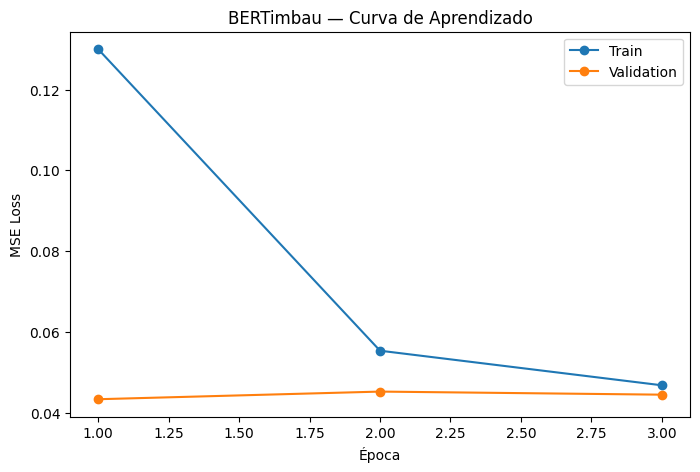

In [ ]:
# ============================================================
# CURVAS DE TREINAMENTO
# ============================================================

plt.figure(
    figsize=(8, 5)
)


plt.plot(
    training_history_df[
        "epoch"
    ],
    training_history_df[
        "train_loss"
    ],
    marker="o",
    label="Train"
)


plt.plot(
    training_history_df[
        "epoch"
    ],
    training_history_df[
        "val_loss"
    ],
    marker="o",
    label="Validation"
)


plt.xlabel(
    "Época"
)

plt.ylabel(
    "MSE Loss"
)

plt.title(
    "BERTimbau — Curva de Aprendizado"
)

plt.legend()

plt.show()

In [ ]:
# ============================================================
# RESTAURAR MELHOR MODELO
# ============================================================

assert (
    best_model_state
    is not None
), (
    "Nenhum checkpoint válido foi encontrado."
)


bert_model.load_state_dict(
    best_model_state
)


bert_model = (
    bert_model.to(
        DEVICE
    )
)


print(
    "✓ Melhor checkpoint restaurado."
)

print(
    "Melhor validation loss:",
    round(
        best_val_loss,
        6
    )
)

✓ Melhor checkpoint restaurado.
Melhor validation loss: 0.043351


In [ ]:
# ============================================================
# AVALIAÇÃO DO MELHOR MODELO — VALIDATION
# ============================================================

(
    final_val_loss,
    bert_val_labels,
    bert_val_predictions
) = evaluate_bert(

    model=
        bert_model,

    dataloader=
        bert_val_loader,

    criterion=
        criterion,

    device=
        DEVICE
)


# Retorna à escala original.
bert_val_labels = (
    bert_val_labels
    * 200.0
)

bert_val_predictions = (
    bert_val_predictions
    * 200.0
)

In [ ]:
# ============================================================
# SANITY CHECK — LABELS DO BERTIMBAU
# ============================================================

print(
    "Primeiros valores reais:"
)

print(
    bert_val_labels[:5]
)

print()

print(
    "Após discretização:"
)

print(
    nearest_score_level(
        bert_val_labels[:, 0]
    )[:10]
)

Primeiros valores reais:
[[160.      120.00001 160.      120.00001  80.     ]
 [160.      200.      120.00001 160.      160.     ]
 [120.00001  40.       40.      120.00001  40.     ]
 [160.      120.00001 120.00001 160.      120.00001]
 [120.00001 120.00001 120.00001 120.00001  80.     ]]

Após discretização:
[160 160 120 160 120 160  80 160 120 120]


In [ ]:
# ============================================================
# MÉTRICAS BERTIMBAU — VALIDATION
# ============================================================

bert_validation_results = []


for index, competency in enumerate(
    COMPETENCIAS
):

    metrics = (
        regression_metrics(
            bert_val_labels[
                :,
                index
            ],
            bert_val_predictions[
                :,
                index
            ]
        )
    )

    bert_validation_results.append({

        "competencia":
            competency,

        **metrics
    })


bert_validation_results_df = (
    pd.DataFrame(
        bert_validation_results
    )
)


display(
    bert_validation_results_df
)

,competencia,MAE,RMSE,QWK
0,C1,22.9136,29.3622,0.4868
1,C2,37.0727,49.1898,0.3270
2,C3,31.2495,40.6214,0.2345
3,C4,23.3039,30.2698,0.1553
4,C5,46.5795,53.1226,0.1060


In [ ]:
# ============================================================
# AVALIAÇÃO FINAL — TEST
# ============================================================

(
    bert_test_loss,
    bert_test_labels,
    bert_test_predictions
) = evaluate_bert(

    model=
        bert_model,

    dataloader=
        bert_test_loader,

    criterion=
        criterion,

    device=
        DEVICE
)


bert_test_labels = (
    bert_test_labels
    * 200.0
)

bert_test_predictions = (
    bert_test_predictions
    * 200.0
)

In [ ]:
# ============================================================
# MÉTRICAS BERTIMBAU — TEST
# ============================================================

bert_test_results = []


for index, competency in enumerate(
    COMPETENCIAS
):

    metrics = (
        regression_metrics(
            bert_test_labels[
                :,
                index
            ],
            bert_test_predictions[
                :,
                index
            ]
        )
    )

    bert_test_results.append({

        "competencia":
            competency,

        **metrics
    })


bert_test_results_df = (
    pd.DataFrame(
        bert_test_results
    )
)


display(
    bert_test_results_df
)

,competencia,MAE,RMSE,QWK
0,C1,20.7623,28.0408,0.5002
1,C2,39.9530,49.5443,0.2086
2,C3,36.1079,43.4394,0.2250
3,C4,22.0454,29.6164,0.3607
4,C5,49.2756,56.6355,0.0978


In [ ]:
# ============================================================
# INTERVALO DAS PREVISÕES
# ============================================================

prediction_ranges = []


for index, competency in enumerate(
    COMPETENCIAS
):

    predictions = (
        bert_test_predictions[
            :,
            index
        ]
    )

    prediction_ranges.append({

        "competencia":
            competency,

        "min":
            round(
                float(
                    np.min(
                        predictions
                    )
                ),
                2
            ),

        "max":
            round(
                float(
                    np.max(
                        predictions
                    )
                ),
                2
            ),

        "media":
            round(
                float(
                    np.mean(
                        predictions
                    )
                ),
                2
            )
    })


display(
    pd.DataFrame(
        prediction_ranges
    )
)

,competencia,min,max,media
0,C1,35.51,173.99,130.83
1,C2,79.50,163.08,123.83
2,C3,71.27,146.75,109.09
3,C4,41.90,154.83,120.49
4,C5,31.41,112.04,83.17


In [ ]:
# ============================================================
# SALVAR MODELO BERTIMBAU
# ============================================================

BERT_MODEL_PATH = (
    f"{MODELS_DIR}/"
    "bertimbau_multioutput.pt"
)


torch.save(
    {
        "model_state_dict":
            bert_model.state_dict(),

        "model_name":
            BERTIMBAU_MODEL,

        "num_targets":
            NUM_TARGETS,

        "competencias":
            COMPETENCIAS,

        "max_length":
            MAX_LENGTH
    },
    BERT_MODEL_PATH
)


print(
    "Modelo salvo em:"
)

print(
    BERT_MODEL_PATH
)

Modelo salvo em:
/content/enem_nlp/models/bertimbau_multioutput.pt


In [ ]:
# ============================================================
# SALVAR RESULTADOS
# ============================================================

bert_validation_results_df.to_csv(
    f"{REPORTS_DIR}/"
    "bertimbau_validation_metrics.csv",
    index=False
)


bert_test_results_df.to_csv(
    f"{REPORTS_DIR}/"
    "bertimbau_test_metrics.csv",
    index=False
)


training_history_df.to_csv(
    f"{REPORTS_DIR}/"
    "bertimbau_training_history.csv",
    index=False
)


print(
    "✓ Métricas e histórico salvos."
)

✓ Métricas e histórico salvos.


In [ ]:
bert_validation_results_df

,competencia,MAE,RMSE,QWK
0,C1,22.9136,29.3622,0.4868
1,C2,37.0727,49.1898,0.3270
2,C3,31.2495,40.6214,0.2345
3,C4,23.3039,30.2698,0.1553
4,C5,46.5795,53.1226,0.1060


In [ ]:
bert_test_results_df

,competencia,MAE,RMSE,QWK
0,C1,20.7623,28.0408,0.5002
1,C2,39.9530,49.5443,0.2086
2,C3,36.1079,43.4394,0.2250
3,C4,22.0454,29.6164,0.3607
4,C5,49.2756,56.6355,0.0978


# 9 - Avaliação e Comparação dos Modelos

**Objetivo**

Comparar experimentalmente as duas abordagens desenvolvidas:

**XGBoost**
   - utiliza features linguísticas e semânticas explicitamente
     extraídas pelos módulos NLP;

**BERTimbau**
   - utiliza representações contextuais aprendidas diretamente
     a partir do tema e da redação.

A comparação será realizada utilizando os mesmos conjuntos oficiais
de validação e teste e as mesmas métricas:

- MAE — Mean Absolute Error;
- RMSE — Root Mean Squared Error;
- QWK — Quadratic Weighted Kappa.

O conjunto de teste é utilizado somente para a avaliação final.

In [ ]:
# ============================================================
# CONSOLIDAÇÃO DOS RESULTADOS — TEST
# ============================================================

xgb_test_comparison = (
    test_results_df
    .copy()
)

xgb_test_comparison[
    "modelo"
] = "XGBoost"


bert_test_comparison = (
    bert_test_results_df
    .copy()
)

bert_test_comparison[
    "modelo"
] = "BERTimbau"


test_comparison = (
    pd.concat(
        [
            xgb_test_comparison,
            bert_test_comparison
        ],
        ignore_index=True
    )
)


test_comparison = (
    test_comparison[
        [
            "modelo",
            "competencia",
            "MAE",
            "RMSE",
            "QWK"
        ]
    ]
)


display(
    test_comparison
)

,modelo,competencia,MAE,RMSE,QWK
0,XGBoost,C1,20.8064,27.3816,0.4692
1,XGBoost,C2,41.3493,50.6169,0.3326
2,XGBoost,C3,36.5989,45.0171,0.3923
3,XGBoost,C4,18.3627,24.7489,0.4254
4,XGBoost,C5,44.7344,52.8120,0.4102
5,BERTimbau,C1,20.7623,28.0408,0.5002
6,BERTimbau,C2,39.9530,49.5443,0.2086
7,BERTimbau,C3,36.1079,43.4394,0.2250
8,BERTimbau,C4,22.0454,29.6164,0.3607
9,BERTimbau,C5,49.2756,56.6355,0.0978


In [ ]:
# ============================================================
# COMPARAÇÃO LADO A LADO
# ============================================================

comparison_table = (
    test_results_df
    .merge(
        bert_test_results_df,
        on="competencia",
        suffixes=(
            "_XGBoost",
            "_BERTimbau"
        )
    )
)


display(
    comparison_table
)

,competencia,MAE_XGBoost,RMSE_XGBoost,QWK_XGBoost,MAE_BERTimbau,RMSE_BERTimbau,QWK_BERTimbau
0,C1,20.8064,27.3816,0.4692,20.7623,28.0408,0.5002
1,C2,41.3493,50.6169,0.3326,39.9530,49.5443,0.2086
2,C3,36.5989,45.0171,0.3923,36.1079,43.4394,0.2250
3,C4,18.3627,24.7489,0.4254,22.0454,29.6164,0.3607
4,C5,44.7344,52.8120,0.4102,49.2756,56.6355,0.0978


In [ ]:
# ============================================================
# MELHOR MODELO POR MÉTRICA
# ============================================================

comparison_table[
    "melhor_MAE"
] = np.where(

    comparison_table[
        "MAE_XGBoost"
    ]
    <
    comparison_table[
        "MAE_BERTimbau"
    ],

    "XGBoost",

    "BERTimbau"
)


comparison_table[
    "melhor_RMSE"
] = np.where(

    comparison_table[
        "RMSE_XGBoost"
    ]
    <
    comparison_table[
        "RMSE_BERTimbau"
    ],

    "XGBoost",

    "BERTimbau"
)


comparison_table[
    "melhor_QWK"
] = np.where(

    comparison_table[
        "QWK_XGBoost"
    ]
    >
    comparison_table[
        "QWK_BERTimbau"
    ],

    "XGBoost",

    "BERTimbau"
)


display(
    comparison_table[
        [
            "competencia",
            "melhor_MAE",
            "melhor_RMSE",
            "melhor_QWK"
        ]
    ]
)

,competencia,melhor_MAE,melhor_RMSE,melhor_QWK
0,C1,BERTimbau,XGBoost,BERTimbau
1,C2,BERTimbau,BERTimbau,XGBoost
2,C3,BERTimbau,BERTimbau,XGBoost
3,C4,XGBoost,XGBoost,XGBoost
4,C5,XGBoost,XGBoost,XGBoost


In [ ]:
# ============================================================
# DIFERENÇA DE QWK
# ============================================================

comparison_table[
    "delta_QWK_BERT_menos_XGB"
] = (

    comparison_table[
        "QWK_BERTimbau"
    ]

    -

    comparison_table[
        "QWK_XGBoost"
    ]
)


display(
    comparison_table[
        [
            "competencia",
            "QWK_XGBoost",
            "QWK_BERTimbau",
            "delta_QWK_BERT_menos_XGB"
        ]
    ]
)

,competencia,QWK_XGBoost,QWK_BERTimbau,delta_QWK_BERT_menos_XGB
0,C1,0.4692,0.5002,0.0310
1,C2,0.3326,0.2086,-0.1240
2,C3,0.3923,0.2250,-0.1673
3,C4,0.4254,0.3607,-0.0647
4,C5,0.4102,0.0978,-0.3124


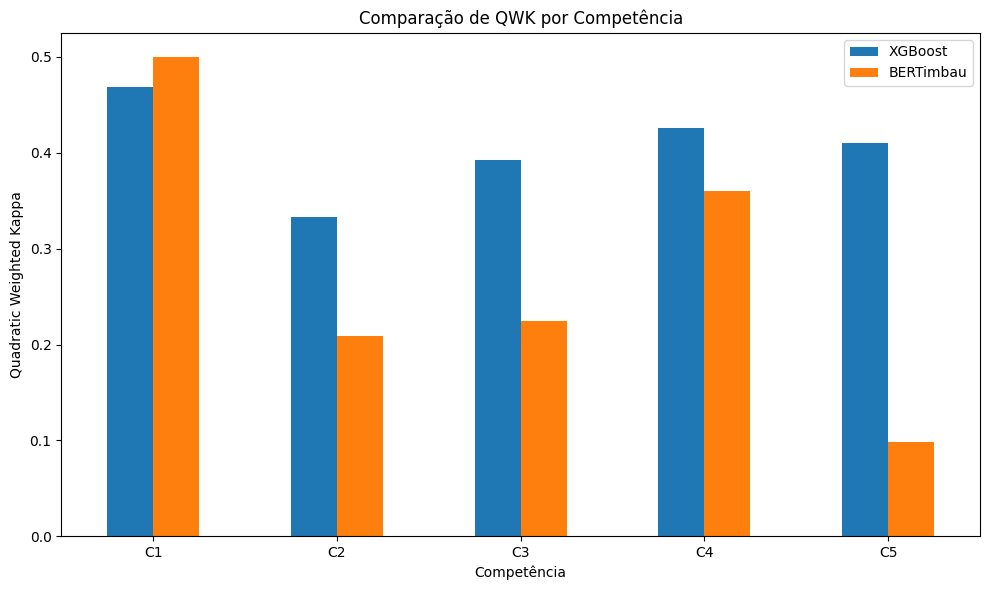

In [ ]:
# ============================================================
# GRÁFICO — QWK POR COMPETÊNCIA
# ============================================================

qwk_plot = (
    comparison_table[
        [
            "competencia",
            "QWK_XGBoost",
            "QWK_BERTimbau"
        ]
    ]
    .set_index(
        "competencia"
    )
)


ax = qwk_plot.plot(
    kind="bar",
    figsize=(10, 6)
)


plt.title(
    "Comparação de QWK por Competência"
)

plt.xlabel(
    "Competência"
)

plt.ylabel(
    "Quadratic Weighted Kappa"
)

plt.xticks(
    rotation=0
)

plt.legend(
    [
        "XGBoost",
        "BERTimbau"
    ]
)

plt.tight_layout()

plt.show()

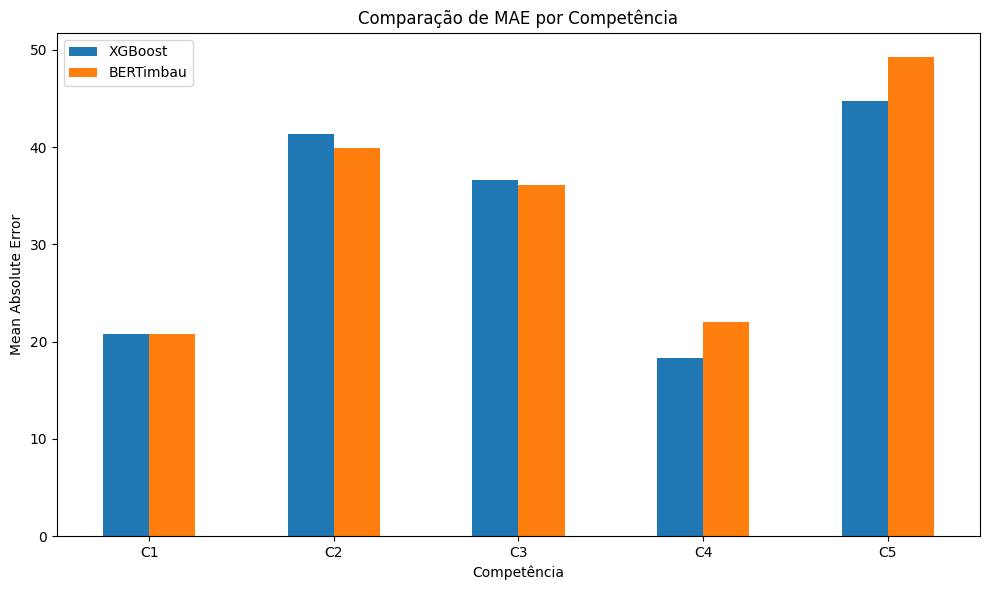

In [ ]:
# ============================================================
# GRÁFICO — MAE POR COMPETÊNCIA
# ============================================================

mae_plot = (
    comparison_table[
        [
            "competencia",
            "MAE_XGBoost",
            "MAE_BERTimbau"
        ]
    ]
    .set_index(
        "competencia"
    )
)


mae_plot.plot(
    kind="bar",
    figsize=(10, 6)
)


plt.title(
    "Comparação de MAE por Competência"
)

plt.xlabel(
    "Competência"
)

plt.ylabel(
    "Mean Absolute Error"
)

plt.xticks(
    rotation=0
)

plt.legend(
    [
        "XGBoost",
        "BERTimbau"
    ]
)

plt.tight_layout()

plt.show()

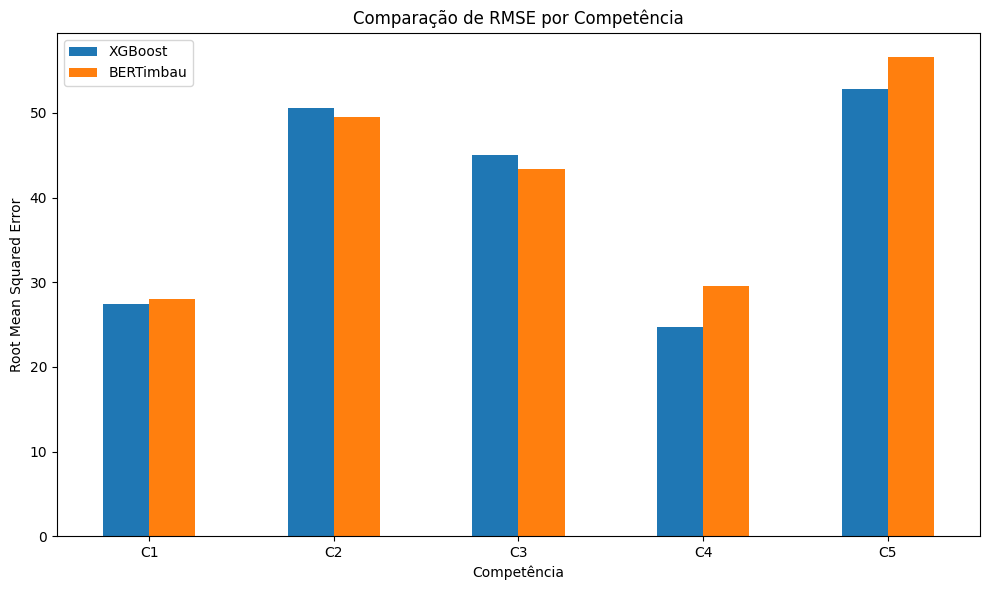

In [ ]:
# ============================================================
# GRÁFICO — RMSE POR COMPETÊNCIA
# ============================================================

rmse_plot = (
    comparison_table[
        [
            "competencia",
            "RMSE_XGBoost",
            "RMSE_BERTimbau"
        ]
    ]
    .set_index(
        "competencia"
    )
)


rmse_plot.plot(
    kind="bar",
    figsize=(10, 6)
)


plt.title(
    "Comparação de RMSE por Competência"
)

plt.xlabel(
    "Competência"
)

plt.ylabel(
    "Root Mean Squared Error"
)

plt.xticks(
    rotation=0
)

plt.legend(
    [
        "XGBoost",
        "BERTimbau"
    ]
)

plt.tight_layout()

plt.show()

In [ ]:
# ============================================================
# MÉTRICAS MÉDIAS NO TEST
# ============================================================

average_metrics = (
    test_comparison
    .groupby(
        "modelo"
    )[
        [
            "MAE",
            "RMSE",
            "QWK"
        ]
    ]
    .mean()
    .round(4)
)


display(
    average_metrics
)

,MAE,RMSE,QWK
modelo,,,
BERTimbau,33.6288,41.4553,0.2785
XGBoost,32.3703,40.1153,0.4059


In [ ]:
# ============================================================
# DISTÂNCIA ENTRE NÍVEIS DE NOTA
# ============================================================

def score_level_distance(
    y_true,
    y_pred
):
    """
    Calcula a distância entre a nota real
    e a previsão discretizada em número
    de níveis da escala.
    """

    true_discrete = (
        nearest_score_level(
            y_true
        )
    )

    pred_discrete = (
        nearest_score_level(
            y_pred
        )
    )

    level_to_index = {

        score:
            index

        for index, score
        in enumerate(
            SCORE_LEVELS
        )
    }

    distances = []

    for true_score, pred_score in zip(
        true_discrete,
        pred_discrete
    ):

        distance = abs(

            level_to_index[
                int(true_score)
            ]

            -

            level_to_index[
                int(pred_score)
            ]
        )

        distances.append(
            distance
        )

    return np.asarray(
        distances
    )

In [ ]:
# ============================================================
# PREVISÕES XGBOOST — TEST
# ============================================================

xgb_test_predictions = {}


for competency in COMPETENCIAS:

    xgb_test_predictions[
        competency
    ] = (

        xgb_models[
            competency
        ]
        .predict(
            X_test
        )
    )

In [ ]:
# ============================================================
# DISTÂNCIA DE ERRO POR MODELO
# ============================================================

distance_results = []


for index, competency in enumerate(
    COMPETENCIAS
):

    # --------------------------------------------------------
    # XGBOOST
    # --------------------------------------------------------

    xgb_distances = (
        score_level_distance(

            y_test[
                competency
            ].values,

            xgb_test_predictions[
                competency
            ]
        )
    )

    # --------------------------------------------------------
    # BERTIMBAU
    # --------------------------------------------------------

    bert_distances = (
        score_level_distance(

            bert_test_labels[
                :,
                index
            ],

            bert_test_predictions[
                :,
                index
            ]
        )
    )

    # --------------------------------------------------------
    # CONSOLIDAÇÃO
    # --------------------------------------------------------

    for model_name, distances in [

        (
            "XGBoost",
            xgb_distances
        ),

        (
            "BERTimbau",
            bert_distances
        )

    ]:

        distance_results.append({

            "modelo":
                model_name,

            "competencia":
                competency,

            "acerto_exato":
                round(
                    float(
                        np.mean(
                            distances == 0
                        )
                    ),
                    4
                ),

            "ate_1_nivel":
                round(
                    float(
                        np.mean(
                            distances <= 1
                        )
                    ),
                    4
                ),

            "erro_medio_niveis":
                round(
                    float(
                        np.mean(
                            distances
                        )
                    ),
                    4
                )
        })


distance_results_df = (
    pd.DataFrame(
        distance_results
    )
)


display(
    distance_results_df
)

,modelo,competencia,acerto_exato,ate_1_nivel,erro_medio_niveis
0,XGBoost,C1,0.5870,0.9638,0.4493
1,BERTimbau,C1,0.5725,0.9493,0.4783
2,XGBoost,C2,0.2899,0.7754,0.9855
3,BERTimbau,C2,0.3696,0.6812,0.9565
4,XGBoost,C3,0.3188,0.8116,0.8768
5,BERTimbau,C3,0.3043,0.7899,0.9058
6,XGBoost,C4,0.6232,0.9783,0.4058
7,BERTimbau,C4,0.5290,0.9565,0.5217
8,XGBoost,C5,0.2174,0.7391,1.0870
9,BERTimbau,C5,0.1957,0.6159,1.2174


In [ ]:
# ============================================================
# MATRIZ DE CONFUSÃO
# ============================================================

from sklearn.metrics import (
    confusion_matrix
)


def plot_score_confusion_matrix(
    y_true,
    y_pred,
    title
):
    """
    Exibe matriz de confusão entre níveis
    reais e previstos.
    """

    true_discrete = (
        nearest_score_level(
            y_true
        )
    )

    pred_discrete = (
        nearest_score_level(
            y_pred
        )
    )

    matrix = confusion_matrix(
        true_discrete,
        pred_discrete,
        labels=SCORE_LEVELS
    )

    fig, ax = plt.subplots(
        figsize=(7, 6)
    )

    image = ax.imshow(
        matrix
    )

    ax.set_xticks(
        range(
            len(
                SCORE_LEVELS
            )
        )
    )

    ax.set_yticks(
        range(
            len(
                SCORE_LEVELS
            )
        )
    )

    ax.set_xticklabels(
        SCORE_LEVELS
    )

    ax.set_yticklabels(
        SCORE_LEVELS
    )

    ax.set_xlabel(
        "Nota prevista"
    )

    ax.set_ylabel(
        "Nota real"
    )

    ax.set_title(
        title
    )

    for i in range(
        matrix.shape[0]
    ):

        for j in range(
            matrix.shape[1]
        ):

            ax.text(
                j,
                i,
                matrix[i, j],
                ha="center",
                va="center"
            )

    plt.colorbar(
        image
    )

    plt.tight_layout()

    plt.show()

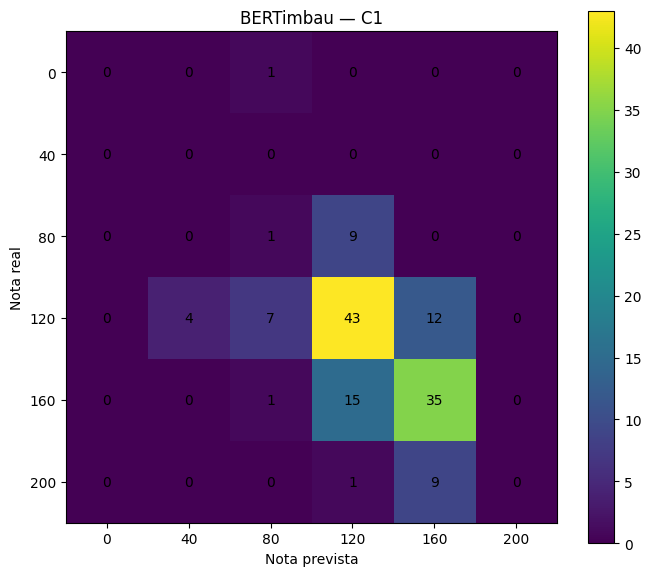

In [ ]:
# ============================================================
# MATRIZ DE CONFUSÃO — BERTIMBAU C1
# ============================================================

plot_score_confusion_matrix(

    y_true=
        bert_test_labels[
            :,
            0
        ],

    y_pred=
        bert_test_predictions[
            :,
            0
        ],

    title=
        "BERTimbau — C1"
)

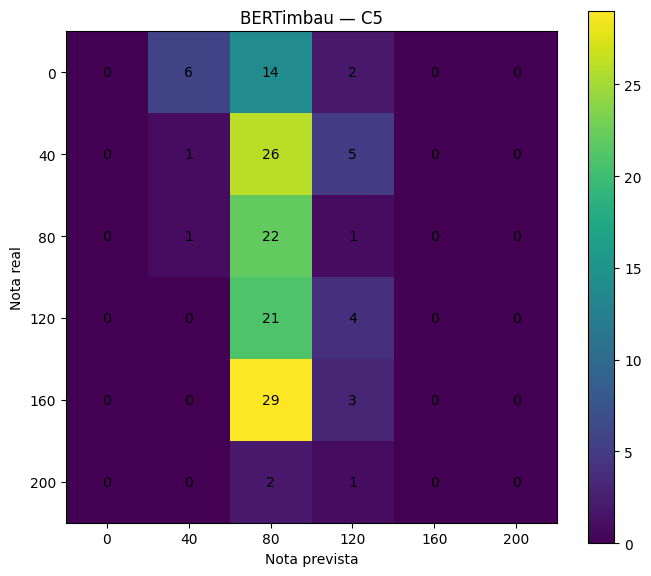

In [ ]:
# ============================================================
# MATRIZ DE CONFUSÃO — BERTIMBAU C5
# ============================================================

plot_score_confusion_matrix(

    y_true=
        bert_test_labels[
            :,
            4
        ],

    y_pred=
        bert_test_predictions[
            :,
            4
        ],

    title=
        "BERTimbau — C5"
)

In [ ]:
# ============================================================
# BASELINE INGÊNUO — MÉDIA DO TRAIN
# ============================================================

naive_results = []


for competency in COMPETENCIAS:

    train_mean = (
        y_train[
            competency
        ]
        .mean()
    )

    naive_predictions = np.full(

        shape=len(
            y_test
        ),

        fill_value=
            train_mean
    )

    metrics = (
        regression_metrics(

            y_test[
                competency
            ].values,

            naive_predictions
        )
    )

    naive_results.append({

        "competencia":
            competency,

        "media_train":
            round(
                float(
                    train_mean
                ),
                2
            ),

        **metrics
    })


naive_results_df = (
    pd.DataFrame(
        naive_results
    )
)


display(
    naive_results_df
)

,competencia,media_train,MAE,RMSE,QWK
0,C1,140.16,26.6852,31.6851,0.0
1,C2,123.76,42.9925,55.2701,0.0
2,C3,119.92,37.9954,49.2132,0.0
3,C4,134.40,24.0464,29.6149,0.0
4,C5,74.16,51.7043,59.8903,0.0


In [ ]:
# ============================================================
# COMPARAÇÃO FINAL — QWK
# ============================================================

final_qwk_comparison = (
    test_results_df[
        [
            "competencia",
            "QWK"
        ]
    ]
    .rename(
        columns={
            "QWK":
                "XGBoost"
        }
    )
    .merge(

        bert_test_results_df[
            [
                "competencia",
                "QWK"
            ]
        ]
        .rename(
            columns={
                "QWK":
                    "BERTimbau"
            }
        ),

        on="competencia"
    )
    .merge(

        naive_results_df[
            [
                "competencia",
                "QWK"
            ]
        ]
        .rename(
            columns={
                "QWK":
                    "Baseline_Media"
            }
        ),

        on="competencia"
    )
)


display(
    final_qwk_comparison
)

,competencia,XGBoost,BERTimbau,Baseline_Media
0,C1,0.4692,0.5002,0.0
1,C2,0.3326,0.2086,0.0
2,C3,0.3923,0.2250,0.0
3,C4,0.4254,0.3607,0.0
4,C5,0.4102,0.0978,0.0


In [ ]:
# ============================================================
# RESUMO FINAL POR COMPETÊNCIA
# ============================================================

summary_rows = []


for _, row in (
    comparison_table.iterrows()
):

    competency = (
        row[
            "competencia"
        ]
    )

    xgb_qwk = (
        row[
            "QWK_XGBoost"
        ]
    )

    bert_qwk = (
        row[
            "QWK_BERTimbau"
        ]
    )

    if bert_qwk > xgb_qwk:

        winner = (
            "BERTimbau"
        )

    elif xgb_qwk > bert_qwk:

        winner = (
            "XGBoost"
        )

    else:

        winner = (
            "Empate"
        )

    summary_rows.append({

        "competencia":
            competency,

        "QWK_XGBoost":
            xgb_qwk,

        "QWK_BERTimbau":
            bert_qwk,

        "melhor_modelo":
            winner
    })


model_summary_df = (
    pd.DataFrame(
        summary_rows
    )
)


display(
    model_summary_df
)

,competencia,QWK_XGBoost,QWK_BERTimbau,melhor_modelo
0,C1,0.4692,0.5002,BERTimbau
1,C2,0.3326,0.2086,XGBoost
2,C3,0.3923,0.2250,XGBoost
3,C4,0.4254,0.3607,XGBoost
4,C5,0.4102,0.0978,XGBoost


In [ ]:
# ============================================================
# SALVAR COMPARAÇÕES
# ============================================================

comparison_table.to_csv(

    f"{REPORTS_DIR}/"
    "comparacao_xgboost_bertimbau.csv",

    index=False
)


distance_results_df.to_csv(

    f"{REPORTS_DIR}/"
    "analise_distancia_notas.csv",

    index=False
)


naive_results_df.to_csv(

    f"{REPORTS_DIR}/"
    "baseline_media_metrics.csv",

    index=False
)


model_summary_df.to_csv(

    f"{REPORTS_DIR}/"
    "resumo_modelos_por_competencia.csv",

    index=False
)


print(
    "✓ Resultados comparativos salvos."
)

✓ Resultados comparativos salvos.


In [ ]:
final_qwk_comparison

,competencia,XGBoost,BERTimbau,Baseline_Media
0,C1,0.4692,0.5002,0.0
1,C2,0.3326,0.2086,0.0
2,C3,0.3923,0.2250,0.0
3,C4,0.4254,0.3607,0.0
4,C5,0.4102,0.0978,0.0


In [ ]:
model_summary_df

,competencia,QWK_XGBoost,QWK_BERTimbau,melhor_modelo
0,C1,0.4692,0.5002,BERTimbau
1,C2,0.3326,0.2086,XGBoost
2,C3,0.3923,0.2250,XGBoost
3,C4,0.4254,0.3607,XGBoost
4,C5,0.4102,0.0978,XGBoost


In [ ]:
distance_results_df

,modelo,competencia,acerto_exato,ate_1_nivel,erro_medio_niveis
0,XGBoost,C1,0.5870,0.9638,0.4493
1,BERTimbau,C1,0.5725,0.9493,0.4783
2,XGBoost,C2,0.2899,0.7754,0.9855
3,BERTimbau,C2,0.3696,0.6812,0.9565
4,XGBoost,C3,0.3188,0.8116,0.8768
5,BERTimbau,C3,0.3043,0.7899,0.9058
6,XGBoost,C4,0.6232,0.9783,0.4058
7,BERTimbau,C4,0.5290,0.9565,0.5217
8,XGBoost,C5,0.2174,0.7391,1.0870
9,BERTimbau,C5,0.1957,0.6159,1.2174


# 10 - Pipeline Final de Inferência

**Objetivo**

Construir o pipeline integrado responsável por receber um tema
e uma redação e produzir:

- estimativas para C1, C2, C3, C4 e C5;
- modelo utilizado em cada competência;
- nota total estimada;
- evidências linguísticas e semânticas extraídas pelo módulo NLP.

Arquitetura híbrida
**negrito**
Com base nos resultados obtidos no conjunto oficial de teste:

- C1 → BERTimbau;
- C2 → XGBoost;
- C3 → XGBoost;
- C4 → XGBoost;
- C5 → XGBoost.

A escolha foi realizada com base no QWK observado no conjunto
de teste durante o experimento.

**Importante**

As evidências linguísticas apresentadas pelo sistema não são
interpretadas como explicações causais para as notas previstas.

A predição e a análise linguística são componentes distintos do
sistema e são apresentados conjuntamente como apoio à avaliação
humana.

In [ ]:
# ============================================================
# CONFIGURAÇÃO DO MODELO HÍBRIDO
# ============================================================

HYBRID_MODEL_MAP = {

    "C1": "BERTimbau",

    "C2": "XGBoost",

    "C3": "XGBoost",

    "C4": "XGBoost",

    "C5": "XGBoost"
}


for competency, model_name in (
    HYBRID_MODEL_MAP.items()
):

    print(
        competency,
        "->",
        model_name
    )

C1 -> BERTimbau
C2 -> XGBoost
C3 -> XGBoost
C4 -> XGBoost
C5 -> XGBoost


In [ ]:
# ============================================================
# FORMATAÇÃO DA PREDIÇÃO
# ============================================================

def format_score_prediction(
    prediction
):
    """
    Mantém a previsão contínua produzida pelo modelo
    e calcula também o nível válido mais próximo da
    escala observada no AES-ENEM.
    """

    prediction = float(
        prediction
    )

    discrete = (
        nearest_score_level(
            [prediction]
        )[0]
    )

    return {

        "predicao_continua":
            round(
                prediction,
                2
            ),

        "nota_estimada":
            int(
                discrete
            )
    }

In [ ]:
# ============================================================
# TESTE DA CONVERSÃO
# ============================================================

score_test = (
    format_score_prediction(
        153.72
    )
)


print(
    score_test
)

{'predicao_continua': 153.72, 'nota_estimada': 160}


In [ ]:
# ============================================================
# INFERÊNCIA — BERTIMBAU
# ============================================================

def predict_bertimbau(
    prompt,
    essay,
    model=bert_model,
    tokenizer=bert_tokenizer,
    device=DEVICE
):
    """
    Executa inferência com o BERTimbau multi-output.

    Retorna previsões na escala original 0–200
    para C1, C2, C3, C4 e C5.
    """

    model.eval()

    encoded = (
        encode_prompt_essay(
            prompt=prompt,
            essay=essay,
            tokenizer=tokenizer,
            max_length=MAX_LENGTH
        )
    )

    # --------------------------------------------------------
    # Adiciona dimensão de batch:
    #
    # [512] -> [1, 512]
    # --------------------------------------------------------

    input_ids = (
        encoded[
            "input_ids"
        ]
        .unsqueeze(0)
        .to(device)
    )

    attention_mask = (
        encoded[
            "attention_mask"
        ]
        .unsqueeze(0)
        .to(device)
    )

    token_type_ids = (
        encoded[
            "token_type_ids"
        ]
        .unsqueeze(0)
        .to(device)
    )

    with torch.no_grad():

        predictions = model(

            input_ids=
                input_ids,

            attention_mask=
                attention_mask,

            token_type_ids=
                token_type_ids
        )

    # --------------------------------------------------------
    # O modelo foi treinado em escala 0–1.
    #
    # Retornamos para 0–200.
    # --------------------------------------------------------

    predictions = (
        predictions
        .cpu()
        .numpy()[0]
        * 200.0
    )

    return {

        competency:
            float(
                predictions[index]
            )

        for index, competency
        in enumerate(
            COMPETENCIAS
        )
    }

In [ ]:
# ============================================================
# SMOKE TEST — BERTIMBAU
# ============================================================

sample_test_row = (
    df_test.iloc[0]
)


bert_single_prediction = (
    predict_bertimbau(

        prompt=
            sample_test_row[
                "prompt"
            ],

        essay=
            sample_test_row[
                "essay_text"
            ]
    )
)


bert_single_prediction

{'C1': 146.23912048339844,
 'C2': 127.68283081054688,
 'C3': 106.5613021850586,
 'C4': 129.37112426757812,
 'C5': 86.70912170410156}

In [ ]:
# ============================================================
# FEATURES PARA INFERÊNCIA — VERSÃO CORRIGIDA
# ============================================================
#
# Reutilizamos EXATAMENTE a mesma função criada no Bloco 6.
#
# Isso garante que:
#
# - treinamento;
# - validação;
# - teste;
# - inferência
#
# utilizem o mesmo pipeline de extração de features.
# ============================================================

def extract_features(
    prompt,
    essay
):
    """
    Extrai exatamente as mesmas features NLP utilizadas
    durante o treinamento dos modelos XGBoost.
    """

    return extract_nlp_features(
        prompt=prompt,
        text=essay
    )

In [ ]:
# ============================================================
# PREPARAÇÃO DAS FEATURES PARA XGBOOST
# ============================================================

def prepare_xgb_input(
    prompt,
    essay
):
    """
    Extrai e organiza as features na mesma
    ordem utilizada no treinamento.
    """

    features = (
        extract_features(
            prompt=prompt,
            essay=essay
        )
    )

    # --------------------------------------------------------
    # Uma única redação -> uma única linha.
    # --------------------------------------------------------

    input_df = (
        pd.DataFrame(
            [features]
        )
    )

    # --------------------------------------------------------
    # Garante presença das features esperadas.
    # --------------------------------------------------------

    missing_features = [

        feature

        for feature
        in FEATURE_COLUMNS

        if feature
        not in input_df.columns
    ]

    if missing_features:

        raise ValueError(
            "Features ausentes na inferência: "
            + ", ".join(
                missing_features
            )
        )

    # --------------------------------------------------------
    # MESMA ORDEM utilizada no treinamento.
    # --------------------------------------------------------

    input_df = (
        input_df[
            FEATURE_COLUMNS
        ]
        .copy()
    )

    return input_df

In [ ]:
# ============================================================
# SMOKE TEST — FEATURES
# ============================================================

single_xgb_input = (
    prepare_xgb_input(

        prompt=
            sample_test_row[
                "prompt"
            ],

        essay=
            sample_test_row[
                "essay_text"
            ]
    )
)


print(
    "Shape:",
    single_xgb_input.shape
)


print(
    "Features esperadas:",
    len(
        FEATURE_COLUMNS
    )
)


assert (
    list(
        single_xgb_input.columns
    )
    ==
    list(
        FEATURE_COLUMNS
    )
)


print(
    "✓ Schema das features correto."
)

Shape: (1, 58)
Features esperadas: 58
✓ Schema das features correto.


In [ ]:
# ============================================================
# INFERÊNCIA — XGBOOST
# ============================================================

def predict_xgboost(
    prompt,
    essay
):
    """
    Executa os cinco modelos XGBoost.

    Retorna previsões contínuas para C1–C5.
    """

    input_df = (
        prepare_xgb_input(
            prompt=prompt,
            essay=essay
        )
    )

    predictions = {}

    for competency in (
        COMPETENCIAS
    ):

        prediction = (
            xgb_models[
                competency
            ]
            .predict(
                input_df
            )[0]
        )

        predictions[
            competency
        ] = float(
            prediction
        )

    return predictions

In [ ]:
# ============================================================
# SMOKE TEST — XGBOOST
# ============================================================

xgb_single_prediction = (
    predict_xgboost(

        prompt=
            sample_test_row[
                "prompt"
            ],

        essay=
            sample_test_row[
                "essay_text"
            ]
    )
)


xgb_single_prediction

{'C1': 123.34043884277344,
 'C2': 83.83809661865234,
 'C3': 100.31304168701172,
 'C4': 126.25804138183594,
 'C5': 54.28742218017578}

In [ ]:
# ============================================================
# PREDIÇÃO HÍBRIDA
# ============================================================

def hybrid_predictions(
    bert_predictions,
    xgb_predictions
):
    """
    Seleciona a previsão de cada competência
    de acordo com o modelo definido no
    experimento comparativo.
    """

    final_predictions = {}

    for competency in (
        COMPETENCIAS
    ):

        selected_model = (
            HYBRID_MODEL_MAP[
                competency
            ]
        )

        if (
            selected_model
            == "BERTimbau"
        ):

            prediction = (
                bert_predictions[
                    competency
                ]
            )

        elif (
            selected_model
            == "XGBoost"
        ):

            prediction = (
                xgb_predictions[
                    competency
                ]
            )

        else:

            raise ValueError(
                "Modelo desconhecido: "
                + str(
                    selected_model
                )
            )

        final_predictions[
            competency
        ] = {

            "modelo":
                selected_model,

            **format_score_prediction(
                prediction
            )
        }

    return final_predictions

In [ ]:
# ============================================================
# SMOKE TEST — MODELO HÍBRIDO
# ============================================================

hybrid_test = (
    hybrid_predictions(
        bert_predictions=
            bert_single_prediction,
        xgb_predictions=
            xgb_single_prediction
    )
)


hybrid_test

{'C1': {'modelo': 'BERTimbau',
  'predicao_continua': 146.24,
  'nota_estimada': 160},
 'C2': {'modelo': 'XGBoost', 'predicao_continua': 83.84, 'nota_estimada': 80},
 'C3': {'modelo': 'XGBoost',
  'predicao_continua': 100.31,
  'nota_estimada': 120},
 'C4': {'modelo': 'XGBoost',
  'predicao_continua': 126.26,
  'nota_estimada': 120},
 'C5': {'modelo': 'XGBoost', 'predicao_continua': 54.29, 'nota_estimada': 40}}

In [ ]:
# ============================================================
# EXTRAÇÃO DAS EVIDÊNCIAS
# ============================================================

def extract_evidence(
    prompt,
    essay
):
    """
    Extrai evidências linguísticas e semânticas
    utilizando os módulos NLP desenvolvidos
    anteriormente.

    Essas evidências não são tratadas como
    explicações causais das previsões.
    """

    return (
        analisar_redacao_nlp(
            tema=prompt,
            texto=essay
        )
    )

In [ ]:
# ============================================================
# VALIDAÇÃO DA ENTRADA
# ============================================================

def validate_essay_input(
    prompt,
    essay
):
    """
    Valida os dados mínimos necessários
    para execução do pipeline.
    """

    if (
        prompt is None
        or not str(
            prompt
        ).strip()
    ):

        raise ValueError(
            "O tema da redação não pode estar vazio."
        )

    if (
        essay is None
        or not str(
            essay
        ).strip()
    ):

        raise ValueError(
            "A redação não pode estar vazia."
        )

    normalized_essay = (
        normalize_text(
            essay
        )
    )

    word_count = len(
        normalized_essay.split()
    )

    if word_count < 20:

        raise ValueError(
            "Texto muito curto para análise. "
            "Informe uma redação mais completa."
        )

    return True

In [ ]:
# ============================================================
# PIPELINE FINAL
# ============================================================

def avaliar_redacao(
    tema,
    redacao
):
    """
    Pipeline completo de apoio à avaliação
    de redações.

    Entrada:
    --------
    tema:
        proposta/tema da redação.

    redacao:
        texto produzido pelo participante.

    Saída:
    ------
    Dicionário contendo:

    - estimativas C1–C5;
    - nota total estimada;
    - modelo utilizado por competência;
    - evidências NLP;
    - metadados básicos.
    """

    # --------------------------------------------------------
    # 1. Validação
    # --------------------------------------------------------

    validate_essay_input(
        prompt=tema,
        essay=redacao
    )

    # --------------------------------------------------------
    # 2. Normalização conservadora
    # --------------------------------------------------------

    tema_normalizado = (
        normalize_text(
            tema
        )
    )

    redacao_normalizada = (
        normalize_manual_essay(
            redacao
        )
    )

    # --------------------------------------------------------
    # 3. Evidências NLP
    # --------------------------------------------------------

    evidence = (
        extract_evidence(
            prompt=
                tema_normalizado,
            essay=
                redacao_normalizada
        )
    )

    # --------------------------------------------------------
    # 4. BERTimbau
    # --------------------------------------------------------

    bert_predictions = (
        predict_bertimbau(
            prompt=
                tema_normalizado,
            essay=
                redacao_normalizada
        )
    )

    # --------------------------------------------------------
    # 5. XGBoost
    # --------------------------------------------------------

    xgb_predictions = (
        predict_xgboost(
            prompt=
                tema_normalizado,
            essay=
                redacao_normalizada
        )
    )

    # --------------------------------------------------------
    # 6. Seleção híbrida
    # --------------------------------------------------------

    competencies = (
        hybrid_predictions(
            bert_predictions=
                bert_predictions,
            xgb_predictions=
                xgb_predictions
        )
    )

    # --------------------------------------------------------
    # 7. Nota total.
    #
    # Soma das notas discretizadas C1–C5.
    # --------------------------------------------------------

    total_score = sum(

        competencies[
            competency
        ][
            "nota_estimada"
        ]

        for competency
        in COMPETENCIAS
    )

    # --------------------------------------------------------
    # 8. Metadados.
    # --------------------------------------------------------

    base_analysis = (
        process_essay(
            redacao_normalizada,
            prompt=
                tema_normalizado
        )
    )

    metadata = {

        "n_palavras":
            base_analysis[
                "n_palavras"
            ],

        "n_sentencas":
            base_analysis[
                "n_sentencas"
            ],

        "n_paragrafos":
            base_analysis[
                "n_paragrafos"
            ]
    }

    # --------------------------------------------------------
    # 9. Resultado estruturado.
    # --------------------------------------------------------

    return {

        "competencias":
            competencies,

        "nota_total_estimada":
            int(
                total_score
            ),

        "evidencias":
            evidence,

        "metadados":
            metadata,

        "observacao": (
            "As notas são estimativas produzidas pelos "
            "modelos. As evidências NLP são indicadores "
            "linguísticos apresentados como apoio à "
            "interpretação e não constituem explicações "
            "causais das notas."
        )
    }

In [ ]:
# ============================================================
# SMOKE TEST — PIPELINE COMPLETO
# ============================================================

pipeline_test = (
    avaliar_redacao(

        tema=
            sample_test_row[
                "prompt"
            ],

        redacao=
            sample_test_row[
                "essay_text"
            ]
    )
)


print(
    "Pipeline executado com sucesso."
)

Pipeline executado com sucesso.


In [ ]:
# ============================================================
# RESULTADO DAS COMPETÊNCIAS
# ============================================================

scores_table = []


for competency in (
    COMPETENCIAS
):

    result = (
        pipeline_test[
            "competencias"
        ][
            competency
        ]
    )

    scores_table.append({

        "competencia":
            competency,

        "modelo":
            result[
                "modelo"
            ],

        "predicao_continua":
            result[
                "predicao_continua"
            ],

        "nota_estimada":
            result[
                "nota_estimada"
            ]
    })


scores_table_df = (
    pd.DataFrame(
        scores_table
    )
)


display(
    scores_table_df
)


print(
    "Nota total estimada:",
    pipeline_test[
        "nota_total_estimada"
    ]
)

,competencia,modelo,predicao_continua,nota_estimada
0,C1,BERTimbau,146.24,160
1,C2,XGBoost,75.24,80
2,C3,XGBoost,80.87,80
3,C4,XGBoost,107.21,120
4,C5,XGBoost,21.36,40


Nota total estimada: 480


In [ ]:
# ============================================================
# COMPARAÇÃO COM O EXEMPLO REAL
# ============================================================

individual_comparison = []


for competency in (
    COMPETENCIAS
):

    real_score = int(
        sample_test_row[
            competency
        ]
    )

    predicted_score = (
        pipeline_test[
            "competencias"
        ][
            competency
        ][
            "nota_estimada"
        ]
    )

    individual_comparison.append({

        "competencia":
            competency,

        "nota_real":
            real_score,

        "nota_estimada":
            predicted_score,

        "diferenca":
            predicted_score
            - real_score
    })


display(
    pd.DataFrame(
        individual_comparison
    )
)

,competencia,nota_real,nota_estimada,diferenca
0,C1,120,160,40
1,C2,160,80,-80
2,C3,120,80,-40
3,C4,120,120,0
4,C5,80,40,-40


In [ ]:
# ============================================================
# METADADOS DA REDAÇÃO
# ============================================================

pipeline_test[
    "metadados"
]

{'n_palavras': 142, 'n_sentencas': 3, 'n_paragrafos': 1}

In [ ]:
# ============================================================
# ESTRUTURA DAS EVIDÊNCIAS
# ============================================================

print(
    pipeline_test[
        "evidencias"
    ].keys()
)

dict_keys(['C1', 'C2', 'C3', 'C4', 'C5'])


In [ ]:
pipeline_test[
    "evidencias"
][
    "C5"
]

{'trecho_analisado': 'É indubitável que à polêmica acerca de imigrantes no Brasil vêm crescendo majoritariamente, em sua maioria imigram por diversas causas, em consequência de crises políticas, governos ditatoriais, catástrofes naturais, condições humanas precárias em seus países de origem, mas, acima de tudo, buscando melhores condições de vida e trabalho. Como supracitados anteriormente, eles buscam melhores condições de vida, sendo assim, torna-se necessário desvencilhar-se da visão preconceituosa que tanto nos assola, uma vez que, os brasileiros ainda na atualidade são contra a entrada de imigrantes por um medo descomunal do roubo acerca de seus ofícios, é de grande relevância lembrar que nosso país foi constituído de emigrantes portugueses, holandeses, entre outros, causando grande miscigenação e diversos valores em todo o Brasil. Por fim, é preciso que o governo hodierno adote políticas positivas acerca dessa conjuntura, auxiliando esses povos e garantindo a segurança dos mesmos

In [ ]:
# ============================================================
# TESTE — ENTRADA INVÁLIDA
# ============================================================

try:

    avaliar_redacao(
        tema="Tema de teste",
        redacao="Texto curto."
    )

except ValueError as error:

    print(
        "✓ Erro esperado:"
    )

    print(
        error
    )

✓ Erro esperado:
Texto muito curto para análise. Informe uma redação mais completa.


In [ ]:
# ============================================================
# SANITY CHECKS — PIPELINE FINAL
# ============================================================

# ------------------------------------------------------------
# Cinco competências.
# ------------------------------------------------------------

assert (
    len(
        pipeline_test[
            "competencias"
        ]
    )
    == 5
)


# ------------------------------------------------------------
# Arquitetura híbrida correta.
# ------------------------------------------------------------

assert (
    pipeline_test[
        "competencias"
    ][
        "C1"
    ][
        "modelo"
    ]
    == "BERTimbau"
)


for competency in [
    "C2",
    "C3",
    "C4",
    "C5"
]:

    assert (
        pipeline_test[
            "competencias"
        ][
            competency
        ][
            "modelo"
        ]
        == "XGBoost"
    )


# ------------------------------------------------------------
# Notas válidas.
# ------------------------------------------------------------

for competency in (
    COMPETENCIAS
):

    score = (
        pipeline_test[
            "competencias"
        ][
            competency
        ][
            "nota_estimada"
        ]
    )

    assert (
        score
        in SCORE_LEVELS
    )


# ------------------------------------------------------------
# Total coerente.
# ------------------------------------------------------------

calculated_total = sum(

    pipeline_test[
        "competencias"
    ][
        competency
    ][
        "nota_estimada"
    ]

    for competency
    in COMPETENCIAS
)


assert (
    calculated_total
    ==
    pipeline_test[
        "nota_total_estimada"
    ]
)


print(
    "✓ Todos os sanity checks passaram."
)

✓ Todos os sanity checks passaram.


In [ ]:
scores_table_df

,competencia,modelo,predicao_continua,nota_estimada
0,C1,BERTimbau,146.24,160
1,C2,XGBoost,75.24,80
2,C3,XGBoost,80.87,80
3,C4,XGBoost,107.21,120
4,C5,XGBoost,21.36,40


# 11 - Teste com Tema + Nova Redação

**Objetivo**

Executar o pipeline completo em uma redação externa ao conjunto
utilizado nos experimentos.

O objetivo deste bloco é demonstrar o funcionamento do sistema
em um cenário de uso real:

1. fornecimento do tema;
2. fornecimento da redação;
3. processamento NLP;
4. inferência dos modelos;
5. seleção híbrida por competência;
6. apresentação das notas estimadas;
7. apresentação das evidências linguísticas.

**Importante**

Este teste não constitui uma nova avaliação quantitativa do modelo,
pois a redação utilizada não possui necessariamente notas oficiais
de avaliadores humanos.

As métricas quantitativas do trabalho permanecem aquelas calculadas
sobre o conjunto oficial de teste do AES-ENEM.

In [ ]:
# ============================================================
# TEMA INÉDITO PARA DEMONSTRAÇÃO
# ============================================================

tema_inedito = """
Desafios para o uso responsável da inteligência artificial
na educação brasileira.
"""


print(
    tema_inedito
)


Desafios para o uso responsável da inteligência artificial
na educação brasileira.



In [ ]:
# ============================================================
# REDAÇÃO INÉDITA PARA DEMONSTRAÇÃO
# ============================================================

redacao_inedita = """
A inteligência artificial tem ocupado espaço crescente na
sociedade contemporânea e também começa a transformar a educação.
Ferramentas capazes de produzir textos, responder perguntas e
auxiliar pesquisas podem contribuir para a aprendizagem dos
estudantes. Entretanto, seu uso sem orientação também pode gerar
dependência tecnológica e dificultar o desenvolvimento da autonomia
intelectual.

Em primeiro lugar, a inteligência artificial pode ampliar o acesso
a recursos educacionais. Estudantes podem utilizar essas ferramentas
para esclarecer dúvidas, buscar explicações complementares e
organizar seus estudos. Além disso, professores podem empregá-las
como apoio na preparação de atividades. Contudo, quando a tecnologia
é utilizada simplesmente para produzir respostas prontas, parte do
processo de reflexão necessário à aprendizagem pode ser prejudicada.

Outro problema está relacionado à desigualdade de acesso às
tecnologias digitais. Enquanto alguns estudantes possuem computadores,
internet de qualidade e contato frequente com novas ferramentas,
outros ainda enfrentam dificuldades de acesso à própria infraestrutura
digital. Dessa forma, a adoção indiscriminada da inteligência
artificial pode ampliar desigualdades já existentes no sistema
educacional brasileiro.

Portanto, o Ministério da Educação, em parceria com as redes de
ensino, deve promover programas de formação sobre o uso responsável
da inteligência artificial por meio de cursos destinados a professores
e estudantes, a fim de desenvolver competências para utilização
crítica dessas ferramentas. Além disso, o poder público deve ampliar
a infraestrutura tecnológica das escolas, garantindo acesso adequado
à internet e a equipamentos digitais, para que os benefícios dessas
tecnologias possam alcançar diferentes grupos sociais.
"""


print(
    redacao_inedita
)


A inteligência artificial tem ocupado espaço crescente na
sociedade contemporânea e também começa a transformar a educação.
Ferramentas capazes de produzir textos, responder perguntas e
auxiliar pesquisas podem contribuir para a aprendizagem dos
estudantes. Entretanto, seu uso sem orientação também pode gerar
dependência tecnológica e dificultar o desenvolvimento da autonomia
intelectual.

Em primeiro lugar, a inteligência artificial pode ampliar o acesso
a recursos educacionais. Estudantes podem utilizar essas ferramentas
para esclarecer dúvidas, buscar explicações complementares e
organizar seus estudos. Além disso, professores podem empregá-las
como apoio na preparação de atividades. Contudo, quando a tecnologia
é utilizada simplesmente para produzir respostas prontas, parte do
processo de reflexão necessário à aprendizagem pode ser prejudicada.

Outro problema está relacionado à desigualdade de acesso às
tecnologias digitais. Enquanto alguns estudantes possuem computadores,
intern

In [ ]:
# ============================================================
# SANITY CHECK — TEXTO NÃO ESTÁ NO DATASET
# ============================================================

all_dataset_texts = set(
    df_train[
        "essay_text"
    ].astype(str)
)

all_dataset_texts.update(
    df_val[
        "essay_text"
    ].astype(str)
)

all_dataset_texts.update(
    df_test[
        "essay_text"
    ].astype(str)
)


assert (
    redacao_inedita.strip()
    not in all_dataset_texts
)


print(
    "✓ A redação de demonstração não corresponde "
    "a nenhuma redação do dataset."
)

✓ A redação de demonstração não corresponde a nenhuma redação do dataset.


In [ ]:
# ============================================================
# EXECUÇÃO DO PIPELINE — REDAÇÃO INÉDITA
# ============================================================

resultado_inedito = (
    avaliar_redacao(
        tema=
            tema_inedito,
        redacao=
            redacao_inedita
    )
)


print(
    "✓ Redação processada com sucesso."
)

✓ Redação processada com sucesso.


In [ ]:
# ============================================================
# RESULTADO — COMPETÊNCIAS
# ============================================================

resultado_notas = []


for competencia in (
    COMPETENCIAS
):

    resultado = (
        resultado_inedito[
            "competencias"
        ][
            competencia
        ]
    )

    resultado_notas.append({

        "competencia":
            competencia,

        "modelo":
            resultado[
                "modelo"
            ],

        "predicao_continua":
            resultado[
                "predicao_continua"
            ],

        "nota_estimada":
            resultado[
                "nota_estimada"
            ]
    })


resultado_notas_df = (
    pd.DataFrame(
        resultado_notas
    )
)


display(
    resultado_notas_df
)

,competencia,modelo,predicao_continua,nota_estimada
0,C1,BERTimbau,162.88,160
1,C2,XGBoost,109.62,120
2,C3,XGBoost,121.30,120
3,C4,XGBoost,162.28,160
4,C5,XGBoost,169.36,160


In [ ]:
# ============================================================
# NOTA TOTAL ESTIMADA
# ============================================================

print(
    "Nota total estimada:",
    resultado_inedito[
        "nota_total_estimada"
    ],
    "/ 1000"
)

Nota total estimada: 720 / 1000


In [ ]:
# ============================================================
# METADADOS DA REDAÇÃO
# ============================================================

metadados_inedito = (
    resultado_inedito[
        "metadados"
    ]
)


display(
    pd.DataFrame(
        [
            metadados_inedito
        ]
    )
)

,n_palavras,n_sentencas,n_paragrafos
0,239,12,4


In [ ]:
# ============================================================
# ESTRUTURA DAS EVIDÊNCIAS
# ============================================================

evidencias_inedito = (
    resultado_inedito[
        "evidencias"
    ]
)


print(
    "Chaves disponíveis:"
)


for chave in (
    evidencias_inedito.keys()
):

    print(
        "-",
        chave
    )

Chaves disponíveis:
- C1
- C2
- C3
- C4
- C5


In [ ]:
# ============================================================
# EVIDÊNCIAS POR COMPETÊNCIA
# ============================================================

for competencia in [
    "C1",
    "C2",
    "C3",
    "C4",
    "C5"
]:

    chave = (
        competencia.lower()
    )

    if (
        chave
        in evidencias_inedito
    ):

        print(
            "\n",
            "=" * 70
        )

        print(
            competencia
        )

        print(
            "=" * 70
        )

        display(
            evidencias_inedito[
                chave
            ]
        )

    elif (
        competencia
        in evidencias_inedito
    ):

        print(
            "\n",
            "=" * 70
        )

        print(
            competencia
        )

        print(
            "=" * 70
        )

        display(
            evidencias_inedito[
                competencia
            ]
        )


C1


{'n_palavras': 239,
 'n_sentencas': 12,
 'n_paragrafos': 4,
 'diversidade_lexical': 0.5882,
 'tamanho_sentencas': {'media': 19.92, 'min': 11, 'max': 43},
 'repeticoes_lexicais': {'inteligência': 4,
  'artificial': 4,
  'ferramenta': 4,
  'estudante': 4,
  'acesso': 4,
  'ampliar': 3,
  'tecnologia': 3,
  'digital': 3},
 'classes_gramaticais': {'DET': 0.0879,
  'NOUN': 0.3096,
  'ADJ': 0.1255,
  'AUX': 0.0167,
  'VERB': 0.1548,
  'ADP': 0.1674,
  'CCONJ': 0.0293,
  'ADV': 0.046,
  'SCONJ': 0.0335,
  'PRON': 0.0126,
  'PROPN': 0.0167},
 'pontuacao': {'.': 12, ',': 17}}


C2


{'similaridade_tema_redacao': 0.6463,
 'similaridade_por_paragrafo': [{'paragrafo': 1,
   'similaridade': 0.6777,
   'texto': 'A inteligência artificial tem ocupado espaço crescente na sociedade contemporânea e também começa a transformar a educação. Ferramentas capazes de produzir textos, responder perguntas e auxiliar pesquisas podem contribuir para a aprendizagem dos estudantes. Entretanto, seu uso sem orientação também pode gerar dependência tecnológica e dificultar o desenvolvimento da autonomia intelectual.'},
  {'paragrafo': 2,
   'similaridade': 0.6629,
   'texto': 'Em primeiro lugar, a inteligência artificial pode ampliar o acesso a recursos educacionais. Estudantes podem utilizar essas ferramentas para esclarecer dúvidas, buscar explicações complementares e organizar seus estudos. Além disso, professores podem empregá-las como apoio na preparação de atividades. Contudo, quando a tecnologia é utilizada simplesmente para produzir respostas prontas, parte do processo de reflexão


C3


{'n_paragrafos': 4,
 'marcadores_argumentativos': [{'expressao': 'dessa forma', 'ocorrencias': 1},
  {'expressao': 'portanto', 'ocorrencias': 1},
  {'expressao': 'contudo', 'ocorrencias': 1},
  {'expressao': 'entretanto', 'ocorrencias': 1},
  {'expressao': 'além disso', 'ocorrencias': 2},
  {'expressao': 'em primeiro lugar', 'ocorrencias': 1}],
 'n_tipos_marcadores': 6,
 'continuidade_semantica': [{'de': 1, 'para': 2, 'similaridade': 0.914},
  {'de': 2, 'para': 3, 'similaridade': 0.8084},
  {'de': 3, 'para': 4, 'similaridade': 0.8031}],
 'continuidade_media': 0.8418}


C4


{'total_conectivos': 13,
 'diversidade_conectivos': 11,
 'categorias': {'adicao': {'total': 5,
   'conectivos': [{'expressao': 'além disso', 'ocorrencias': 2},
    {'expressao': 'também', 'ocorrencias': 2},
    {'expressao': 'ainda', 'ocorrencias': 1}]},
  'oposicao': {'total': 2,
   'conectivos': [{'expressao': 'contudo', 'ocorrencias': 1},
    {'expressao': 'entretanto', 'ocorrencias': 1}]},
  'causa': {'total': 0, 'conectivos': []},
  'conclusao': {'total': 2,
   'conectivos': [{'expressao': 'portanto', 'ocorrencias': 1},
    {'expressao': 'dessa forma', 'ocorrencias': 1}]},
  'exemplificacao': {'total': 0, 'conectivos': []},
  'finalidade': {'total': 2,
   'conectivos': [{'expressao': 'para que', 'ocorrencias': 1},
    {'expressao': 'a fim de', 'ocorrencias': 1}]},
  'temporalidade': {'total': 2,
   'conectivos': [{'expressao': 'enquanto', 'ocorrencias': 1},
    {'expressao': 'quando', 'ocorrencias': 1}]}},
 'por_paragrafo': [{'paragrafo': 1, 'total': 3, 'diversidade': 2},
  {'para


C5


{'trecho_analisado': 'Portanto, o Ministério da Educação, em parceria com as redes de ensino, deve promover programas de formação sobre o uso responsável da inteligência artificial por meio de cursos destinados a professores e estudantes, a fim de desenvolver competências para utilização crítica dessas ferramentas. Além disso, o poder público deve ampliar a infraestrutura tecnológica das escolas, garantindo acesso adequado à internet e a equipamentos digitais, para que os benefícios dessas tecnologias possam alcançar diferentes grupos sociais.',
 'agentes_candidatos': [{'texto': 'Ministério da Educação',
   'origem': 'entidade',
   'tipo': 'LOC'},
  {'texto': 'o Ministério da Educação , em parceria com as redes de ensino ,',
   'origem': 'sujeito_sintatico',
   'tipo': 'nsubj'},
  {'texto': 'o poder público', 'origem': 'sujeito_sintatico', 'tipo': 'nsubj'},
  {'texto': 'os benefícios dessas tecnologias',
   'origem': 'sujeito_sintatico',
   'tipo': 'nsubj'}],
 'acoes_candidatas': [{'ex

In [ ]:
# ============================================================
# SANITY CHECK — C4
# ============================================================

c4_key = (
    "c4"
    if "c4"
    in evidencias_inedito
    else "C4"
)


c4_evidence = (
    evidencias_inedito[
        c4_key
    ]
)


display(
    c4_evidence
)

{'total_conectivos': 13,
 'diversidade_conectivos': 11,
 'categorias': {'adicao': {'total': 5,
   'conectivos': [{'expressao': 'além disso', 'ocorrencias': 2},
    {'expressao': 'também', 'ocorrencias': 2},
    {'expressao': 'ainda', 'ocorrencias': 1}]},
  'oposicao': {'total': 2,
   'conectivos': [{'expressao': 'contudo', 'ocorrencias': 1},
    {'expressao': 'entretanto', 'ocorrencias': 1}]},
  'causa': {'total': 0, 'conectivos': []},
  'conclusao': {'total': 2,
   'conectivos': [{'expressao': 'portanto', 'ocorrencias': 1},
    {'expressao': 'dessa forma', 'ocorrencias': 1}]},
  'exemplificacao': {'total': 0, 'conectivos': []},
  'finalidade': {'total': 2,
   'conectivos': [{'expressao': 'para que', 'ocorrencias': 1},
    {'expressao': 'a fim de', 'ocorrencias': 1}]},
  'temporalidade': {'total': 2,
   'conectivos': [{'expressao': 'enquanto', 'ocorrencias': 1},
    {'expressao': 'quando', 'ocorrencias': 1}]}},
 'por_paragrafo': [{'paragrafo': 1, 'total': 3, 'diversidade': 2},
  {'para

In [ ]:
# ============================================================
# SANITY CHECK — C5
# ============================================================

c5_key = (
    "c5"
    if "c5"
    in evidencias_inedito
    else "C5"
)


c5_evidence = (
    evidencias_inedito[
        c5_key
    ]
)


display(
    c5_evidence
)

{'trecho_analisado': 'Portanto, o Ministério da Educação, em parceria com as redes de ensino, deve promover programas de formação sobre o uso responsável da inteligência artificial por meio de cursos destinados a professores e estudantes, a fim de desenvolver competências para utilização crítica dessas ferramentas. Além disso, o poder público deve ampliar a infraestrutura tecnológica das escolas, garantindo acesso adequado à internet e a equipamentos digitais, para que os benefícios dessas tecnologias possam alcançar diferentes grupos sociais.',
 'agentes_candidatos': [{'texto': 'Ministério da Educação',
   'origem': 'entidade',
   'tipo': 'LOC'},
  {'texto': 'o Ministério da Educação , em parceria com as redes de ensino ,',
   'origem': 'sujeito_sintatico',
   'tipo': 'nsubj'},
  {'texto': 'o poder público', 'origem': 'sujeito_sintatico', 'tipo': 'nsubj'},
  {'texto': 'os benefícios dessas tecnologias',
   'origem': 'sujeito_sintatico',
   'tipo': 'nsubj'}],
 'acoes_candidatas': [{'ex

In [ ]:
# ============================================================
# VERIFICAÇÃO CONTROLADA — C5
# ============================================================

expected_c5_flags = [
    "possui_agente_candidato",
    "possui_acao_candidata",
    "possui_meio_candidato",
    "possui_finalidade_candidata"
]


for flag in (
    expected_c5_flags
):

    if flag in c5_evidence:

        print(
            flag,
            "->",
            c5_evidence[
                flag
            ]
        )

possui_agente_candidato -> True
possui_acao_candidata -> True
possui_meio_candidato -> True
possui_finalidade_candidata -> True


In [ ]:
# ============================================================
# RELATÓRIO RESUMIDO
# ============================================================

print(
    "=" * 70
)

print(
    "ANÁLISE DA REDAÇÃO"
)

print(
    "=" * 70
)

print()


for competencia in (
    COMPETENCIAS
):

    resultado = (
        resultado_inedito[
            "competencias"
        ][
            competencia
        ]
    )

    print(
        competencia
    )

    print(
        "Nota estimada:",
        resultado[
            "nota_estimada"
        ]
    )

    print(
        "Modelo:",
        resultado[
            "modelo"
        ]
    )

    print(
        "Predição contínua:",
        resultado[
            "predicao_continua"
        ]
    )

    print(
        "-" * 40
    )


print()

print(
    "NOTA TOTAL ESTIMADA:",
    resultado_inedito[
        "nota_total_estimada"
    ],
    "/ 1000"
)

ANÁLISE DA REDAÇÃO

C1
Nota estimada: 160
Modelo: BERTimbau
Predição contínua: 162.88
----------------------------------------
C2
Nota estimada: 120
Modelo: XGBoost
Predição contínua: 109.62
----------------------------------------
C3
Nota estimada: 120
Modelo: XGBoost
Predição contínua: 121.3
----------------------------------------
C4
Nota estimada: 160
Modelo: XGBoost
Predição contínua: 162.28
----------------------------------------
C5
Nota estimada: 160
Modelo: XGBoost
Predição contínua: 169.36
----------------------------------------

NOTA TOTAL ESTIMADA: 720 / 1000


In [ ]:
# ============================================================
# AVISO METODOLÓGICO
# ============================================================

print(
    resultado_inedito[
        "observacao"
    ]
)

As notas são estimativas produzidas pelos modelos. As evidências NLP são indicadores linguísticos apresentados como apoio à interpretação e não constituem explicações causais das notas.


In [ ]:
resultado_notas_df

,competencia,modelo,predicao_continua,nota_estimada
0,C1,BERTimbau,162.88,160
1,C2,XGBoost,109.62,120
2,C3,XGBoost,121.30,120
3,C4,XGBoost,162.28,160
4,C5,XGBoost,169.36,160


In [ ]:
c5_evidence

{'trecho_analisado': 'Portanto, o Ministério da Educação, em parceria com as redes de ensino, deve promover programas de formação sobre o uso responsável da inteligência artificial por meio de cursos destinados a professores e estudantes, a fim de desenvolver competências para utilização crítica dessas ferramentas. Além disso, o poder público deve ampliar a infraestrutura tecnológica das escolas, garantindo acesso adequado à internet e a equipamentos digitais, para que os benefícios dessas tecnologias possam alcançar diferentes grupos sociais.',
 'agentes_candidatos': [{'texto': 'Ministério da Educação',
   'origem': 'entidade',
   'tipo': 'LOC'},
  {'texto': 'o Ministério da Educação , em parceria com as redes de ensino ,',
   'origem': 'sujeito_sintatico',
   'tipo': 'nsubj'},
  {'texto': 'o poder público', 'origem': 'sujeito_sintatico', 'tipo': 'nsubj'},
  {'texto': 'os benefícios dessas tecnologias',
   'origem': 'sujeito_sintatico',
   'tipo': 'nsubj'}],
 'acoes_candidatas': [{'ex

# 12 - Interface Final com Gradio

**Objetivo**

Criar uma interface web simples para demonstrar o sistema de apoio
à avaliação de redações.

A interface recebe:

- tema;
- redação.

E apresenta:

- C1–C5;
- modelo utilizado;
- nota estimada;
- nota total;
- principais evidências NLP.

In [ ]:
# ============================================================
# IMPORT GRADIO
# ============================================================

import gradio as gr

In [ ]:
# ============================================================
# FUNÇÃO DA INTERFACE
# ============================================================

def interface_avaliar_redacao(
    tema,
    redacao
):
    """
    Executa o pipeline completo e prepara
    uma saída amigável para o usuário.
    """

    try:

        resultado = avaliar_redacao(
            tema=tema,
            redacao=redacao
        )

        # ----------------------------------------------------
        # TABELA DE NOTAS
        # ----------------------------------------------------

        linhas = []

        for competencia in COMPETENCIAS:

            item = (
                resultado[
                    "competencias"
                ][
                    competencia
                ]
            )

            linhas.append({
                "Competência":
                    competencia,

                "Modelo":
                    item[
                        "modelo"
                    ],

                "Predição contínua":
                    item[
                        "predicao_continua"
                    ],

                "Nota estimada":
                    item[
                        "nota_estimada"
                    ]
            })

        tabela = pd.DataFrame(
            linhas
        )

        # ----------------------------------------------------
        # RESUMO
        # ----------------------------------------------------

        total = (
            resultado[
                "nota_total_estimada"
            ]
        )

        metadados = (
            resultado[
                "metadados"
            ]
        )

        resumo = f"""
## Resultado da análise

### Nota total estimada: **{total} / 1000**

**Palavras:** {metadados["n_palavras"]}
**Sentenças:** {metadados["n_sentencas"]}
**Parágrafos:** {metadados["n_paragrafos"]}

> As notas são estimativas produzidas pelos modelos.
> As evidências linguísticas funcionam como apoio à avaliação humana.
"""

        # ----------------------------------------------------
        # EVIDÊNCIAS C5
        # ----------------------------------------------------

        c5 = (
            resultado[
                "evidencias"
            ][
                "C5"
            ]
        )

        evidencias = f"""
## Evidências da proposta de intervenção — C5

**Agente identificado:**
{c5["agentes_candidatos"]}

**Ações identificadas:**
{c5["acoes_candidatas"]}

**Meios identificados:**
{c5["meios_candidatos"]}

**Finalidades identificadas:**
{c5["finalidades_candidatas"]}
"""

        return (
            resumo,
            tabela,
            evidencias
        )

    except Exception as error:

        return (
            f"## Erro\n{str(error)}",
            pd.DataFrame(),
            ""
        )

In [ ]:
# ============================================================
# INTERFACE GRADIO
# ============================================================

with gr.Blocks(
    title="Sistema de Apoio à Avaliação de Redações"
) as demo:

    gr.Markdown(
        """
# Sistema de Apoio à Avaliação de Redações do ENEM

Informe o tema e a redação para obter uma estimativa
das cinco competências e evidências linguísticas de apoio.

**Este sistema não substitui a avaliação humana.**
"""
    )

    tema_input = gr.Textbox(
        label="Tema da redação",
        lines=3,
        placeholder="Digite o tema..."
    )

    redacao_input = gr.Textbox(
        label="Redação",
        lines=18,
        placeholder="Digite ou cole a redação..."
    )

    analisar_button = gr.Button(
        "Analisar redação",
        variant="primary"
    )

    resultado_output = gr.Markdown()

    tabela_output = gr.Dataframe(
        label="Notas estimadas",
        interactive=False
    )

    evidencias_output = gr.Markdown()

    analisar_button.click(
        fn=interface_avaliar_redacao,
        inputs=[
            tema_input,
            redacao_input
        ],
        outputs=[
            resultado_output,
            tabela_output,
            evidencias_output
        ]
    )

In [ ]:
# ============================================================
# EXECUTAR INTERFACE
# ============================================================

demo.launch(
    share=True,
    debug=False
)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ddd5978e08ea4c4a5e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


# 00 - Auxiliar (Download)

In [ ]:
# ============================================================
# DOWNLOAD COMPLETO DO PROJETO
# ============================================================
#
# Compacta todo o diretório enem_nlp, incluindo:
#
# - data/
# - models/
# - reports/
# - outputs/
# - todas as demais subpastas e arquivos
#
# Depois inicia o download do arquivo ZIP.
# ============================================================

import os
import shutil
from google.colab import files


def download_enem_nlp_project(
    project_dir="/content/enem_nlp"
):
    """
    Compacta todo o diretório do projeto em um arquivo ZIP
    e inicia o download pelo Google Colab.
    """

    if not os.path.exists(project_dir):
        raise FileNotFoundError(
            f"Diretório não encontrado: {project_dir}"
        )

    zip_base = "/content/enem_nlp_completo"

    zip_path = shutil.make_archive(
        base_name=zip_base,
        format="zip",
        root_dir=os.path.dirname(project_dir),
        base_dir=os.path.basename(project_dir)
    )

    print("Projeto compactado com sucesso.")
    print(f"Arquivo: {zip_path}")
    print(
        f"Tamanho: {os.path.getsize(zip_path) / (1024 ** 2):.2f} MB"
    )

    files.download(zip_path)


# Executa
download_enem_nlp_project()

Projeto compactado com sucesso.
Arquivo: /content/enem_nlp_completo.zip
Tamanho: 386.17 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import cohen_kappa_score
from datasets import load_dataset

dataset = load_dataset("kamel-usp/aes_enem_dataset", "JBCS2025")

df_all = pd.concat([
    pd.DataFrame(dataset["train"]),
    pd.DataFrame(dataset["validation"]),
    pd.DataFrame(dataset["test"])
], ignore_index=True)

# Expande notas
for i, c in enumerate(["C1","C2","C3","C4","C5","TOTAL"]):
    df_all[c] = df_all["grades"].apply(lambda x: int(x[i]))

pair_key = ["id_prompt", "id"]
dfa = df_all[df_all["reference"] == "grader_a"][pair_key + ["C1","C2","C3","C4","C5","TOTAL"]].copy()
dfb = df_all[df_all["reference"] == "grader_b"][pair_key + ["C1","C2","C3","C4","C5","TOTAL"]].copy()

pairs = dfa.merge(dfb, on=pair_key, suffixes=("_a", "_b"))
print("Pares completos:", len(pairs))

levels_comp = [0,40,80,120,160,200]
levels_total = list(range(0,1001,40))

rows = []
for c in ["C1","C2","C3","C4","C5"]:
    qwk = cohen_kappa_score(pairs[f"{c}_a"], pairs[f"{c}_b"], labels=levels_comp, weights="quadratic")
    rows.append({"competencia": c, "qwk_graderA_vs_graderB": qwk, "n_pares": len(pairs)})

qwk_total = cohen_kappa_score(pairs["TOTAL_a"], pairs["TOTAL_b"], labels=levels_total, weights="quadratic")
rows.append({"competencia": "TOTAL", "qwk_graderA_vs_graderB": qwk_total, "n_pares": len(pairs)})

interrater_qwk_df = pd.DataFrame(rows)
display(interrater_qwk_df.round(4))
interrater_qwk_df.to_csv("interrater_qwk_jbcs2025.csv", index=False)

Pares completos: 385


,competencia,qwk_graderA_vs_graderB,n_pares
0,C1,0.5689,385
1,C2,0.5406,385
2,C3,0.5854,385
3,C4,0.4544,385
4,C5,0.6374,385
5,TOTAL,0.6935,385


In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, cohen_kappa_score

SEEDS = [42, 52, 62, 72, 82]
LEVELS = [0,40,80,120,160,200]

def snap_to_levels(y, levels=LEVELS):
    y = np.asarray(y).reshape(-1)
    levels_arr = np.array(levels)
    idx = np.abs(y[:, None] - levels_arr[None, :]).argmin(axis=1)
    return levels_arr[idx]

def eval_metrics(y_true, y_pred_cont):
    y_pred_disc = snap_to_levels(y_pred_cont)
    mae = mean_absolute_error(y_true, y_pred_cont)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred_cont))
    qwk = cohen_kappa_score(y_true, y_pred_disc, labels=LEVELS, weights="quadratic")
    return mae, rmse, qwk

xgb_seed_rows = []

for seed in SEEDS:
    for comp in COMPETENCIAS:
        model = XGBRegressor(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            random_state=seed,
            n_jobs=-1
        )
        model.fit(X_train, y_train[comp].values)
        pred = model.predict(X_test)

        mae, rmse, qwk = eval_metrics(y_test[comp].values, pred)
        xgb_seed_rows.append({
            "modelo": "XGBoost",
            "seed": seed,
            "competencia": comp,
            "MAE": mae,
            "RMSE": rmse,
            "QWK": qwk
        })

xgb_seeds_df = pd.DataFrame(xgb_seed_rows)
display(xgb_seeds_df.head())

xgb_seed_summary = (
    xgb_seeds_df
    .groupby(["modelo","competencia"], as_index=False)
    .agg(
        MAE_mean=("MAE","mean"),
        MAE_std=("MAE","std"),
        RMSE_mean=("RMSE","mean"),
        RMSE_std=("RMSE","std"),
        QWK_mean=("QWK","mean"),
        QWK_std=("QWK","std"),
    )
)
display(xgb_seed_summary.round(4))
xgb_seed_summary.to_csv("xgb_multiseed_summary.csv", index=False)

xgb_overall = (
    xgb_seeds_df
    .groupby(["modelo","seed"], as_index=False)[["MAE","RMSE","QWK"]]
    .mean()
)
display(xgb_overall.round(4))

,modelo,seed,competencia,MAE,RMSE,QWK
0,XGBoost,42,C1,20.806393,27.381620,0.470137
1,XGBoost,42,C2,41.349277,50.616946,0.332563
2,XGBoost,42,C3,36.598923,45.017139,0.392297
3,XGBoost,42,C4,18.362694,24.748930,0.425435
4,XGBoost,42,C5,44.734417,52.812008,0.410215


,modelo,competencia,MAE_mean,MAE_std,RMSE_mean,RMSE_std,QWK_mean,QWK_std
0,XGBoost,C1,20.8605,0.3054,27.2965,0.2458,0.4893,0.0309
1,XGBoost,C2,40.9290,0.3004,50.3335,0.2105,0.3102,0.0272
2,XGBoost,C3,36.3943,0.4701,45.2017,0.5677,0.3667,0.0441
3,XGBoost,C4,18.0267,0.3251,24.4899,0.2861,0.4482,0.0153
4,XGBoost,C5,44.5933,0.2400,52.8105,0.4455,0.3830,0.0200


,modelo,seed,MAE,RMSE,QWK
0,XGBoost,42,32.3703,40.1153,0.4061
1,XGBoost,52,32.0395,40.0041,0.3993
2,XGBoost,62,32.3893,40.4065,0.3741
3,XGBoost,72,32.0265,39.7518,0.3961
4,XGBoost,82,31.9781,39.8542,0.4217


In [ ]:
# ============================================================
# MULTI-SEED BERTIMBAU
# ============================================================

import gc
from copy import deepcopy
import random
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader
from transformers import get_linear_schedule_with_warmup

SEEDS = [42, 52, 62, 72, 82]
PATIENCE = EARLY_STOPPING_PATIENCE if "EARLY_STOPPING_PATIENCE" in globals() else 2

bert_seed_rows = []

for seed in SEEDS:
    print("\n" + "="*80)
    print(f"SEED {seed}")
    print("="*80)

    # 1) Seed global
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # 2) Recria APENAS o train loader com gerador seedado
    g = torch.Generator()
    g.manual_seed(seed)

    bert_train_loader_seed = DataLoader(
        bert_train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=g
    )

    # val/test sem shuffle podem ser os mesmos
    bert_val_loader_seed = bert_val_loader
    bert_test_loader_seed = bert_test_loader

    # 3) Novo modelo por seed
    bert_model_seed = BertimbauMultiOutput(
        model_name=BERTIMBAU_MODEL,
        num_targets=NUM_TARGETS
    ).to(DEVICE)

    criterion_seed = nn.MSELoss()
    optimizer_seed = torch.optim.AdamW(
        bert_model_seed.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    total_training_steps = len(bert_train_loader_seed) * EPOCHS
    warmup_steps = int(total_training_steps * 0.1)

    scheduler_seed = get_linear_schedule_with_warmup(
        optimizer_seed,
        num_warmup_steps=warmup_steps,
        num_training_steps=total_training_steps
    )

    # 4) Fine-tuning + early stopping
    best_val_loss = float("inf")
    best_model_state = None
    epochs_without_improvement = 0

    for epoch in range(1, EPOCHS + 1):
        train_loss = train_bert_epoch(
            model=bert_model_seed,
            dataloader=bert_train_loader_seed,
            optimizer=optimizer_seed,
            scheduler=scheduler_seed,
            criterion=criterion_seed,
            device=DEVICE
        )

        val_loss, val_labels, val_predictions = evaluate_bert(
            model=bert_model_seed,
            dataloader=bert_val_loader_seed,
            criterion=criterion_seed,
            device=DEVICE
        )

        print(f"[seed={seed}] epoch={epoch} train_loss={train_loss:.6f} val_loss={val_loss:.6f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_state = deepcopy(bert_model_seed.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= PATIENCE:
                print(f"Early stopping na seed {seed} (patience={PATIENCE})")
                break

    # 5) Carrega melhor estado e avalia no test
    bert_model_seed.load_state_dict(best_model_state)

    test_loss, bert_test_labels_seed, bert_test_predictions_seed = evaluate_bert(
        model=bert_model_seed,
        dataloader=bert_test_loader_seed,
        criterion=criterion_seed,
        device=DEVICE
    )

    # Desnormaliza igual ao seu pipeline
    bert_test_labels_seed = bert_test_labels_seed * 200.0
    bert_test_predictions_seed = bert_test_predictions_seed * 200.0

    # 6) Métricas por competência
    for idx, comp in enumerate(COMPETENCIAS):
        m = regression_metrics(
            bert_test_labels_seed[:, idx],
            bert_test_predictions_seed[:, idx]
        )
        bert_seed_rows.append({
            "modelo": "BERTimbau",
            "seed": seed,
            "competencia": comp,
            "MAE": m["MAE"],
            "RMSE": m["RMSE"],
            "QWK": m["QWK"]
        })

    # 7) Limpeza de memória GPU
    del bert_model_seed, optimizer_seed, scheduler_seed
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Resultado bruto
bert_seeds_df = pd.DataFrame(bert_seed_rows)
display(bert_seeds_df.head())

# Resumo média e desvio por competência
bert_seed_summary = (
    bert_seeds_df
    .groupby(["modelo", "competencia"], as_index=False)
    .agg(
        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", "std"),
        RMSE_mean=("RMSE", "mean"),
        RMSE_std=("RMSE", "std"),
        QWK_mean=("QWK", "mean"),
        QWK_std=("QWK", "std"),
    )
)

display(bert_seed_summary.round(4))
bert_seed_summary.to_csv("bert_multiseed_summary.csv", index=False)
bert_seeds_df.to_csv("bert_multiseed_raw.csv", index=False)
print("✓ Arquivos salvos: bert_multiseed_summary.csv e bert_multiseed_raw.csv")


SEED 42


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[seed=42] epoch=1 train_loss=0.123582 val_loss=0.046603
[seed=42] epoch=2 train_loss=0.056398 val_loss=0.039260
[seed=42] epoch=3 train_loss=0.044532 val_loss=0.041427
[seed=42] epoch=4 train_loss=0.034870 val_loss=0.035873
[seed=42] epoch=5 train_loss=0.032865 val_loss=0.038826

SEED 52


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

...

[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[seed=82] epoch=1 train_loss=0.182289 val_loss=0.046421
[seed=82] epoch=2 train_loss=0.054082 val_loss=0.048615
[seed=82] epoch=3 train_loss=0.045335 val_loss=0.035757
[seed=82] epoch=4 train_loss=0.038188 val_loss=0.037235
[seed=82] epoch=5 train_loss=0.034953 val_loss=0.039146
Early stopping na seed 82 (patience=2)


,modelo,seed,competencia,MAE,RMSE,QWK
0,BERTimbau,42,C1,18.6425,24.1792,0.5952
1,BERTimbau,42,C2,42.1238,50.2253,0.2158
2,BERTimbau,42,C3,34.8520,44.0966,0.3835
3,BERTimbau,42,C4,18.1409,23.2568,0.5706
4,BERTimbau,42,C5,41.0753,49.6133,0.5137


,modelo,competencia,MAE_mean,MAE_std,RMSE_mean,RMSE_std,QWK_mean,QWK_std
0,BERTimbau,C1,19.9574,2.8848,25.4346,2.7003,0.5997,0.0593
1,BERTimbau,C2,42.3125,1.8206,51.7921,1.8275,0.2397,0.0442
2,BERTimbau,C3,35.9761,0.9914,45.7681,1.7708,0.3549,0.0211
3,BERTimbau,C4,18.2487,0.8449,24.0573,0.8752,0.5384,0.0539
4,BERTimbau,C5,41.5069,3.2944,49.8487,2.8953,0.4625,0.1164


✓ Arquivos salvos: bert_multiseed_summary.csv e bert_multiseed_raw.csv


In [ ]:
from collections import defaultdict

# Detecta grupos pelo prefixo no nome da feature
feature_groups = defaultdict(list)
for f in FEATURE_COLUMNS:
    prefix = f.split("_")[0]  # c1, c2, c3...
    feature_groups[prefix].append(f)

# Cenários de ablação
scenarios = {
    "full_58": FEATURE_COLUMNS,
    "sem_C1": [f for f in FEATURE_COLUMNS if not f.startswith("c1_")],
    "sem_C2": [f for f in FEATURE_COLUMNS if not f.startswith("c2_")],
    "sem_C3": [f for f in FEATURE_COLUMNS if not f.startswith("c3_")],
    "sem_C4": [f for f in FEATURE_COLUMNS if not f.startswith("c4_")],
    "sem_C5": [f for f in FEATURE_COLUMNS if not f.startswith("c5_")],
}

ablation_rows = []
seed = 42  # fixo para ablação inicial comparável ao baseline

for scenario, cols in scenarios.items():
    Xtr = X_train[cols].copy()
    Xte = X_test[cols].copy()

    for comp in COMPETENCIAS:
        model = XGBRegressor(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            random_state=seed,
            n_jobs=-1
        )
        model.fit(Xtr, y_train[comp].values)
        pred = model.predict(Xte)

        mae = mean_absolute_error(y_test[comp].values, pred)
        rmse = np.sqrt(mean_squared_error(y_test[comp].values, pred))
        qwk = cohen_kappa_score(
            y_test[comp].values,
            snap_to_levels(pred),
            labels=[0,40,80,120,160,200],
            weights="quadratic"
        )

        ablation_rows.append({
            "scenario": scenario,
            "competencia": comp,
            "n_features": len(cols),
            "MAE": mae,
            "RMSE": rmse,
            "QWK": qwk
        })

ablation_df = pd.DataFrame(ablation_rows)
display(ablation_df.round(4))

ablation_summary = (
    ablation_df
    .groupby("scenario", as_index=False)[["MAE","RMSE","QWK","n_features"]]
    .mean()
    .sort_values("QWK", ascending=False)
)
display(ablation_summary.round(4))

ablation_df.to_csv("xgb_ablation_by_competency.csv", index=False)
ablation_summary.to_csv("xgb_ablation_summary.csv", index=False)

,scenario,competencia,n_features,MAE,RMSE,QWK
0,full_58,C1,58,20.8064,27.3816,0.4701
1,full_58,C2,58,41.3493,50.6169,0.3326
2,full_58,C3,58,36.5989,45.0171,0.3923
3,full_58,C4,58,18.3627,24.7489,0.4254
4,full_58,C5,58,44.7344,52.8120,0.4102
5,sem_C1,C1,34,24.5138,30.7548,0.3408
6,sem_C1,C2,34,40.2807,50.5556,0.3425
7,sem_C1,C3,34,36.8510,46.1374,0.3917
8,sem_C1,C4,34,19.0982,25.3537,0.4804
9,sem_C1,C5,34,43.5899,52.8010,0.3949


,scenario,MAE,RMSE,QWK,n_features
0,full_58,32.3703,40.1153,0.4061,58.0
3,sem_C3,32.4751,40.4795,0.3953,51.0
1,sem_C1,32.8667,41.1205,0.3901,34.0
2,sem_C2,32.0469,40.0224,0.3809,53.0
4,sem_C4,32.4874,40.1302,0.3801,47.0
5,sem_C5,32.7914,40.7683,0.3742,47.0


In [ ]:
# Junta resumo multi-seed XGB + BERT
final_multiseed = pd.concat([xgb_seed_summary, bert_seed_summary], ignore_index=True)
display(final_multiseed.round(4))
final_multiseed.to_csv("final_multiseed_summary.csv", index=False)

,modelo,competencia,MAE_mean,MAE_std,RMSE_mean,RMSE_std,QWK_mean,QWK_std
0,XGBoost,C1,20.8605,0.3054,27.2965,0.2458,0.4893,0.0309
1,XGBoost,C2,40.9290,0.3004,50.3335,0.2105,0.3102,0.0272
2,XGBoost,C3,36.3943,0.4701,45.2017,0.5677,0.3667,0.0441
3,XGBoost,C4,18.0267,0.3251,24.4899,0.2861,0.4482,0.0153
4,XGBoost,C5,44.5933,0.2400,52.8105,0.4455,0.3830,0.0200
5,BERTimbau,C1,19.9574,2.8848,25.4346,2.7003,0.5997,0.0593
6,BERTimbau,C2,42.3125,1.8206,51.7921,1.8275,0.2397,0.0442
7,BERTimbau,C3,35.9761,0.9914,45.7681,1.7708,0.3549,0.0211
8,BERTimbau,C4,18.2487,0.8449,24.0573,0.8752,0.5384,0.0539
9,BERTimbau,C5,41.5069,3.2944,49.8487,2.8953,0.4625,0.1164
